# Local reconstruction authorized by the user

Original notebook remains unchanged. The raw loader and whole-gap helper were reconstructed from its declared contract. All numerical benchmark, selection, and export cells retain their original code. External metadata, auxiliary site CSVs, and structured literature audit remain unavailable. This is a documented reconstruction, not an exact replication of the unavailable helper.

# Kelmarsh 2022 — dataset understanding, literature comparison, and preprocessing benchmark

**Scope:** all six turbines, UTC calendar year 2022. Goal: preserve interpretable multivariate operating regimes and temporal behavior for later unsupervised clustering. No fault labels or turbine event codes enter features. This notebook executes preprocessing, benchmarks alternatives manually using explicit criteria, and exports chosen data and window features.

**Evidence order:** audit raw data first; inspect all eleven selected papers with PDF page citations; compare transferable preprocessing steps under shared masks and chronological train/validation boundaries; choose conservative pipeline with explicit tradeoffs. Source papers are not replicated end-to-end: preprocessing components are adapted, while domain-specific models and unavailable inputs are identified separately.

Raw Zenodo downloads and expanded source CSVs remain unchanged. Dataset: Charlie Plumley and Roberta Takeuchi, *Kelmarsh wind farm data*, [DOI 10.5281/zenodo.16807551](https://doi.org/10.5281/zenodo.16807551), CC-BY-4.0. Six Senvion MM92 turbines, 2,050 kW each, 12.3 MW farm. This run does not reuse 2024 results.

## Reproduce
Install analysis dependencies with `python -m pip install pandas numpy matplotlib scipy scikit-learn nbformat nbclient ipykernel tsfresh`. Installed versions are exported at end. Rebuild executed notebook with `python build_kelmarsh_2022_notebook.py`.

Run all cells from project root with Python, pandas, NumPy, matplotlib, SciPy, scikit-learn, nbformat and Jupyter installed. Helpers: `kelmarsh_2022.py`. Literature audit: `artifacts/kelmarsh_2022/papers.json`. CSV outputs go to `artifacts/kelmarsh_2022/`. Raw input is about 1.27 GB: full-field audit streams 10,000-row chunks rather than loading all 303 fields at once. January–June is fitting partition; July–December is validation. Offline interpolation may use bracketing future observations **within its own partition**, not across split; therefore it is not an online forecasting pipeline.

In [1]:
from pathlib import Path
import sys, os
ROOT = Path.cwd()
if not (ROOT/'kelmarsh_2022.py').is_file():
    raise RuntimeError('Open/run from the project directory containing kelmarsh_2022.py')
sys.path.insert(0, str(ROOT/'.stage3_deps'))
sys.path.insert(0, str(ROOT))
os.environ.setdefault('NUMBA_CACHE_DIR', str(ROOT/'.runtime/numba'))
os.environ.setdefault('OMP_NUM_THREADS', '4')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '4')
from threadpoolctl import threadpool_limits
threadpool_limits(limits=4)
from pathlib import Path
import json, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from kelmarsh_2022 import SIGNALS, GRID, load_2022, capped_interpolate, self_check, source_path
%matplotlib inline
ROOT = Path.cwd()
OUT = ROOT / 'artifacts/kelmarsh_2022'
OUT.mkdir(parents=True, exist_ok=True)
papers = None  # Original literature JSON unavailable; no invented evidence.
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 100)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'font.size': 10})
self_check()
started = time.perf_counter()
df, audit, profile, schemas, events = load_2022(ROOT)
print(f'2022 audit loaded {len(df):,} valid rows in {time.perf_counter()-started:.1f}s')
print('Runtime:', sys.version)
assert len(schemas)==6 and audit.invalid_timestamps.sum()==0
assert audit.valid_duplicate_rows.sum()==0
assert df.timestamp.min() >= GRID[0] and df.timestamp.max() <= GRID[-1]


2022 audit loaded 314,018 valid rows in 14.5s
Runtime: 3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]


## 2022 dataset identity, measurement contract, and audit scope

This section describes **all six turbines**, before any imputation, scaling, outlier removal,
feature engineering or clustering. `df` contains availability-1, in-year, unique UTC records;
raw-file coverage and full-field audits therefore have different denominators. An available
record can still contain missing individual measurements. Greenbyte explicitly marks missing
**or erroneous** measurements `NaN`: missingness is not proof of sensor failure.

Static asset metadata describes identity and geometry, not independent time-varying signals.
Hub-height differences may affect wind exposure; do not assume turbines are interchangeable.
The tables below use the local metadata and the actual 2022 headers, not facts from another year.

In [2]:
import csv, re
from kelmarsh_2022 import read_header as audit_header
# Only header-supported facts are reconstructed. Asset geometry and external mapping remain unavailable.
selected_units = pd.DataFrame([
    {'feature': short, '2022_header': header,
     'header_unit': header.rsplit('(',1)[-1].rstrip(')'),
     'mapping_unit': None, 'unit_source': 'actual 2022 CSV header'}
    for short, header in SIGNALS.items()])
display(selected_units)
selected_units.to_csv(OUT/'selected_units.csv', index=False)
display(Markdown('External turbine metadata and signal mapping are unavailable. '
                 'Units use actual CSV headers; no coordinates, hub heights, or mapping conflict are invented.'))


,feature,2022_header,header_unit,mapping_unit,unit_source
0,wind,Wind speed (m/s),m/s,None,actual 2022 CSV header
1,direction,Wind direction (°),°,None,actual 2022 CSV header
2,power,Power (kW),kW,None,actual 2022 CSV header
3,reactive,Reactive power (kvar),kvar,None,actual 2022 CSV header
4,ambient,Nacelle ambient temperature (°C),°C,None,actual 2022 CSV header
5,bearing,Generator bearing front temperature (°C),°C,None,actual 2022 CSV header
6,oil,Gear oil temperature (°C),°C,None,actual 2022 CSV header
7,rotor,Rotor speed (RPM),RPM,None,actual 2022 CSV header
8,generator,Generator RPM (RPM),RPM,None,actual 2022 CSV header
9,pitch,Blade angle (pitch position) A (°),°,None,actual 2022 CSV header


External turbine metadata and signal mapping are unavailable. Units use actual CSV headers; no coordinates, hub heights, or mapping conflict are invented.

### Complete schema comparison and field-level quality

Each turbine header is compared **in order and as a set**, including timestamp and availability.
The exported field-presence matrix contains every field, not just selected sensors. The loader's
full numeric profile covers all non-timestamp columns in availability-1 rows, including rows outside
2022 if any; the coverage table exposes that denominator. Coercion to numeric means missing counts
also include nonnumeric content. `constant_or_empty` means fewer than two distinct observed values;
separate all-missing and observed-constant cases below. It is not a full cardinality estimate.

Constant availability is expected after availability filtering. Constant sensor/counter fields are
not automatically defective; missing and constant fields are candidates for exclusion with reasons.

,turbine,fields,same_order_as_reference,same_set_as_reference,missing_from_reference,extra_vs_reference
0,KWF1,303,True,True,[],[]
1,KWF2,303,True,True,[],[]
2,KWF3,303,True,True,[],[]
3,KWF4,303,True,True,[],[]
4,KWF5,303,True,True,[],[]
5,KWF6,303,True,True,[],[]


,KWF1,KWF2,KWF3,KWF4,KWF5,KWF6
field,,,,,,
# Date and time,True,True,True,True,True,True
Wind speed (m/s),True,True,True,True,True,True
"Wind speed, Standard deviation (m/s)",True,True,True,True,True,True
"Wind speed, Minimum (m/s)",True,True,True,True,True,True
"Wind speed, Maximum (m/s)",True,True,True,True,True,True
...,...,...,...,...,...,...
"Drive train acceleration, Max (mm/ss)",True,True,True,True,True,True
"Drive train acceleration, Min (mm/ss)",True,True,True,True,True,True
"Drive train acceleration, StdDev (mm/ss)",True,True,True,True,True,True


,numeric_fields,all_missing,observed_constants,fields_with_missing
turbine,,,,
KWF1,302,5,14,131
KWF2,302,5,14,125
KWF3,302,5,14,127
KWF4,302,5,14,125
KWF5,302,5,14,127
KWF6,302,5,14,128


,turbine,signal,valid_rows,missing,missing_pct,constant_or_empty,minimum,maximum,all_missing,observed_constant
81,KWF1,Available Capacity for Production (Planned) (kW),52006,0,0.0,True,2050.0,2050.0,False,True
54,KWF1,Compensated Lost Production (kWh),52006,0,0.0,True,0.0,0.0,False,True
224,KWF1,Data Availability,52006,0,0.0,True,1.0,1.0,False,True
275,KWF1,Equivalent Full Load Hours counter (s),52006,52006,100.0,True,NaN,NaN,True,False
47,KWF1,Lost Production to Curtailment (Bats) (kWh),52006,0,0.0,True,0.0,0.0,False,True
...,...,...,...,...,...,...,...,...,...,...
1592,KWF6,Manufacturer Potential Power (SCADA) (kW),52300,52300,100.0,True,NaN,NaN,True,False
1583,KWF6,Potential power estimated (kW),52300,52300,100.0,True,NaN,NaN,True,False
1579,KWF6,Potential power met mast anemometer (kW),52300,52300,100.0,True,NaN,NaN,True,False
1585,KWF6,Potential power met mast anemometer MPC (kW),52300,52300,100.0,True,NaN,NaN,True,False


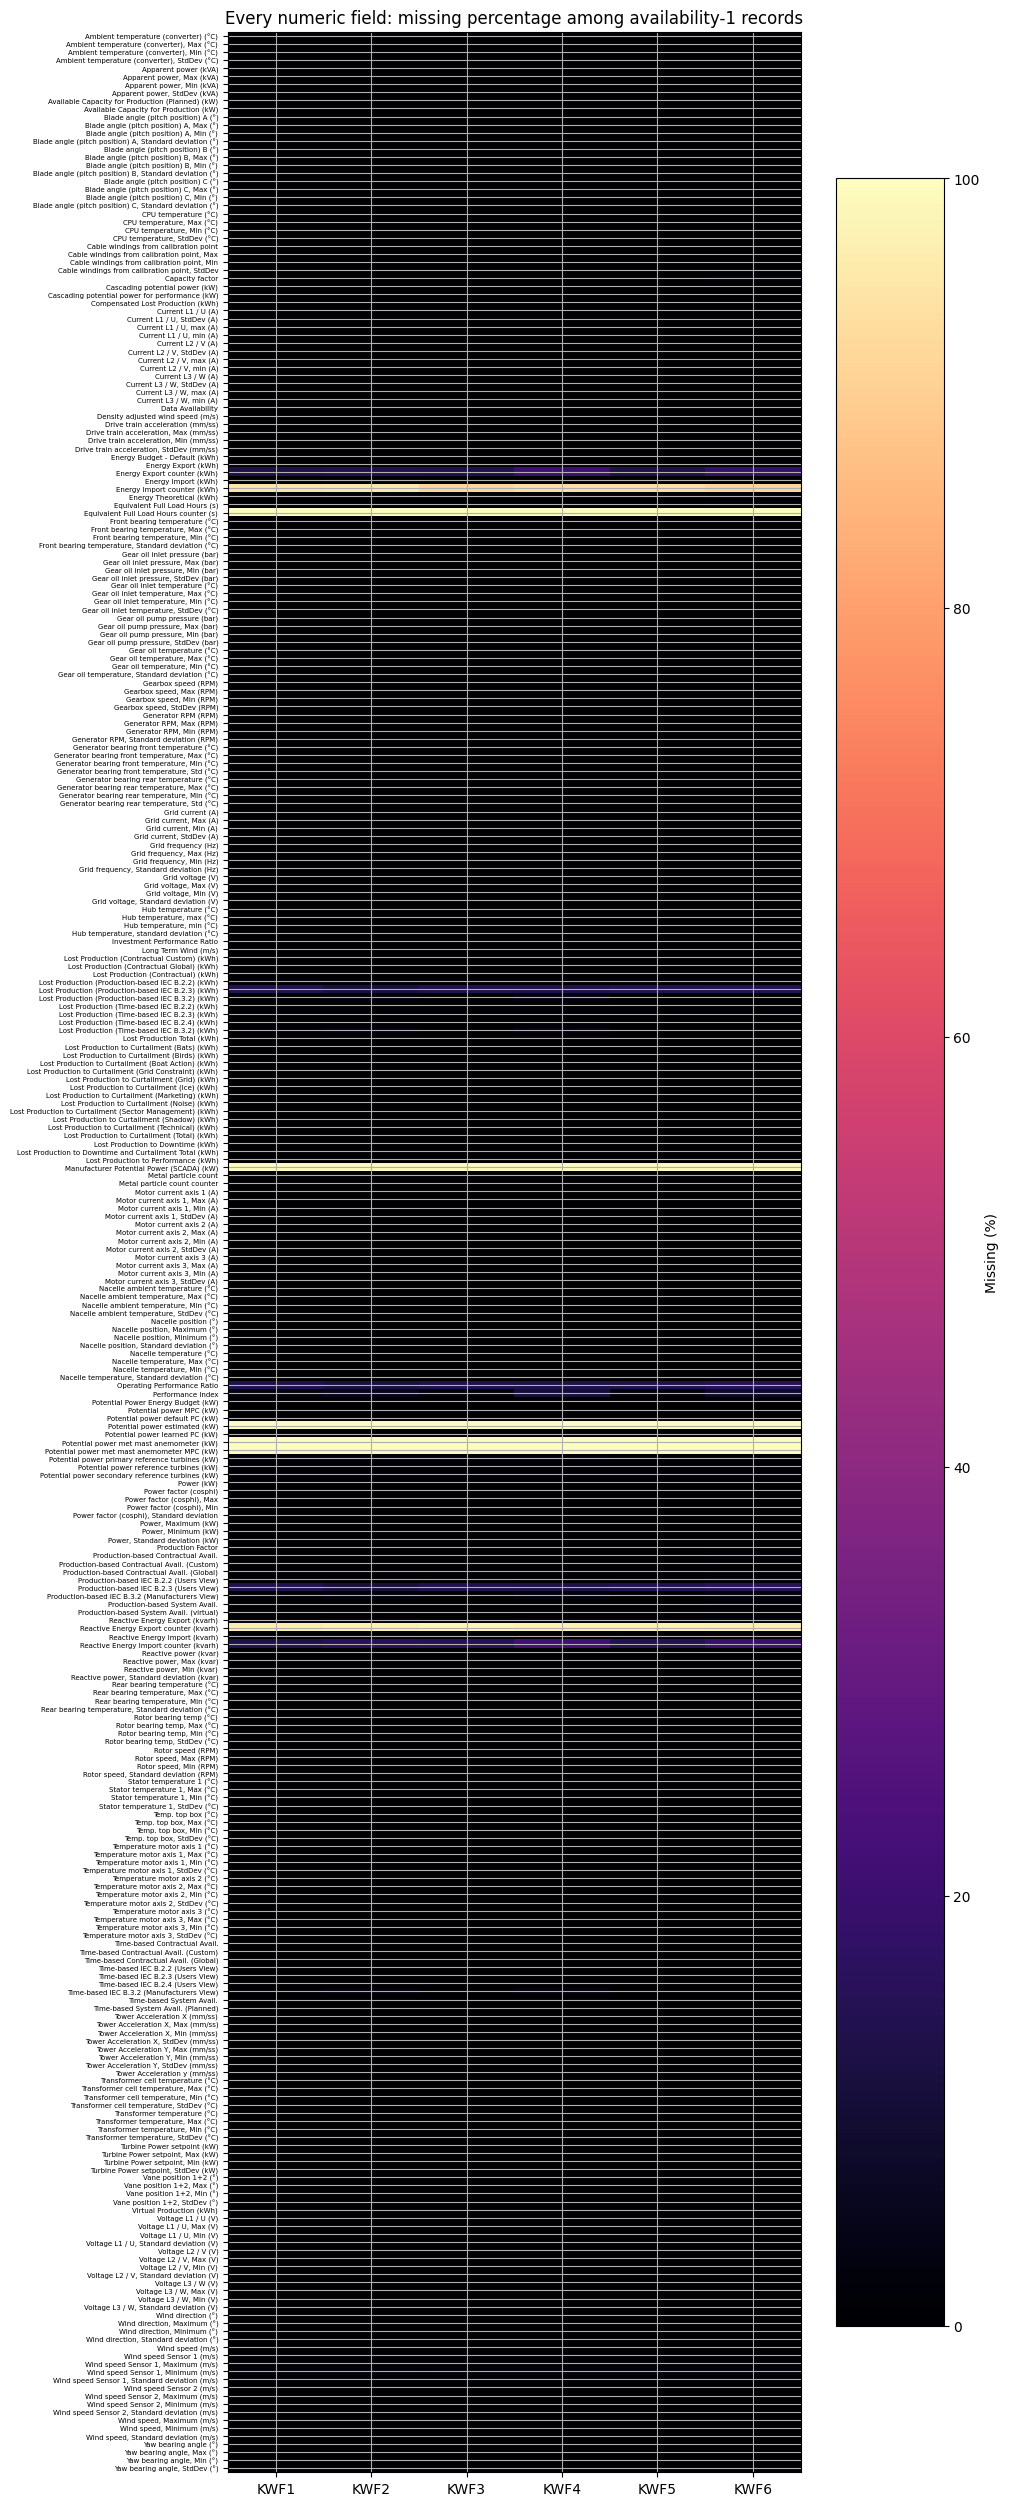

Observed schema sizes: {'KWF1': 303, 'KWF2': 303, 'KWF3': 303, 'KWF4': 303, 'KWF5': 303, 'KWF6': 303}. All ordered schemas identical to KWF1: True. Full-field CSV preserves individual turbine evidence even when the overview plot is dense.

In [3]:
header_map = dict(zip(schemas.turbine, schemas.headers))
all_fields = list(dict.fromkeys(field for headers in header_map.values() for field in headers))
field_presence = pd.DataFrame({t: [field in headers for field in all_fields]
                               for t, headers in header_map.items()}, index=all_fields)
field_presence.index.name = 'field'
reference_turbine = sorted(header_map)[0]
reference_headers = header_map[reference_turbine]
schema_compare = pd.DataFrame([
    {'turbine': t, 'fields': len(headers), 'same_order_as_reference': headers == reference_headers,
     'same_set_as_reference': set(headers) == set(reference_headers),
     'missing_from_reference': json.dumps(sorted(set(reference_headers)-set(headers))),
     'extra_vs_reference': json.dumps(sorted(set(headers)-set(reference_headers)))}
    for t, headers in sorted(header_map.items())])
display(schema_compare)
display(field_presence)
field_presence.to_csv(OUT/'full_schema_presence.csv')
schema_compare.to_csv(OUT/'schema_comparison.csv', index=False)
quality_profile = profile.copy()
quality_profile['all_missing'] = quality_profile['missing'].eq(quality_profile['valid_rows'])
quality_profile['observed_constant'] = quality_profile['constant_or_empty'] & ~quality_profile['all_missing']
quality_profile.to_csv(OUT/'full_field_quality_audit.csv', index=False)
quality_summary = quality_profile.groupby('turbine').agg(
    numeric_fields=('signal','size'), all_missing=('all_missing','sum'),
    observed_constants=('observed_constant','sum'), fields_with_missing=('missing',lambda x: int(x.gt(0).sum())))
display(quality_summary)
display(quality_profile.loc[quality_profile.constant_or_empty].sort_values(['turbine','signal']))
missing_heat = quality_profile.pivot(index='signal', columns='turbine', values='missing_pct')
fig, ax = plt.subplots(figsize=(10, max(12, len(missing_heat)/12)))
im = ax.imshow(missing_heat.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='magma')
ax.set_xticks(range(len(missing_heat.columns)), missing_heat.columns)
ax.set_yticks(range(len(missing_heat)), missing_heat.index, fontsize=5)
ax.set_title('Every numeric field: missing percentage among availability-1 records')
fig.colorbar(im, ax=ax, label='Missing (%)'); fig.tight_layout(); plt.show()
display(Markdown(f"Observed schema sizes: {schema_compare.set_index('turbine').fields.to_dict()}. "
    f"All ordered schemas identical to {reference_turbine}: {bool(schema_compare.same_order_as_reference.all())}. "
    "Full-field CSV preserves individual turbine evidence even when the overview plot is dense."))

### Raw versus usable coverage, monthly exposure, and gap durations

A non-leap year on a 10-minute UTC grid has 52,560 expected positions per turbine. Raw rows,
unique in-year raw positions, availability-1 positions and individual nonmissing sensors are
**four different measures**. Read only timestamp/availability (plus interval energy for the later
check), in chunks; do not reload the 303-field table. Gaps include start/end-of-year gaps.
Reported gap duration counts missing 10-minute slots, not time between surviving endpoints.
Off-grid records are reported rather than rounded. Figures never interpolate absent observations.

,turbine,raw_rows,valid_rows,availability_1_rows,invalid_timestamps,valid_duplicate_rows,available_outside_2022,raw_rows_recount,bad_timestamp_recount,off_grid_raw_rows,duplicate_inyear_raw_rows,unique_raw_2022,unique_available_2022,expected_slots,usable_grid_pct
0,KWF1,52560,52006,52006,0,0,0,52560,0,0,0,52560,52006,52560,98.945967
1,KWF2,52560,52488,52488,0,0,0,52560,0,0,0,52560,52488,52560,99.863014
2,KWF3,52560,52448,52448,0,0,0,52560,0,0,0,52560,52448,52560,99.786910
3,KWF4,52560,52327,52327,0,0,0,52560,0,0,0,52560,52327,52560,99.556697
4,KWF5,52560,52449,52449,0,0,0,52560,0,0,0,52560,52449,52560,99.788813
5,KWF6,52560,52300,52300,0,0,0,52560,0,0,0,52560,52300,52560,99.505327


,,count,sum,median,max
turbine,kind,,,,
KWF1,available,13,92.333333,0.833333,48.833333
KWF2,available,7,12.000000,0.666667,5.000000
KWF3,available,9,18.666667,0.666667,5.333333
KWF4,available,8,38.833333,1.250000,25.500000
KWF5,available,8,18.500000,0.916667,5.666667
KWF6,available,8,43.333333,4.833333,15.833333


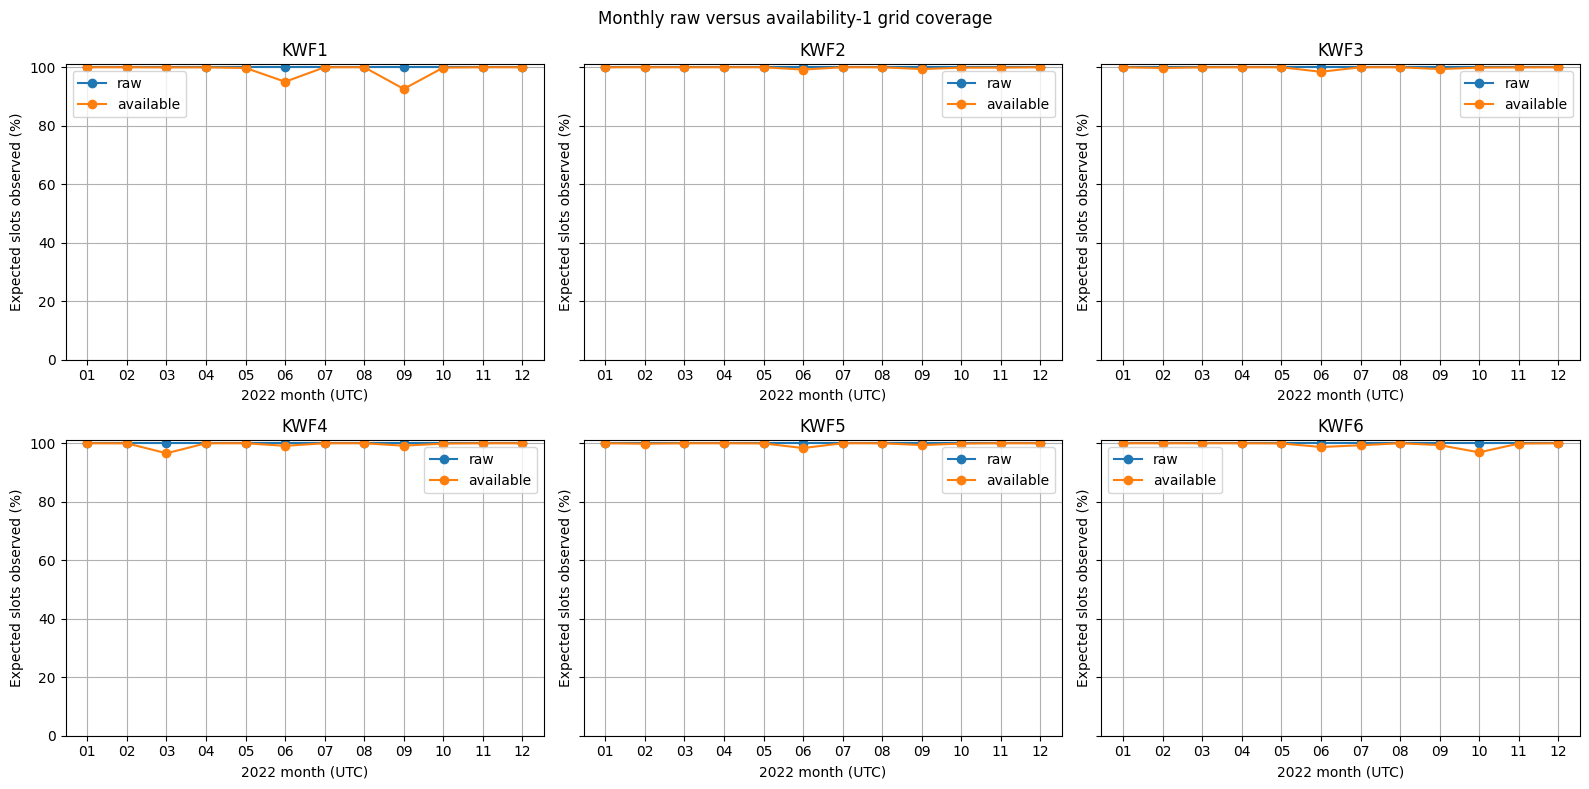

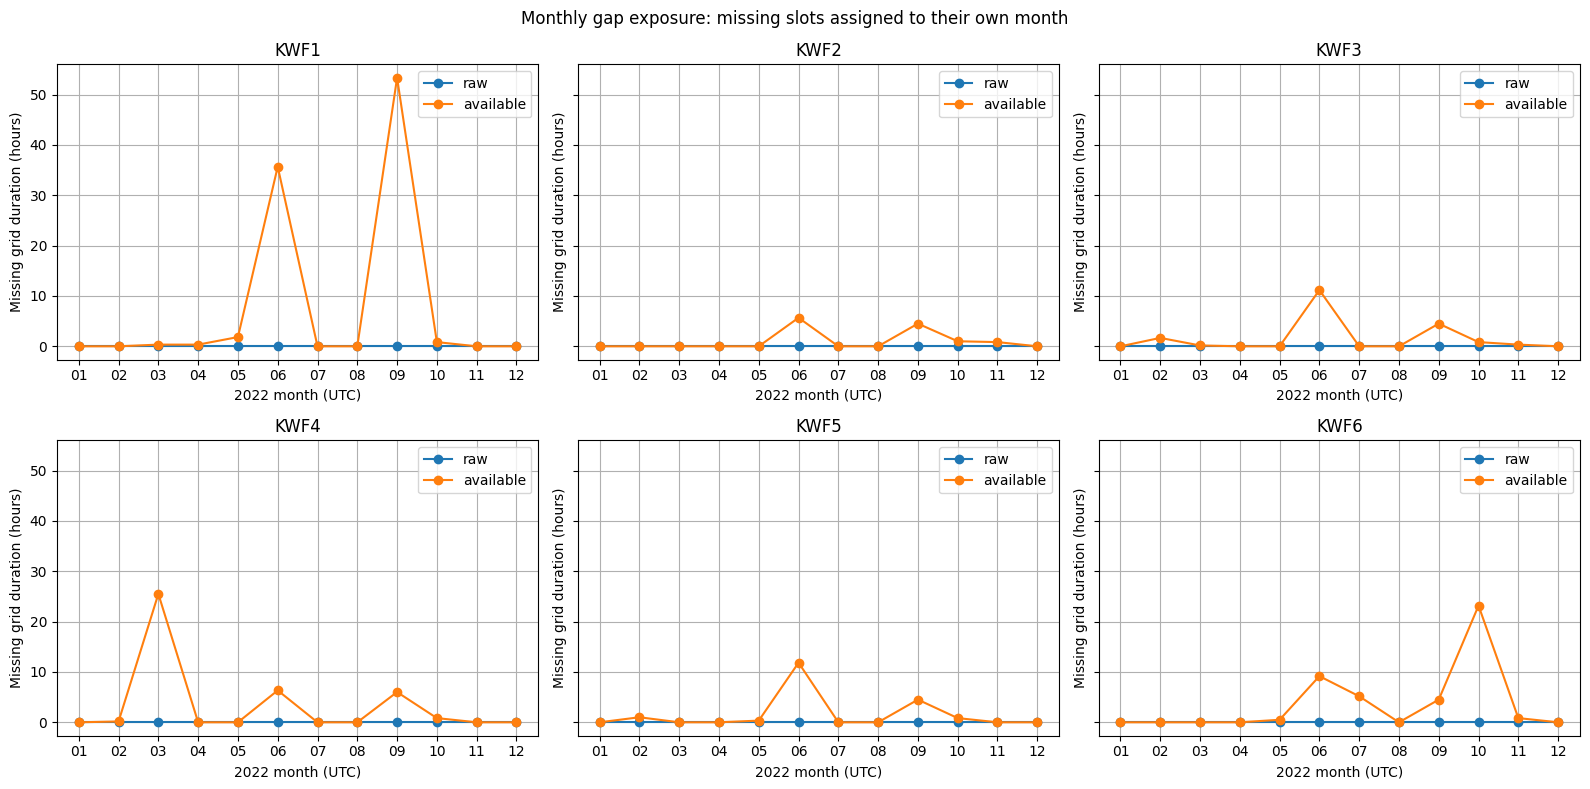

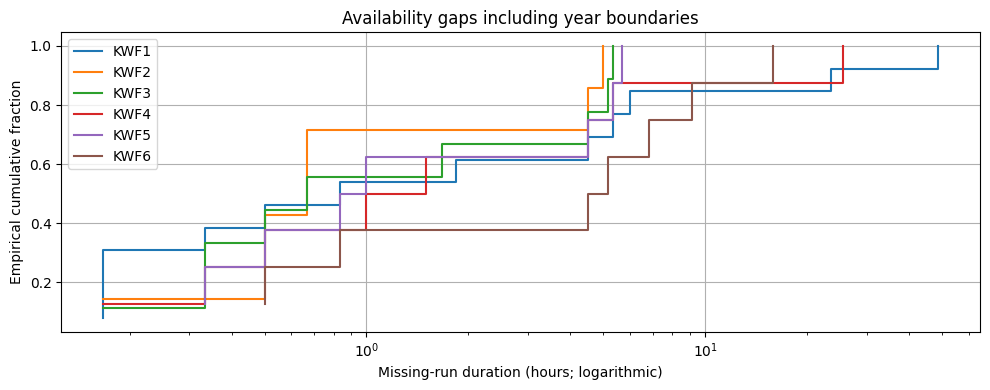

Availability-grid coverage ranges from 98.95% to 99.86%. Off-grid raw records: 0. Coverage is an exposure measure, not a data-quality score or production efficiency.

In [4]:
raw_positions = {}; availability_positions = {}; energy_parts = []; preamble_rows = []
raw_month_rows = []; extra_quality = []
for turbine in sorted(header_map):
    path = source_path(ROOT,turbine,'scada')
    preamble, headers, skiprows = audit_header(path)
    preamble_rows.append({'turbine': turbine, 'preamble': preamble})
    energy_names = [h for h in headers if h.lower().startswith('energy export (')]
    columns = ['# Date and time', 'Data Availability', 'Power (kW)'] + energy_names
    raw_idx = []; valid_idx = []; raw_count = 0; bad_time = 0; off_grid = 0
    for chunk in pd.read_csv(path, skiprows=skiprows, usecols=columns, chunksize=10000, na_values=['NaN']):
        timestamp = pd.to_datetime(chunk['# Date and time'], utc=True, errors='coerce')
        in_year = timestamp.ge(GRID[0]) & timestamp.lt(pd.Timestamp('2023-01-01', tz='UTC'))
        available = pd.to_numeric(chunk['Data Availability'], errors='coerce').eq(1)
        raw_count += len(chunk); bad_time += int(timestamp.isna().sum())
        off_grid += int((in_year & ~timestamp.isin(GRID)).sum())
        raw_idx.extend(timestamp[in_year].tolist()); valid_idx.extend(timestamp[in_year & available].tolist())
        monthly = timestamp[in_year].dt.strftime('%Y-%m').value_counts()
        raw_month_rows.extend({'turbine':turbine, 'month':month, 'raw_rows':int(count)} for month,count in monthly.items())
        if energy_names:
            part = chunk.loc[in_year & available, ['Power (kW)'] + energy_names].apply(pd.to_numeric, errors='coerce')
            part.insert(0, 'timestamp', timestamp[in_year & available]); part.insert(0, 'turbine', turbine)
            energy_parts.append(part)
    raw_positions[turbine] = pd.DatetimeIndex(raw_idx).unique()
    availability_positions[turbine] = pd.DatetimeIndex(valid_idx).unique()
    extra_quality.append({'turbine': turbine, 'raw_rows_recount':raw_count, 'bad_timestamp_recount':bad_time,
                          'off_grid_raw_rows':off_grid, 'duplicate_inyear_raw_rows':len(raw_idx)-len(raw_positions[turbine]),
                          'unique_raw_2022':len(raw_positions[turbine]),
                          'unique_available_2022':len(availability_positions[turbine])})
coverage = audit.merge(pd.DataFrame(extra_quality), on='turbine')
coverage['expected_slots'] = len(GRID)
coverage['usable_grid_pct'] = [100*GRID.isin(availability_positions[t]).sum()/len(GRID) for t in coverage.turbine]
coverage.to_csv(OUT/'raw_valid_coverage.csv', index=False)
(OUT/'scada_preambles.json').write_text(json.dumps(preamble_rows, indent=2), encoding='utf-8')
display(coverage)
gap_rows = []; monthly_rows = []
for turbine in sorted(header_map):
    for kind, positions in [('raw',raw_positions[turbine]), ('available',availability_positions[turbine])]:
        present = pd.Series(GRID.isin(positions), index=GRID)
        runs = (~present).ne((~present).shift()).cumsum()
        for _, run in present[~present].groupby(runs[~present]):
            gap_rows.append({'turbine':turbine, 'kind':kind, 'start':run.index[0],
                             'end_exclusive':run.index[-1]+pd.Timedelta(minutes=10),
                             'missing_slots':len(run), 'duration_hours':len(run)/6})
        for month, values in present.groupby(present.index.strftime('%Y-%m')):
            monthly_rows.append({'turbine':turbine, 'kind':kind, 'month':month,
                                 'positions':int(values.sum()), 'expected':len(values), 'coverage_pct':100*values.mean()})
gaps = pd.DataFrame(gap_rows, columns=['turbine','kind','start','end_exclusive','missing_slots','duration_hours'])
monthly_coverage = pd.DataFrame(monthly_rows)
gaps.to_csv(OUT/'coverage_gap_runs.csv', index=False)
pd.DataFrame(raw_month_rows).groupby(['turbine','month']).raw_rows.sum().to_csv(OUT/'monthly_raw_row_counts.csv')
display(gaps.groupby(['turbine','kind']).duration_hours.agg(['count','sum','median','max']))
fig, axes = plt.subplots(2,3, figsize=(16,8), sharey=True)
for ax, turbine in zip(axes.flat, sorted(header_map)):
    for kind in ['raw','available']:
        part = monthly_coverage.query('turbine == @turbine and kind == @kind')
        ax.plot(part.month.str[-2:], part.coverage_pct, marker='o', label=kind)
    ax.set(title=turbine, xlabel='2022 month (UTC)', ylabel='Expected slots observed (%)', ylim=(0,101)); ax.legend()
fig.suptitle('Monthly raw versus availability-1 grid coverage'); fig.tight_layout(); plt.show()
monthly_coverage['missing_hours'] = (monthly_coverage.expected-monthly_coverage.positions)/6
monthly_coverage.to_csv(OUT/'monthly_coverage.csv', index=False)
fig, axes = plt.subplots(2,3, figsize=(16,8), sharey=True)
for ax, turbine in zip(axes.flat, sorted(header_map)):
    for kind in ['raw','available']:
        part = monthly_coverage.query('turbine == @turbine and kind == @kind')
        ax.plot(part.month.str[-2:], part.missing_hours, marker='o', label=kind)
    ax.set(title=turbine, xlabel='2022 month (UTC)', ylabel='Missing grid duration (hours)'); ax.legend()
fig.suptitle('Monthly gap exposure: missing slots assigned to their own month'); fig.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(10,4))
for turbine in sorted(header_map):
    duration = gaps.loc[(gaps.turbine==turbine)&(gaps.kind=='available'),'duration_hours'].sort_values()
    if len(duration): ax.step(duration, np.arange(1,len(duration)+1)/len(duration), where='post', label=turbine)
ax.set(xlabel='Missing-run duration (hours; logarithmic)', ylabel='Empirical cumulative fraction', xscale='log', title='Availability gaps including year boundaries')
if len(gaps): ax.legend()
fig.tight_layout(); plt.show()
display(Markdown(f"Availability-grid coverage ranges from {coverage.usable_grid_pct.min():.2f}% "
    f"to {coverage.usable_grid_pct.max():.2f}%. Off-grid raw records: {coverage.off_grid_raw_rows.sum():,}. "
    "Coverage is an exposure measure, not a data-quality score or production efficiency."))

### UTC, UK daylight saving, and timestamp interpretation

The exported preamble states **Time zone: UTC**. Parse timestamps as UTC, not naive UK local time.
UTC has neither a missing spring hour nor a repeated autumn hour. `Europe/London` conversion changes
local clock labels in summer but must not change record count, ordering or instant identity.
2022 UK clock changes occur on 27 March and 30 October; display converted instants below.
The 10-minute value is an aggregate; without a documented interval-label convention, avoid asserting
that a timestamp labels the beginning rather than end of its averaging window.

In [5]:
dst_examples = pd.DataFrame({'UTC':pd.to_datetime(['2022-03-27 00:50','2022-03-27 01:00',
                                                 '2022-10-30 00:50','2022-10-30 01:00'], utc=True)})
dst_examples['Europe/London'] = dst_examples.UTC.dt.tz_convert('Europe/London')
display(dst_examples)

,UTC,Europe/London
0,2022-03-27 00:50:00+00:00,2022-03-27 00:50:00+00:00
1,2022-03-27 01:00:00+00:00,2022-03-27 02:00:00+01:00
2,2022-10-30 00:50:00+00:00,2022-10-30 01:50:00+01:00
3,2022-10-30 01:00:00+00:00,2022-10-30 01:00:00+00:00


### Selected signals: missingness, units, power curves, and distributions

Descriptive statistics retain observed negative power, high pitch, and unusual thermal values;
no operating-state thresholds are applied in this audit. Plotting subsamples are display-only.
A turbine power curve mixes wind response, curtailment, downtime, density and measurement noise;
its shape is not a fault label. Marginal distributions alone discard time order.
Direction is circular: arithmetic quantiles are only a raw summary, not circular estimates.

,wind,direction,power,reactive,ambient,bearing,oil,rotor,generator,pitch,frequency,setpoint
turbine,,,,,,,,,,,,
KWF1,0.0,0.0,0.0,0.0,0.082683,0.0,0.0,0.0,0.0,0.082683,0.0,0.082683
KWF2,0.0,0.0,0.0,0.0,0.081923,0.0,0.0,0.0,0.0,0.081923,0.0,0.081923
KWF3,0.0,0.0,0.0,0.0,0.081986,0.0,0.0,0.0,0.0,0.081986,0.0,0.081986
KWF4,0.0,0.0,0.0,0.0,0.082176,0.0,0.0,0.0,0.0,0.082176,0.0,0.082176
KWF5,0.0,0.0,0.0,0.0,0.081984,0.0,0.0,0.0,0.0,0.081984,0.0,0.081984
KWF6,0.0,0.0,0.0,0.0,0.082218,0.0,0.0,0.0,0.0,0.082218,0.0,0.082218


wind                                                              \
           count      mean       std       min        1%       25%       50%   
turbine                                                                        
KWF1     52006.0  5.968575  2.684725  0.000000  1.057481  3.957004  5.840614   
KWF2     52488.0  6.343382  2.763370  0.000000  1.107994  4.344982  6.248294   
KWF3     52448.0  5.893558  2.637734  0.114263  1.057106  3.974789  5.701442   
KWF4     52327.0  6.094167  2.775094  0.167119  1.024268  4.100101  5.904757   
KWF5     52449.0  5.837899  2.659435  0.000000  1.043750  3.884381  5.572191   
KWF6     52300.0  5.538435  2.514224  0.166182  0.979362  3.721536  5.289568   

                                        direction                         \
              75%        99%        max     count        mean        std   
turbine                                                                    
KWF1     7.656175  13.120095  23.683294   52006.0  202.519777  89.365975   
KWF2     8.064383  13.712188  22.701469   52488.0  203.803825  89.301500   
KWF3     7.474945  13.268276  21.936706   52448.0  204.442589  89.924413   
KWF4     7.762139  13.804644  24.154331   52327.0  201.650445  90.143218   
KWF5     7.417211  13.304767  22.575900   52449.0  199.980321  89.274515   
KWF6     6.988477  12.699688  21.090255   52300.0  204.144465  90.588834   

                             ...  frequency                                   \
              min        1%  ...        25%        50%        75%        99%   
turbine                      ...                                               
KWF1     0.005812  7.866150  ...  49.950622  49.991524  50.032280  50.106688   
KWF2     0.005065  7.235926  ...  49.950244  49.991190  50.031934  50.106311   
KWF3     0.017864  6.768973  ...  49.950600  49.991390  50.032176  50.106466   
KWF4     0.031842  9.394191  ...  49.950579  49.991575  50.032215  50.106663   
KWF5     0.006609  7.602222  ...  49.950764  49.991620  50.032425  50.106575   
KWF6     0.001602  7.727308  ...  49.950674  49.991677  50.032410  50.106770   

                   setpoint                                          \
               max    count         mean         std     min     1%   
turbine                                                               
KWF1     50.196360  51963.0  1343.764620  501.954250  205.00  412.0   
KWF2     50.195755  52445.0  1331.474445  505.790656  412.00  412.0   
KWF3     50.196150  52405.0  1337.283804  505.869809  412.00  412.0   
KWF4     50.196105  52284.0  1238.731528  530.861237  412.00  412.0   
KWF5     50.196085  52406.0  1340.167390  500.644145  380.95  412.0   
KWF6     50.194089  52257.0  1284.450747  542.560534  412.00  412.0   

                                                                
                 25%          50%          75%     99%     max  
turbine                                                         
KWF1     1015.723096  1318.400000  1713.385355  2060.0  2060.0  
KWF2     1008.224573  1304.407062  1692.100677  2060.0  2060.0  
KWF3     1007.578122  1310.180389  1709.256134  2060.0  2060.0  
KWF4      937.278319  1219.214792  1666.000000  2060.0  2060.0  
KWF5     1014.422907  1309.962453  1704.439059  2060.0  2060.0  
KWF6      946.215274  1267.502673  1680.289941  2060.0  2060.0  

[6 rows x 120 columns]

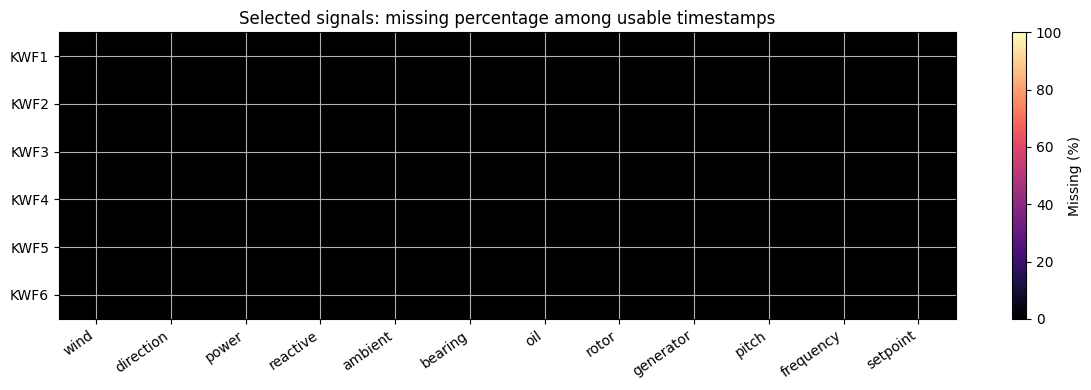

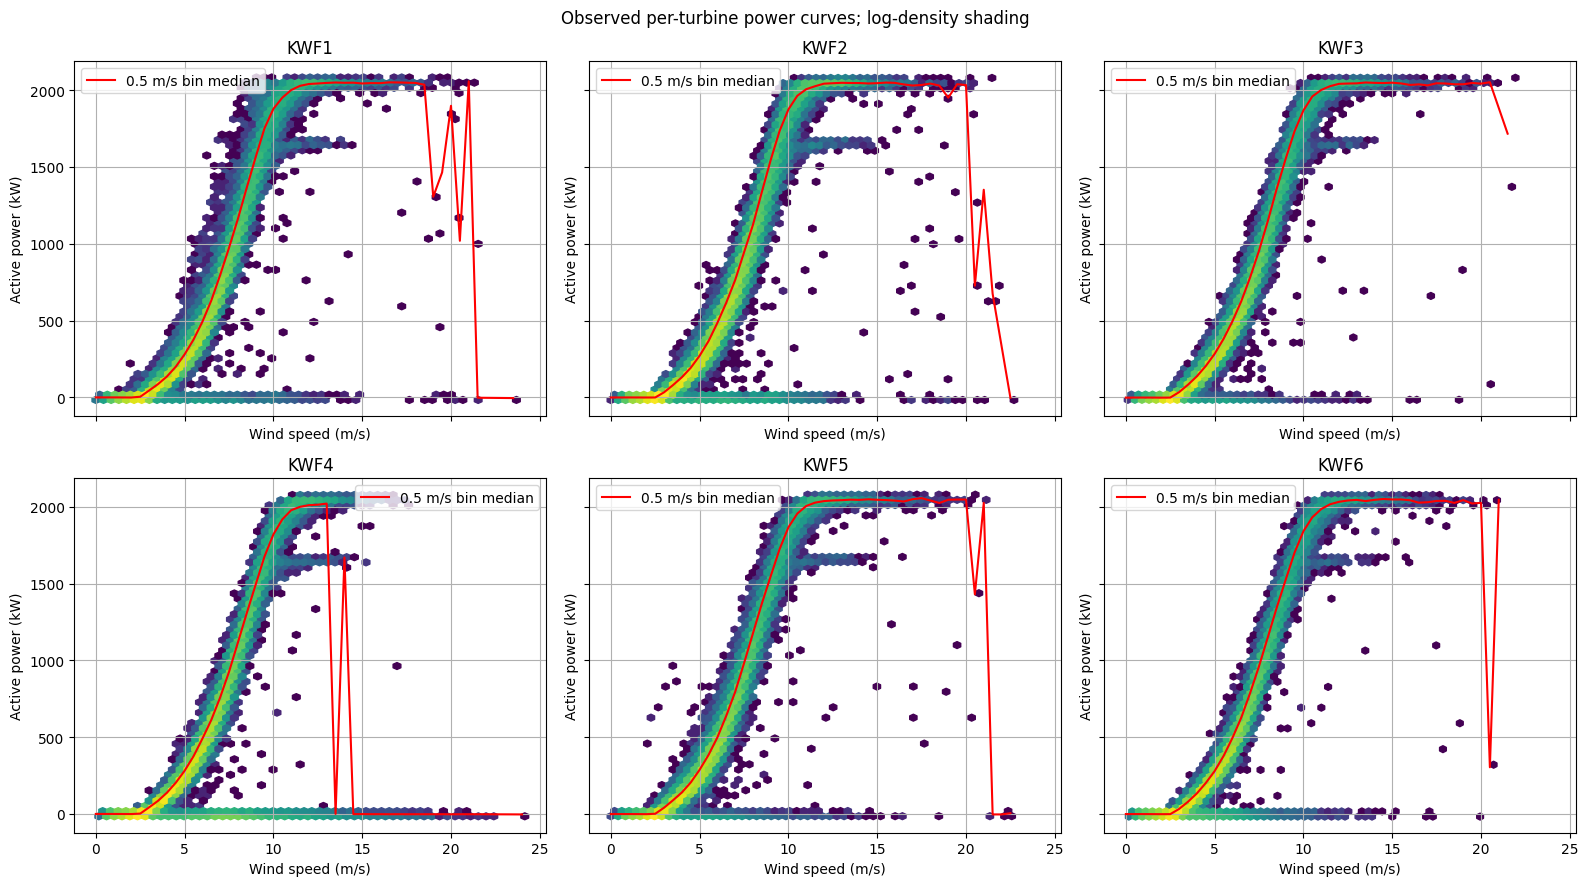

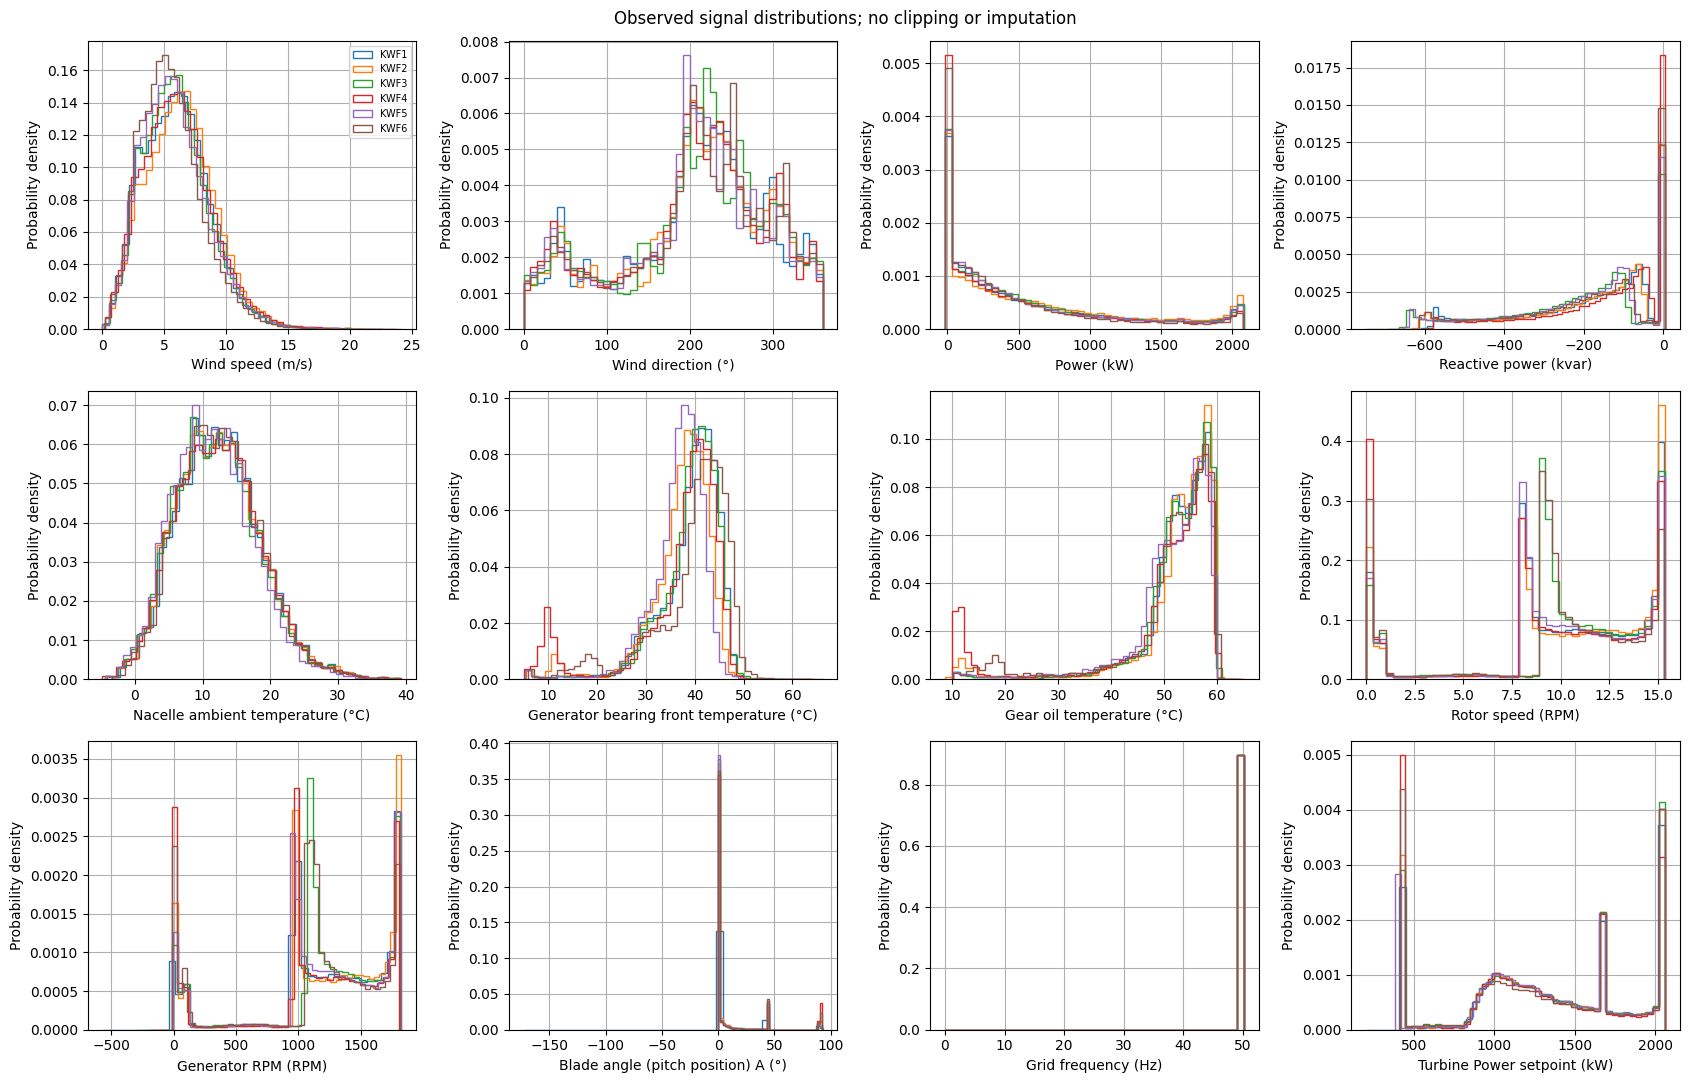

In [6]:
selected_missing = df.groupby('turbine')[list(SIGNALS)].agg(lambda s: 100*s.isna().mean())
selected_describe = df.groupby('turbine')[list(SIGNALS)].describe(percentiles=[.01,.25,.5,.75,.99])
selected_missing.to_csv(OUT/'selected_missing_pct.csv'); selected_describe.to_csv(OUT/'selected_descriptive.csv')
display(selected_missing); display(selected_describe)
fig, ax = plt.subplots(figsize=(12,4))
im=ax.imshow(selected_missing.to_numpy(), aspect='auto', vmin=0,vmax=100,cmap='magma')
ax.set_xticks(range(len(SIGNALS)), list(SIGNALS), rotation=35, ha='right')
ax.set_yticks(range(len(selected_missing)),selected_missing.index)
ax.set_title('Selected signals: missing percentage among usable timestamps')
fig.colorbar(im,ax=ax,label='Missing (%)'); fig.tight_layout(); plt.show()
fig, axes = plt.subplots(2,3,figsize=(16,9),sharex=True,sharey=True)
for ax,(turbine,part) in zip(axes.flat,df.groupby('turbine',sort=True)):
    observed = part[['wind','power']].dropna()
    ax.hexbin(observed.wind,observed.power,gridsize=55,mincnt=1,bins='log',cmap='viridis')
    bins = np.floor(observed.wind*2)/2
    median_curve = observed.groupby(bins).power.median()
    ax.plot(median_curve.index,median_curve, color='red',lw=1.5,label='0.5 m/s bin median')
    ax.set(title=turbine,xlabel='Wind speed (m/s)',ylabel='Active power (kW)'); ax.legend()
fig.suptitle('Observed per-turbine power curves; log-density shading'); fig.tight_layout(); plt.show()
fig, axes = plt.subplots(3,4,figsize=(17,11))
for ax,(short,header) in zip(axes.flat,SIGNALS.items()):
    for turbine,part in df.groupby('turbine',sort=True):
        values=part[short].dropna()
        if len(values): ax.hist(values,bins=45,density=True,histtype='step',label=turbine)
    ax.set(xlabel=header,ylabel='Probability density')
axes.flat[0].legend(fontsize=7)
fig.suptitle('Observed signal distributions; no clipping or imputation'); fig.tight_layout(); plt.show()

### Time dependence and seasonal cross-turbine association

Daily means expose seasonal changes but hide within-day transients; save daily counts alongside
means so sparse days remain visible. Autocorrelation uses **exact calendar lags** on each turbine's
2022 grid, pairwise-complete data, and no interpolation. A lag of 144 means one day, not 144 retained
records. Strong autocorrelation reduces effective independent sample size and motivates chronological
train/validation separation. Seasonal correlations align simultaneous UTC timestamps and report pair
counts; they are association, not causation, and shared wind/weather can dominate them. Raw angles
are excluded from Pearson summaries because 359° and 1° are close, not opposite.

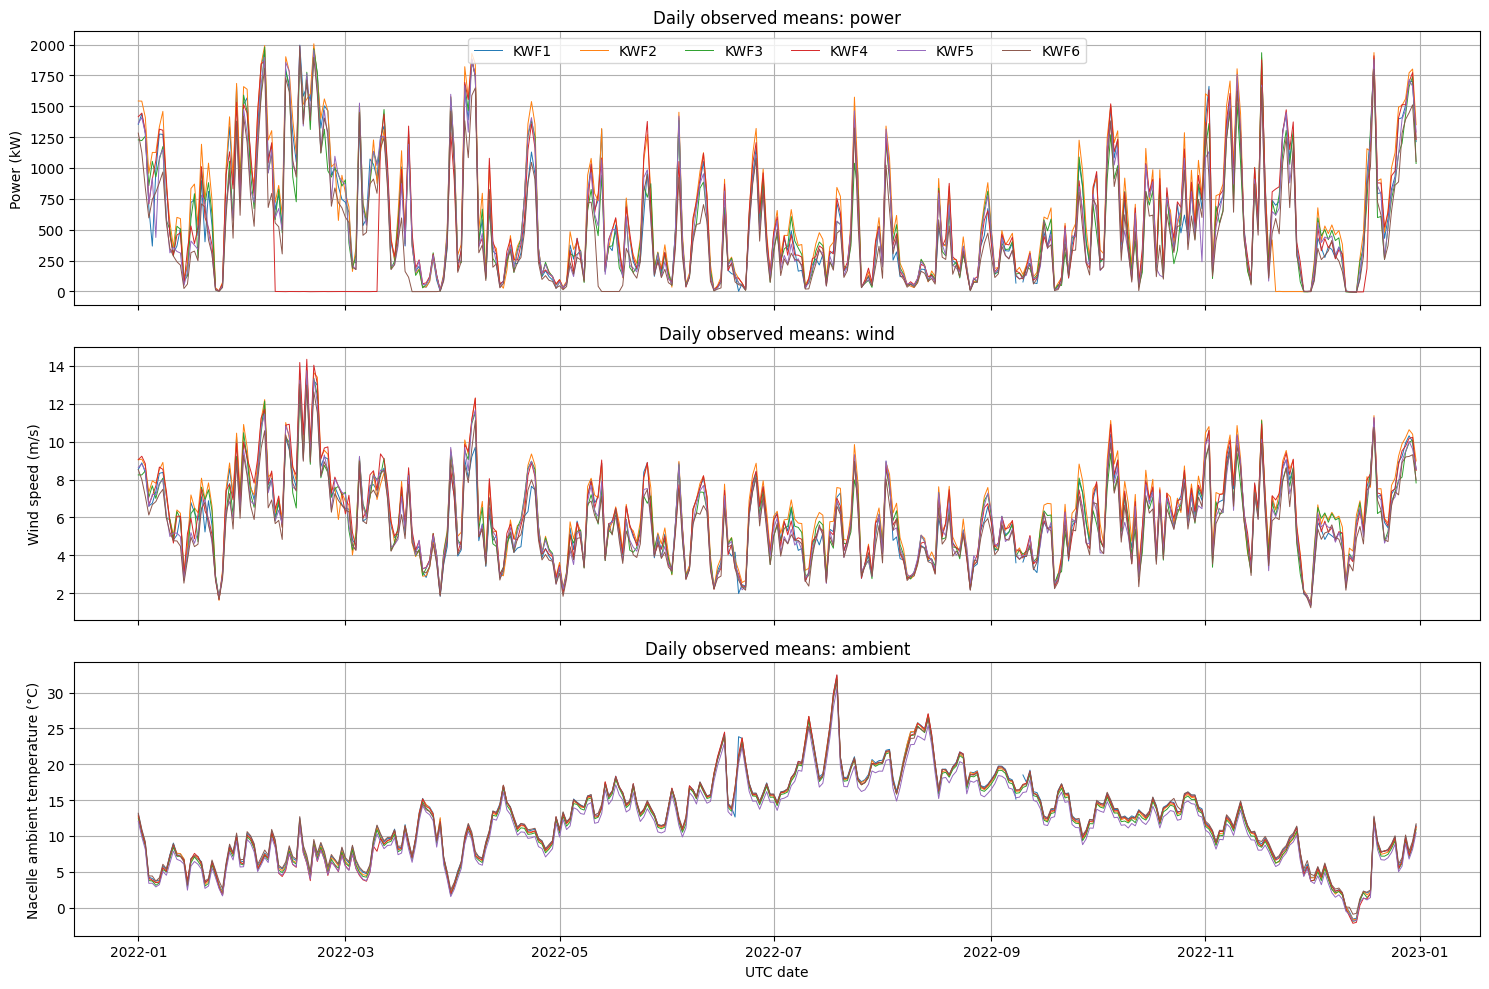

,turbine,signal,lag_slots,lag_hours,pairs,correlation
0,KWF1,wind,1,0.166667,51992,0.966055
1,KWF1,wind,3,0.500000,51973,0.927461
2,KWF1,wind,6,1.000000,51950,0.894064
3,KWF1,wind,18,3.000000,51877,0.800373
4,KWF1,wind,36,6.000000,51783,0.692365
...,...,...,...,...,...,...
211,KWF6,bearing,36,6.000000,52087,0.752382
212,KWF6,bearing,72,12.000000,51991,0.655319
213,KWF6,bearing,144,24.000000,51896,0.576855
214,KWF6,bearing,288,48.000000,51755,0.442088


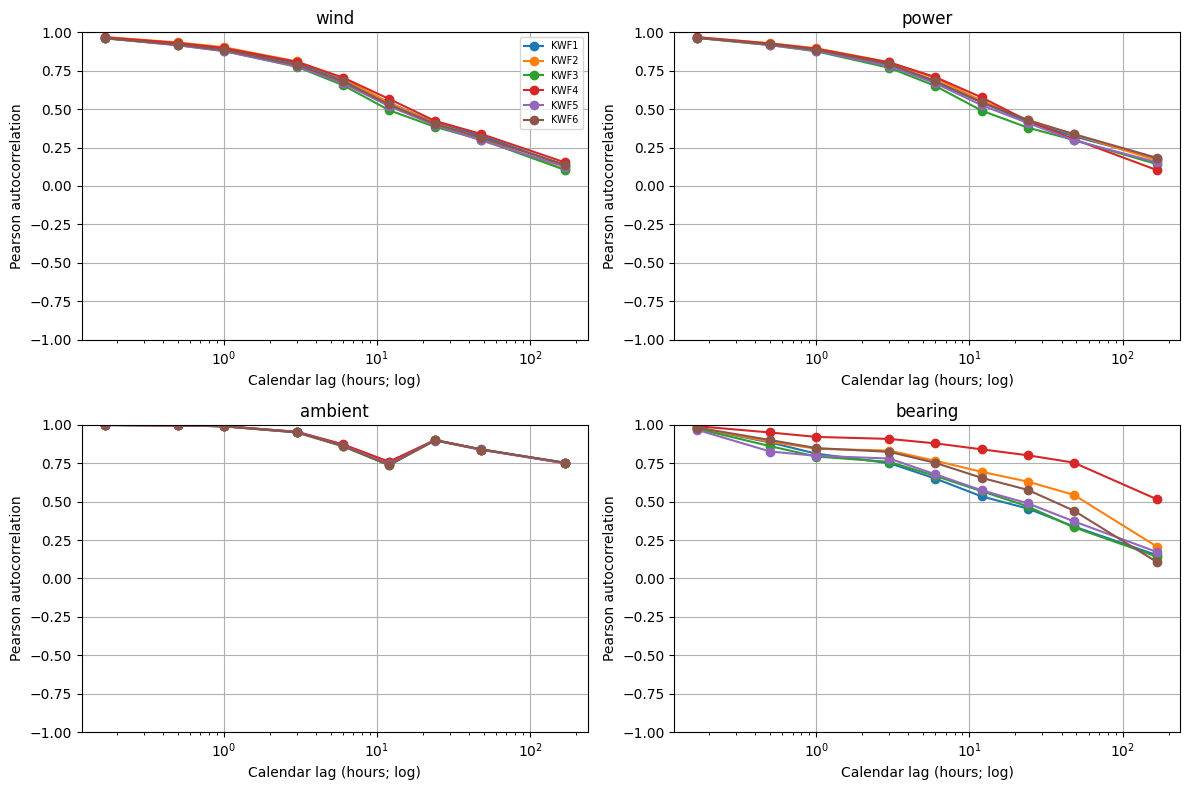

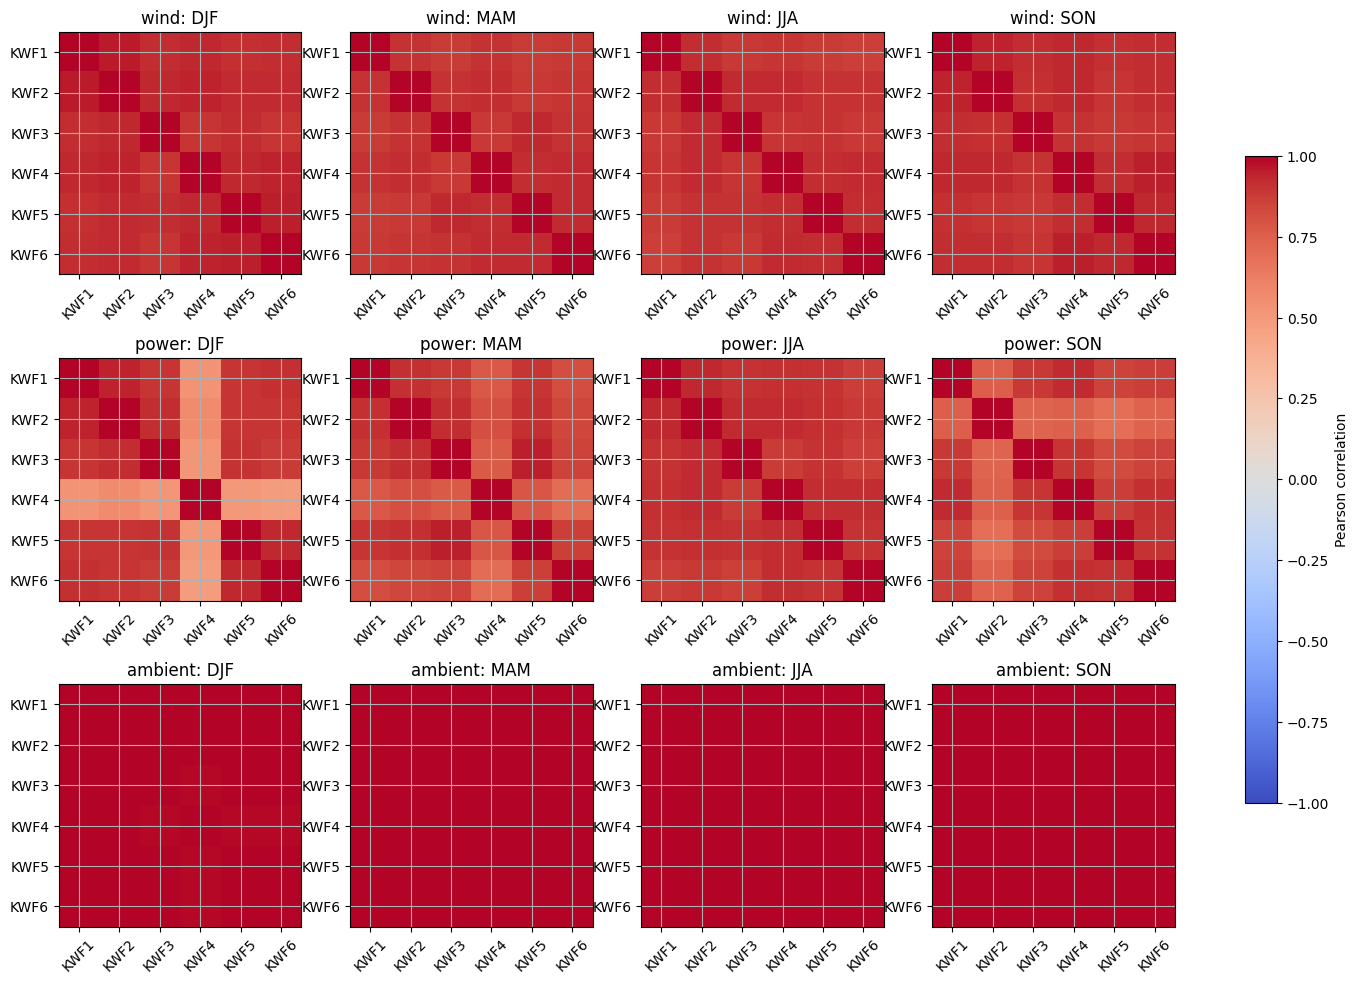

,signal,season,turbine_a,turbine_b,pairs,correlation
1,wind,DJF,KWF1,KWF2,12960,0.958743
2,wind,DJF,KWF1,KWF3,12950,0.918454
3,wind,DJF,KWF1,KWF4,12959,0.937108
4,wind,DJF,KWF1,KWF5,12954,0.913673
5,wind,DJF,KWF1,KWF6,12960,0.917896
...,...,...,...,...,...,...
412,ambient,SON,KWF3,KWF5,13068,0.997803
413,ambient,SON,KWF3,KWF6,12931,0.997509
418,ambient,SON,KWF4,KWF5,13061,0.997633
419,ambient,SON,KWF4,KWF6,12924,0.997452


DJF here combines January–February and December **within 2022**; it is not one contiguous winter. These descriptive audits use the whole year; no learned preprocessing parameters are fitted here.

In [7]:
daily_mean = df.set_index('timestamp').groupby('turbine')[list(SIGNALS)].resample('D').mean()
daily_count = df.set_index('timestamp').groupby('turbine')[list(SIGNALS)].resample('D').count()
daily_mean.to_csv(OUT/'daily_selected_means.csv'); daily_count.to_csv(OUT/'daily_selected_counts.csv')
fig,axes=plt.subplots(3,1,figsize=(15,10),sharex=True)
for ax,signal in zip(axes,['power','wind','ambient']):
    for turbine in sorted(header_map):
        part=daily_mean.loc[turbine]
        ax.plot(part.index,part[signal],lw=.7,label=turbine)
    ax.set(ylabel=SIGNALS[signal],title='Daily observed means: '+signal)
axes[0].legend(ncol=6); axes[-1].set_xlabel('UTC date'); fig.tight_layout(); plt.show()
acf_rows=[]
for turbine,part in df.groupby('turbine',sort=True):
    gridded=part.set_index('timestamp').reindex(GRID)
    for signal in ['wind','power','ambient','bearing']:
        for lag in [1,3,6,18,36,72,144,288,1008]:
            x=gridded[signal]; shifted=x.shift(lag); paired=x.notna() & shifted.notna()
            acf_rows.append({'turbine':turbine,'signal':signal,'lag_slots':lag,'lag_hours':lag/6,
                             'pairs':int(paired.sum()),'correlation':x.corr(shifted)})
acf=pd.DataFrame(acf_rows); acf.to_csv(OUT/'calendar_lag_autocorrelation.csv',index=False)
display(acf)
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,signal in zip(axes.flat,['wind','power','ambient','bearing']):
    for turbine in sorted(header_map):
        part=acf.loc[(acf.signal==signal)&(acf.turbine==turbine)]
        ax.plot(part.lag_hours,part.correlation,marker='o',label=turbine)
    ax.set(title=signal,xlabel='Calendar lag (hours; log)',ylabel='Pearson autocorrelation',xscale='log',ylim=(-1,1))
axes.flat[0].legend(fontsize=7); fig.tight_layout(); plt.show()
season_names={12:'DJF',1:'DJF',2:'DJF',3:'MAM',4:'MAM',5:'MAM',6:'JJA',7:'JJA',8:'JJA',9:'SON',10:'SON',11:'SON'}
season_corr_rows=[]
fig,axes=plt.subplots(3,4,figsize=(18,12))
for row,signal in enumerate(['wind','power','ambient']):
    aligned=df.pivot(index='timestamp',columns='turbine',values=signal).reindex(GRID)
    for col,season in enumerate(['DJF','MAM','JJA','SON']):
        part=aligned.loc[aligned.index.month.map(season_names)==season]
        corr=part.corr(min_periods=100); valid=part.notna().astype('int64'); pairs=valid.T @ valid
        for a in corr.index:
            for b in corr.columns:
                season_corr_rows.append({'signal':signal,'season':season,'turbine_a':a,'turbine_b':b,
                                         'pairs':int(pairs.loc[a,b]),'correlation':corr.loc[a,b]})
        ax=axes[row,col]; im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
        ax.set(title=f'{signal}: {season}',xticks=range(len(corr)),yticks=range(len(corr)),
               xticklabels=corr.columns,yticklabels=corr.index)
        ax.tick_params(axis='x',rotation=45)
fig.colorbar(im,ax=axes.ravel().tolist(),label='Pearson correlation',shrink=.7); plt.show()
season_correlations=pd.DataFrame(season_corr_rows)
season_correlations.to_csv(OUT/'seasonal_cross_turbine_correlations.csv',index=False)
display(season_correlations.loc[season_correlations.turbine_a < season_correlations.turbine_b])
display(Markdown('DJF here combines January–February and December **within 2022**; it is not one contiguous winter. '
                 'These descriptive audits use the whole year; no learned preprocessing parameters are fitted here.'))

### Energy export versus ten-minute power: empirical unit check

For constant average power over ten minutes, $E=P/6$ in kWh. Compare the **named Energy Export**
field with this prediction on simultaneous available observations. A cumulative energy counter
requires differencing and reset handling; do not compare its absolute magnitude with interval energy.
The check below reports interval residuals, ratios away from zero power, and aggregate discrepancies.
Import/negative-power intervals need not match export-only energy. Meter precision, averaging,
rounding and timestamp conventions can also create residuals. This is evidence about the export,
not a repair of the metadata or proof of exact interval semantics.

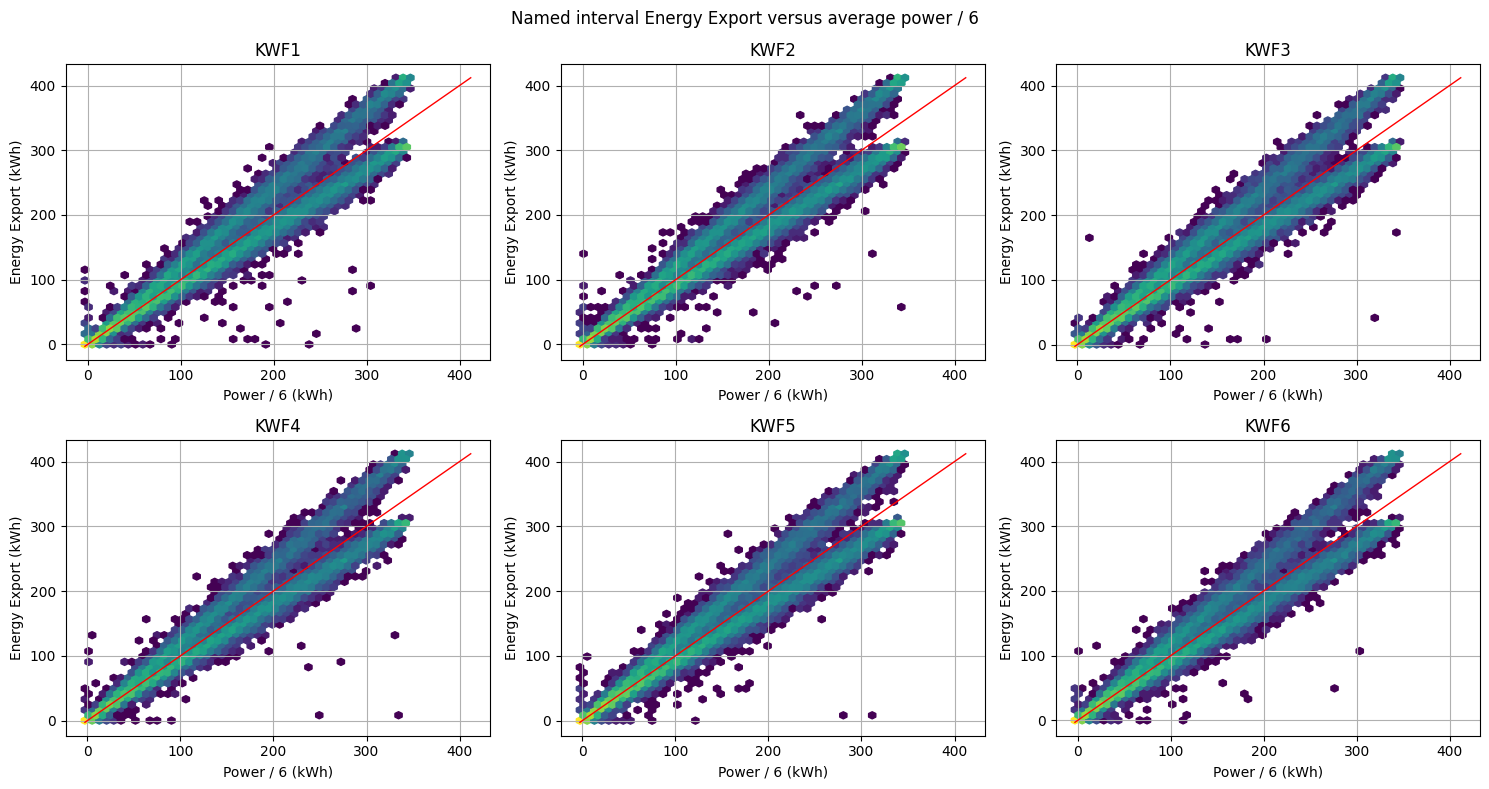

,turbine,energy_field,pairs,positive_pairs,median_ratio_positive,mean_abs_residual_kWh,median_abs_residual_kWh,p95_abs_residual_kWh,correlation,sum_export_kWh,sum_power_over_6_kWh,sum_residual_kWh
0,KWF1,Energy Export (kWh),52000,44824,0.932976,13.797609,7.472497,48.435990,0.978177,5.162558e+06,5.159827e+06,2730.958260
1,KWF2,Energy Export (kWh),52485,44886,0.928889,14.829300,8.571756,51.551951,0.977858,5.648216e+06,5.645361e+06,2854.880706
2,KWF3,Energy Export (kWh),52443,44902,0.934245,13.215799,7.194884,45.892177,0.978752,4.975176e+06,4.969893e+06,5282.674194
3,KWF4,Energy Export (kWh),52323,41253,0.932538,11.964472,5.807745,43.435742,0.980052,4.499429e+06,4.496394e+06,3034.937286
4,KWF5,Energy Export (kWh),52446,45191,0.935580,12.987884,6.643878,46.295709,0.979161,4.892143e+06,4.888801e+06,3341.920042
5,KWF6,Energy Export (kWh),51524,41951,0.937070,11.232115,5.460805,41.049793,0.980251,4.128291e+06,4.123638e+06,4652.802650


Observed positive-power median export/predicted ratios range 0.9289–0.9371; median absolute residuals range 5.461–8.572 kWh. Inspect residuals before claiming equality.

In [8]:
energy_checks=[]
if energy_parts:
    energy_audit=pd.concat(energy_parts,ignore_index=True)
    energy_columns=[c for c in energy_audit if c.lower().startswith('energy export (')]
    fig,axes=plt.subplots(2,3,figsize=(15,8))
    for ax,turbine in zip(axes.flat,sorted(header_map)):
        for energy_column in energy_columns:
            pair=energy_audit.loc[energy_audit.turbine==turbine,['Power (kW)',energy_column]].dropna()
            expected=pair['Power (kW)']/6; observed=pair[energy_column]; residual=observed-expected
            positive=expected.gt(1)
            energy_checks.append({'turbine':turbine,'energy_field':energy_column,'pairs':len(pair),
                'positive_pairs':int(positive.sum()),'median_ratio_positive':(observed[positive]/expected[positive]).median(),
                'mean_abs_residual_kWh':residual.abs().mean(),'median_abs_residual_kWh':residual.abs().median(),
                'p95_abs_residual_kWh':residual.abs().quantile(.95),
                'correlation':expected.corr(observed),'sum_export_kWh':observed.sum(),
                'sum_power_over_6_kWh':expected.sum(), 'sum_residual_kWh':residual.sum()})
            if len(pair):
                ax.hexbin(expected,observed,gridsize=45,mincnt=1,bins='log')
                lo=min(expected.min(),observed.min()); hi=max(expected.max(),observed.max())
                ax.plot([lo,hi],[lo,hi],color='red',lw=1)
        ax.set(title=turbine,xlabel='Power / 6 (kWh)',ylabel='Energy Export (kWh)')
    fig.suptitle('Named interval Energy Export versus average power / 6'); fig.tight_layout(); plt.show()
energy_check=pd.DataFrame(energy_checks)
energy_check.to_csv(OUT/'energy_power_empirical_check.csv',index=False)
display(energy_check)
if energy_check.empty:
    display(Markdown('No exact base Energy Export header found: interval equality cannot be checked from these fields.'))
else:
    display(Markdown(f"Observed positive-power median export/predicted ratios range "
        f"{energy_check.median_ratio_positive.min():.4f}–{energy_check.median_ratio_positive.max():.4f}; "
        f"median absolute residuals range {energy_check.median_abs_residual_kWh.min():.3f}–"
        f"{energy_check.median_abs_residual_kWh.max():.3f} kWh. Inspect residuals before claiming equality."))

### Event context: real codes, categories, schema and duration integrity

Events are a separate irregular log, not ten-minute model features. Informational messages may
have no end or duration and are point events, not zero-duration faults. Codes are categories, not
ordered numeric severities. Count messages by turbine/code/status/category, retain missing categories,
and compare reported duration with end minus start. Rows can overlap, so sums of event durations
are **not downtime**. Boundary-crossing events are retained and flagged, not silently clipped.
An event code or IEC category is context, not independently validated anomaly ground truth.

,turbine,fields,headers,utc_declared
0,KWF1,11,"[""Timestamp start"", ""Timestamp end"", ""Duration"", ""Status"", ""Code"", ""Message"", ""Comment"", ""Servic...",True
1,KWF2,11,"[""Timestamp start"", ""Timestamp end"", ""Duration"", ""Status"", ""Code"", ""Message"", ""Comment"", ""Servic...",True
2,KWF3,11,"[""Timestamp start"", ""Timestamp end"", ""Duration"", ""Status"", ""Code"", ""Message"", ""Comment"", ""Servic...",True
3,KWF4,11,"[""Timestamp start"", ""Timestamp end"", ""Duration"", ""Status"", ""Code"", ""Message"", ""Comment"", ""Servic...",True
4,KWF5,11,"[""Timestamp start"", ""Timestamp end"", ""Duration"", ""Status"", ""Code"", ""Message"", ""Comment"", ""Servic...",True
5,KWF6,11,"[""Timestamp start"", ""Timestamp end"", ""Duration"", ""Status"", ""Code"", ""Message"", ""Comment"", ""Servic...",True


,rows,missing_start,missing_end,unparsed_duration,negative_elapsed,duration_mismatch_gt_1s,boundary_crossing
turbine,,,,,,,
KWF1,11385,0,9516,9516,0,0,0
KWF2,10739,0,9170,9170,0,0,3
KWF3,13714,0,11849,11849,0,0,2
KWF4,9526,0,8090,8090,0,0,2
KWF5,11197,0,9481,9481,0,0,2
KWF6,13289,0,11334,11334,0,0,2


,turbine,field,value,count
0,KWF1,Status,Communication,10
1,KWF1,Status,Curtailment,6
2,KWF1,Status,Informational,10749
3,KWF1,Status,Stop,206
4,KWF1,Status,Warning,414
...,...,...,...,...
209,KWF2,Custom contract category,NaN,10739
210,KWF3,Custom contract category,NaN,13714
211,KWF4,Custom contract category,NaN,9526
212,KWF5,Custom contract category,NaN,11197


,turbine,Code,Status,Message,count
419,KWF6,100130,Informational,Automatic start-up,1763
423,KWF6,100180,Informational,Run-up,1736
212,KWF3,100130,Informational,Automatic start-up,1714
216,KWF3,100180,Informational,Run-up,1693
160,KWF3,0,Informational,System OK,1680
416,KWF6,100070,Informational,Brake program 50,1615
209,KWF3,100070,Informational,Brake program 50,1603
424,KWF6,100190,Informational,Mains connection,1596
425,KWF6,100200,Informational,Mains run-up,1570
426,KWF6,100210,Informational,Mains operation,1569


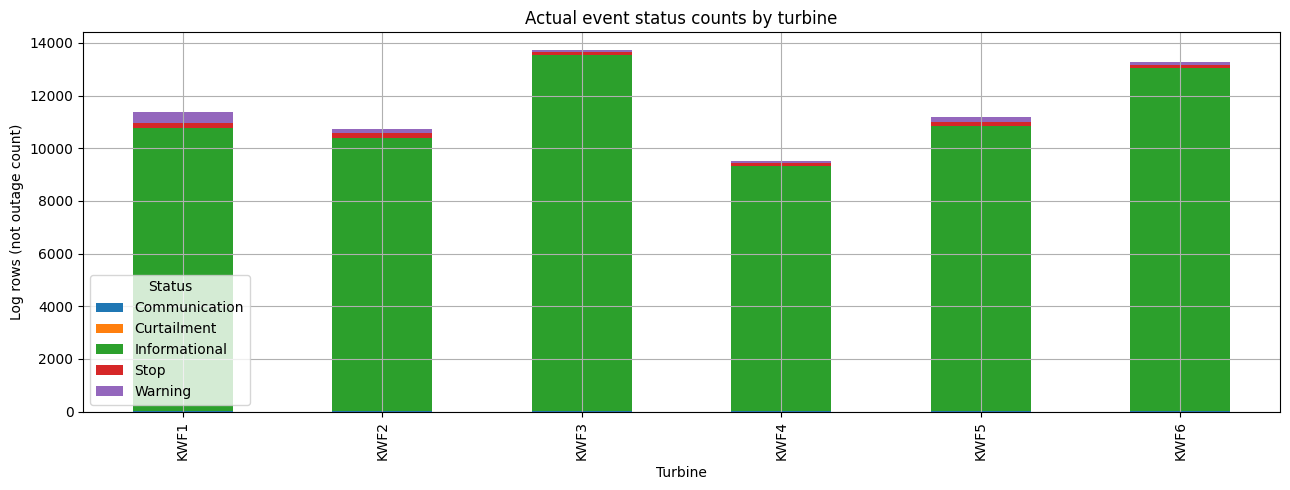

Event rows: 69,850; missing ends: 59,440; negative elapsed durations: 0; reported/elapsed differences above 1 second: 0. Missing ends remain unknown/point-event context; no fault-duration imputation is performed.

In [9]:
event_schema=[]
for turbine in sorted(header_map):
    pre,headers,skip=audit_header(source_path(ROOT,turbine,'events'))
    event_schema.append({'turbine':turbine,'fields':len(headers),'headers':json.dumps(headers),
                         'utc_declared':any(line=='# Time zone: UTC' for line in pre)})
event_schema=pd.DataFrame(event_schema); display(event_schema)
event_schema.to_csv(OUT/'event_schema_audit.csv',index=False)
event_audit=events.copy()
# Exported Duration supports hours exceeding 24 (for example multi-day outages).
def event_duration_seconds(value):
    if pd.isna(value): return np.nan
    match=re.fullmatch(r'(\d+):(\d{2}):(\d{2}(?:\.\d+)?)',str(value).strip())
    if not match: return np.nan
    hours,minutes,seconds=map(float,match.groups())
    if minutes>=60 or seconds>=60: return np.nan
    return hours*3600+minutes*60+seconds

event_audit['reported_seconds']=event_audit['Duration'].map(event_duration_seconds)
event_audit['elapsed_seconds']=(event_audit['Timestamp end']-event_audit['Timestamp start']).dt.total_seconds()
event_audit['duration_difference_seconds']=event_audit.reported_seconds-event_audit.elapsed_seconds
event_audit['missing_start']=event_audit['Timestamp start'].isna()
event_audit['missing_end']=event_audit['Timestamp end'].isna()
event_audit['unparsed_duration']=event_audit.Duration.notna() & event_audit.reported_seconds.isna()
event_audit['negative_elapsed']=event_audit.elapsed_seconds.lt(0)
event_audit['duration_mismatch_gt_1s']=event_audit.duration_difference_seconds.abs().gt(1)
event_audit['boundary_crossing']=(event_audit['Timestamp start'].lt(GRID[0]) |
    event_audit['Timestamp end'].ge(pd.Timestamp('2023-01-01',tz='UTC')))
event_audit.to_csv(OUT/'event_duration_row_audit.csv',index=False)
event_quality=event_audit.groupby('turbine').agg(rows=('turbine','size'),missing_start=('missing_start','sum'),
    missing_end=('missing_end','sum'),unparsed_duration=('unparsed_duration','sum'),
    negative_elapsed=('negative_elapsed','sum'),duration_mismatch_gt_1s=('duration_mismatch_gt_1s','sum'),
    boundary_crossing=('boundary_crossing','sum'))
event_quality.to_csv(OUT/'event_duration_quality_summary.csv'); display(event_quality)
category_columns=[c for c in events if 'category' in c.lower() or c=='Status']
category_counts=[]
for column in category_columns:
    counts=events.groupby(['turbine',column],dropna=False).size().reset_index(name='count')
    counts=counts.rename(columns={column:'value'}); counts.insert(1,'field',column)
    category_counts.append(counts)
category_counts=pd.concat(category_counts,ignore_index=True)
category_counts.to_csv(OUT/'event_category_counts.csv',index=False); display(category_counts)
code_counts=events.groupby(['turbine','Code','Status','Message'],dropna=False).size().reset_index(name='count')
code_counts.to_csv(OUT/'event_code_message_counts.csv',index=False)
display(code_counts.sort_values('count',ascending=False).head(40))
fig,ax=plt.subplots(figsize=(13,5))
status_counts=events.groupby(['turbine','Status'],dropna=False).size().unstack(fill_value=0)
status_counts.plot.bar(stacked=True,ax=ax)
ax.set(title='Actual event status counts by turbine',xlabel='Turbine',ylabel='Log rows (not outage count)')
fig.tight_layout(); plt.show()
display(Markdown(f"Event rows: {len(events):,}; missing ends: {event_audit.missing_end.sum():,}; "
    f"negative elapsed durations: {event_audit.negative_elapsed.sum():,}; "
    f"reported/elapsed differences above 1 second: {event_audit.duration_mismatch_gt_1s.sum():,}. "
    "Missing ends remain unknown/point-event context; no fault-duration imputation is performed."))

### Auxiliary grid meter and PMU exports: header-only scope

Inventory every available site CSV header and its declared time interval. **The PMU folder name
alone does not establish a high-frequency phasor measurement stream.** Header
field names provide the available signal evidence. Declared range overlap is not observed row-level
coverage: a preamble does not certify complete records, sampling frequency or alignment. No full
site-data load and **no join** are performed. Site totals/control measurements have different spatial
scope from per-turbine sensors; merging them blindly would duplicate site values across six assets,
change weighting and potentially leak production/control information.

In [10]:
auxiliary_rows=[]; auxiliary_fields=[]
for path in sorted((ROOT/'kelmarsh_data/site').rglob('*.csv')):
    pre,headers,skip=audit_header(path)
    intervals=[line for line in pre if line.startswith('# Time interval:')]
    declared=intervals[0] if intervals else ''
    dates=re.findall(r'\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}',declared)
    start=pd.to_datetime(dates[0],utc=True) if len(dates)>=2 else pd.NaT
    end=pd.to_datetime(dates[1],utc=True) if len(dates)>=2 else pd.NaT
    overlap=(max(start,GRID[0]) < min(end,pd.Timestamp('2023-01-01',tz='UTC'))) if pd.notna(start) and pd.notna(end) else None
    relative=str(path.relative_to(ROOT))
    auxiliary_rows.append({'path':relative,'kind':path.parent.parent.name,'file':path.name,
        'fields':len(headers),'preamble_lines':skip,'declared_interval':declared,
        'declared_start':start,'declared_end':end,'declared_overlap_2022':overlap,
        'timezone_lines':json.dumps([line for line in pre if 'Time zone:' in line]),
        'observed_row_coverage':'not scanned; header-only audit','joined':False})
    auxiliary_fields.extend({'path':relative,'position':i,'field':field} for i,field in enumerate(headers))
auxiliary_inventory=pd.DataFrame(auxiliary_rows); auxiliary_schema=pd.DataFrame(auxiliary_fields)
display(auxiliary_inventory); display(auxiliary_schema)
auxiliary_inventory.to_csv(OUT/'auxiliary_header_inventory.csv',index=False)
auxiliary_schema.to_csv(OUT/'auxiliary_full_schema.csv',index=False)

""


""


### Feature inclusion/exclusion rationale: avoid redundant production summaries

The selected twelve channels represent wind/environment, measured output, mechanical/thermal state,
pitch, grid frequency and setpoint. Setpoint is an observed control variable, not a fault label; any
model using it must state the operational interpretation. This audit does not transform these values.
For later clustering, derived production/loss counters, interval/cumulative energy, duplicate aggregate
statistics, identifiers and availability indicators are excluded from the candidate sensor space:

* Production/loss estimates already encode an expected-performance model or accounting decision;
  including them can turn discovering operating states into reproducing an existing estimate.
* Energy/cumulative counters are redundant with production and depend on interval length, history,
  resets and turbine age; absolute counters add spurious chronology.
* Minimum/maximum/standard-deviation channels describe the same aggregation window; adding all
  of them would multiply the weight of signals with more exported statistics. They remain audited.
* Timestamp and turbine identity provide alignment/group boundaries, not distances between sensors.
  Availability is a selection flag, not an observed physical operating state after filtering.
* Other legitimate sensors are outside this explicitly selected, interpretable comparison, not asserted
  useless. All-missing and constant fields have no observed within-turbine variability in this year.

The complete exclusion inventory below gives actual header-level reasons. These are proposed
feature-scope decisions only: **no source rows or columns are mutated here**. Event context and site
auxiliaries remain separate. A downstream benchmark must use January–June to fit transforms and
July–December for validation, respecting turbine/time boundaries.

In [11]:
def field_scope_reason(field):
    lower=field.lower()
    if field in SIGNALS.values(): return 'selected physical/control measurement; audit only'
    if field=='# Date and time': return 'alignment and chronological split only; not a distance feature'
    if 'availability' in lower: return 'selection/quality indicator; constant after availability filtering'
    if any(token in lower for token in ['loss','potential','production','yield','capacity factor']):
        return 'derived production/performance accounting; redundant or embeds prior performance model'
    if any(token in lower for token in ['energy','counter','count','total','accumulated']):
        return 'energy/counter/history-dependent quantity; interval redundancy or reset/age dependence'
    if any(token in lower for token in ['standard deviation','minimum','maximum','average','mean']):
        return 'additional aggregate of existing interval; avoids unequal representation/weighting'
    if any(token in lower for token in ['identity','identifier','serial','id number']):
        return 'asset identifier; alignment/group metadata only'
    return 'outside selected twelve-signal interpretable scope; not evidence of irrelevance'

field_scope=pd.DataFrame({'field':all_fields})
field_scope['selected']=field_scope.field.isin(SIGNALS.values())
field_scope['reason']=field_scope.field.map(field_scope_reason)
field_scope.to_csv(OUT/'full_feature_scope_rationale.csv',index=False)
display(field_scope)
display(Markdown(f"Audit artifacts saved under `{OUT.relative_to(ROOT)}`. "
    f"{len(header_map)} turbines, {len(all_fields)} distinct header fields, "
    f"{len(quality_profile):,} turbine-field quality rows, {len(gaps):,} missing-run records. "
    "This section has made no clustering claim and has not repaired, imputed, clipped or scaled the working dataset."))

,field,selected,reason
0,# Date and time,False,alignment and chronological split only; not a distance feature
1,Wind speed (m/s),True,selected physical/control measurement; audit only
2,"Wind speed, Standard deviation (m/s)",False,additional aggregate of existing interval; avoids unequal representation/weighting
3,"Wind speed, Minimum (m/s)",False,additional aggregate of existing interval; avoids unequal representation/weighting
4,"Wind speed, Maximum (m/s)",False,additional aggregate of existing interval; avoids unequal representation/weighting
...,...,...,...
298,"Drive train acceleration, Max (mm/ss)",False,outside selected twelve-signal interpretable scope; not evidence of irrelevance
299,"Drive train acceleration, Min (mm/ss)",False,outside selected twelve-signal interpretable scope; not evidence of irrelevance
300,"Drive train acceleration, StdDev (mm/ss)",False,outside selected twelve-signal interpretable scope; not evidence of irrelevance
301,"Tower Acceleration X, StdDev (mm/ss)",False,outside selected twelve-signal interpretable scope; not evidence of irrelevance


Audit artifacts saved under `artifacts\kelmarsh_2022`. 6 turbines, 303 distinct header fields, 1,812 turbine-field quality rows, 53 missing-run records. This section has made no clustering claim and has not repaired, imputed, clipped or scaled the working dataset.

### Sensor covariance, skewness, and scale disparity

Pearson captures linear association; Spearman captures monotonic association and is less sensitive to extreme magnitudes. Strong rotor/generator and wind/power dependencies can overweight one physical subsystem if every channel receives equal weight. Wind direction is circular: scalar-degree correlations are intentionally excluded; sine/cosine appear instead. Whole-year matrices below are descriptive EDA, not fitting statistics.

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,missing_pct
wind,314018.0,5.946156,2.685089,0.000000,1.043898,3.981960,5.747168,7.575586,13.366703,24.154331,0.650837,0.000000
power,314018.0,559.547617,593.344450,-17.782350,-5.666848,78.602486,347.361827,861.747378,2049.163049,2082.691937,1.101920,0.000000
reactive,314018.0,-190.516725,171.526457,-747.245212,-620.389895,-287.218486,-146.744164,-57.118761,0.382962,5.049339,-0.865579,0.000000
ambient,313760.0,12.188045,6.166932,-4.800000,-0.442500,7.782500,11.895000,16.122501,28.900000,39.327499,0.402778,0.082161
bearing,314018.0,37.833183,7.470404,5.000000,9.200000,35.304999,39.454999,42.519999,48.290001,66.162500,-1.827602,0.000000
oil,314018.0,51.251425,9.681932,8.600000,11.210000,49.860000,53.800000,57.007500,59.655000,65.002501,-2.632359,0.000000
rotor,314018.0,9.884956,4.546277,0.000000,0.000000,8.252550,10.390108,13.576158,15.192652,15.364253,-0.949751,0.000000
generator,314018.0,1172.177129,538.148540,-571.625175,-0.104471,979.745110,1232.737018,1608.772623,1800.237130,1824.756924,-0.953442,0.000000
pitch,313760.0,9.558540,22.509445,-172.879499,0.000000,0.000000,0.097000,1.490000,91.943690,92.889999,2.615181,0.082161
frequency,314018.0,49.988437,0.364089,0.000000,49.883199,49.950595,49.991505,50.032244,50.106630,50.196360,-118.800510,0.000000


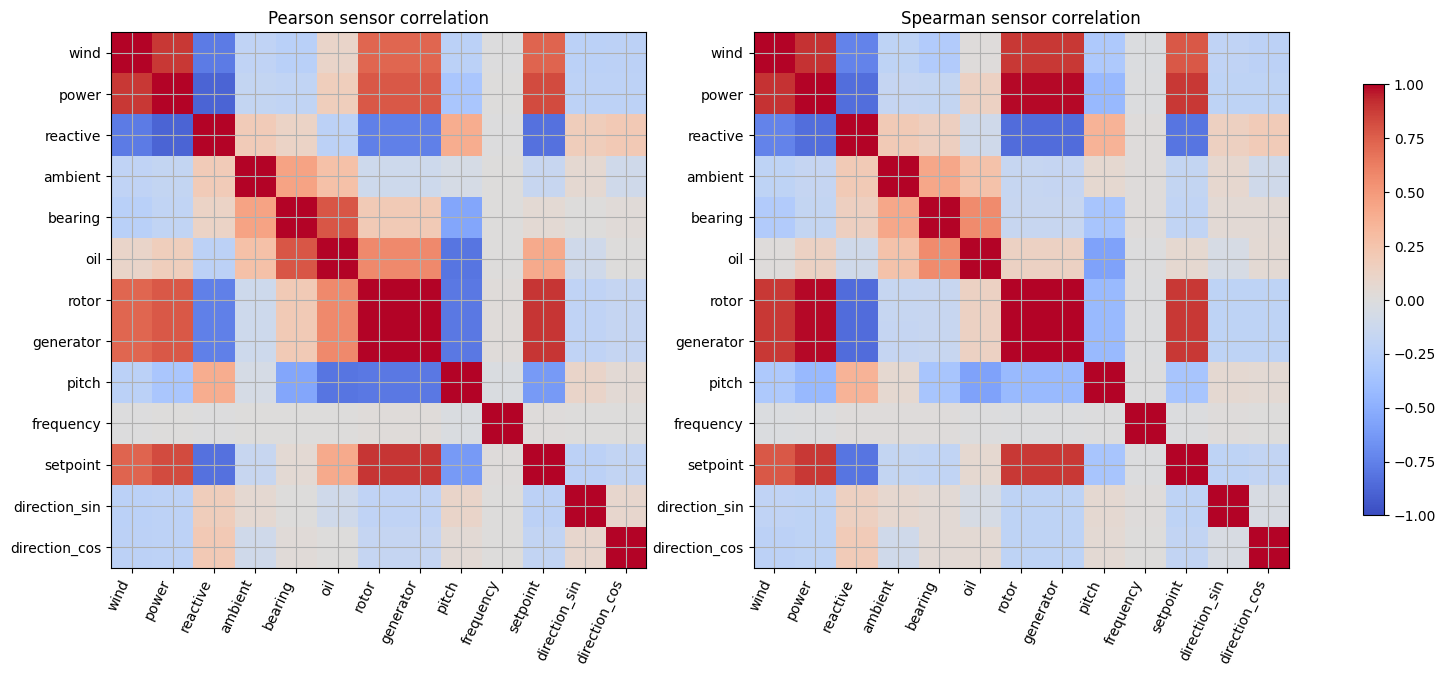

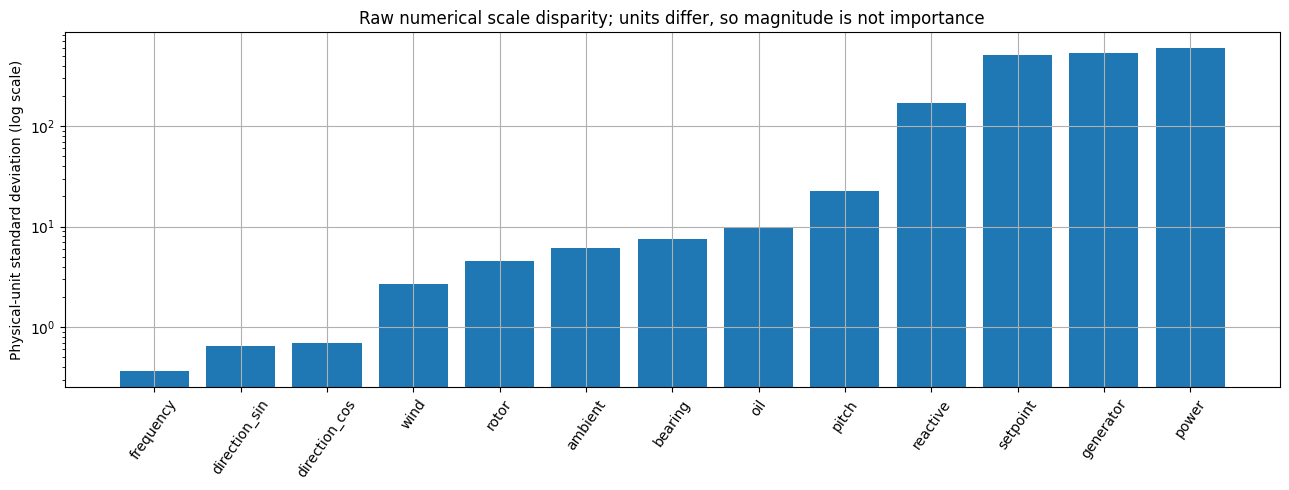

In [12]:
eda = df[list(SIGNALS)].drop(columns='direction').copy()
eda['direction_sin'] = np.sin(np.deg2rad(df.direction))
eda['direction_cos'] = np.cos(np.deg2rad(df.direction))
description = eda.describe(percentiles=[.01,.25,.5,.75,.99]).T
description['skew'] = eda.skew()
description['missing_pct'] = eda.isna().mean()*100
display(description)
description.to_csv(OUT/'selected_scale_skewness.csv')
fig, axes = plt.subplots(1,2,figsize=(19,8))
for ax,method in zip(axes,['pearson','spearman']):
    corr = eda.corr(method=method)
    corr.to_csv(OUT/f'sensor_{method}_correlation.csv')
    im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=65,ha='right')
    ax.set_yticks(range(len(corr)),corr.index)
    ax.set_title(method.title()+' sensor correlation')
fig.colorbar(im,ax=axes.ravel().tolist(),shrink=.7); plt.show()
fig,ax=plt.subplots(figsize=(13,5))
std=eda.std().sort_values()
ax.bar(std.index,std.values); ax.set_yscale('log')
ax.tick_params(axis='x',rotation=55)
ax.set(ylabel='Physical-unit standard deviation (log scale)',title='Raw numerical scale disparity; units differ, so magnitude is not importance')
fig.tight_layout(); plt.show()


## Literature: all eleven selected papers

Page numbers below refer to 1-based PDF pages, not printed journal pagination. “Not reported” means unavailable in reviewed text, not proof method was absent. Paper results from other domains are not comparable scores for Kelmarsh. Each adaptation needs this dataset’s own checks.

In [13]:
display(Markdown('Original papers.json unavailable: literature comparison cannot be reconstructed from titles. Numerical benchmarks remain unchanged.'))

Original papers.json unavailable: literature comparison cannot be reconstructed from titles. Numerical benchmarks remain unchanged.

### Time2Feat: Learning Interpretable Representations for Multivariate Time Series Clustering

Source: `selected/10_p193-tiano.pdf`. **Domain:** General multivariate time-series clustering; evaluated on 18 UEA datasets covering motion, physiological and other signals.. **Objective:** Represent each multivariate sequence through concise interpretable intra-signal and inter-signal features, then cluster sequences in unsupervised or optionally semi-supervised mode..

- **Sequence-level input representation:** Input is a dataset of V multivariate sequences, each with N timestamps and S signals: V×N×S tensor. Each sequence becomes one clustering object; this is not pointwise clustering of every timestamp. Table 1 lists existing benchmark sequence lengths rather than a sliding-window construction procedure. Parameters: V, N and S depend on dataset. BasicMotions example has 80 sequences, 6 signals and 100 observations per signal.. Evidence: PDF p. [2, 3, 5], Section 2; Section 3, Definitions 3.1–3.2; Table 1.
- **Intra-signal statistical feature extraction:** Apply tsfresh separately to every signal of every MTS. Section 4.1 states '700+ features', spanning Distribution Analysis, Statistical Analysis and other statistical perspectives. Mean and autocorrelation are named examples in Section 2. Algorithm 1 loops over sequences and signals; implementation batches univariate series using tsfresh parallelization. Table 3 reports 1574 intra-signal features for two-signal datasets and 4722 for six-signal datasets, consistent with 787 feature outputs per signal in those experiments; this count is inferred from table totals, not a fully specified calculator configuration. Parameters: Library tsfresh; exact version, calculator list and calculator parameter settings unspecified. Table 3 provides dataset-level counts, not complete definitions.. Evidence: PDF p. [2, 4, 6], Section 2; Section 4.1, Intra-signal Features Extraction; Algorithm 1; Table 3.
- **Inter-signal pairwise feature extraction:** For each MTS, compute eight relatedness metrics for each unordered pair of signals. Section 4.1 explicitly names correlation and Euclidean distance as examples, not a complete list. Figure 1 additionally shows L1 distance and Chebyshev distance feature labels. Table 3 reports 8 inter-signal outputs for two signals and 120 for six signals, matching eight metrics per unordered pair. This preserves cross-signal relations as interpretable features rather than learned neural embeddings. Parameters: Eight metrics per signal pair; complete metric inventory, correlation type and metric-specific settings not enumerated in main methods text.. Evidence: PDF p. [2, 3, 4, 6], Figure 1; Definition 3.4; Section 4.1, Inter-signal Features Extraction; Algorithm 1; Table 3.
- **Extracted-feature column cleaning:** Remove all zero-variance feature columns and feature columns containing missing or infinite values. Algorithm 2 describes removal of features with constant, null and/or infinite values. This is deletion of unusable derived features, not raw-SCADA row deletion, raw-signal imputation or outlier detection. Section 3 uses broader 'low variance' language, but implementation description in Section 4.2 explicitly says zero variance; no positive low-variance threshold should be invented. Parameters: Variance exactly zero; missing or infinite feature values trigger column removal. Handling of near-zero variance unspecified.. Evidence: PDF p. [3, 4], Section 3; Section 4.2; Algorithm 2.
- **Unsupervised Principal Features Analysis selection:** After cleaning, apply PFA to select meaningful original features retaining information through maximum variability in a lower-dimensional space. PFA is used in both modes and intended to provide concise, diverse, semantically interpretable original features; it is not equivalent to clustering on anonymous PCA component scores. BasicMotions example reduces 4842 initial outputs to 46 in unsupervised mode. Table 3 gives retained counts by dataset/mode. Parameters: PFA technique cited to Lu et al.; retention threshold, PCA dimensionality, representative-feature selection settings and random-state configuration unspecified in paper.. Evidence: PDF p. [3, 4, 6], Section 2 discussion; Section 4.2; Algorithm 2; Table 3.
- **Optional label-driven ANOVA and grid-search feature selection:** Semi-supervised branch uses supplied sequence labels to compute ANOVA p-values and rank feature relevance. Grid search chooses feature subset maximizing clustering quality evaluated with Homogeneity Score, AMI and ARI; PFA still follows. Experiments use stratified random labeled fractions of 20%, 40% and 50% per ground-truth cluster. Not part of strictly unsupervised Kelmarsh workflow. Parameters: Experimental label fractions 20%, 40%, 50%; ANOVA cutoff, subset-search grid and rule combining quality metrics unspecified.. Evidence: PDF p. [4, 5], Section 4.2; Algorithm 2; Section 5.1.
- **Normalize selected features before clustering:** Section 4.3 states clustering operation includes a normalization step to avoid dominance of features with large-scale domain ranges. Figure 2 positions normalization between feature selection and cluster generation. Paper does not identify normalization formula; neither Z-score nor Min-Max can be attributed as exact paper method. Parameters: Scaler type, fitted population, per-feature scope and constant-feature behavior unspecified.. Evidence: PDF p. [3, 4], Figure 2; Section 4.3.

**Not reported / reproduction limits:** Raw-signal missing-value imputation, raw outlier filtering, duplicate handling, timestamp regularization, resampling and physical-unit harmonization are not specified.; No procedure for segmenting a continuous SCADA stream, window stride, overlap or gap-boundary handling is specified; UEA observations are already separate sequences.; Exact tsfresh configuration and complete eight-metric inter-signal inventory are not enumerated.; PFA numerical selection settings and optional ANOVA search settings are not specified.; Normalization method and fitting scope are not specified; no causal or held-out scaler-fit protocol is described..

**Transfer decision:** Use each turbine-window as an MTS object, with windows constructed by benchmark design rather than claimed as paper reproduction. Transfer window statistics, meaningful inter-signal correlations/distances, zero-variance and nonfinite feature-column cleaning. Preserve turbine identity as metadata rather than numeric clustering input. Distances between variables with unlike units require a separately documented scaling decision; selected-feature normalization alone does not make raw wind-speed/power distance physically meaningful. PFA is transferable in principle, but ordinary PCA scores are not exact substitute. Semi-supervised ANOVA branch needs regime labels unavailable in unsupervised analysis. Six whole-turbine year-long objects would not support temporal regime discovery.

**Benchmark candidates:** Common finite-window statistical summaries, explicitly described as tsfresh-inspired subset rather than reproduction of 700+ outputs.; Selected physically meaningful pairwise correlations within turbine windows; full eight-metric extraction only if metric inventory is independently obtained.; Drop exactly constant and nonfinite derived-feature columns using benchmark fit partition.; Compare selected-feature scaling primitives, but label chosen scaler as benchmark decision because paper formula is unspecified.; PFA only with explicit independently documented settings; do not label ordinary PCA score reduction as Time2Feat replication.

**Limitations:** Hierarchical/KMeans/Spectral clustering, Elbow cluster-count choice and visualization t-SNE are modeling/visualization, not raw preprocessing. AMI comparisons exploit UEA ground-truth classes and cannot be carried over as unsupervised Kelmarsh validation. PFA and feature extraction can be expensive; Section 5.3.2, PDF p. 7, attributes 88%–99% of runtime to extraction. Sequence summaries lose event timing; Section 5.1, p. 5, reports difficulty distinguishing composed trajectories in UWaveGestureLibrary. Normalization and PFA omissions prevent exact paper-only reproduction.

### Analysis of Multivariate Indoor Building Data: A Comparative Study of Time-Series Clustering Methods

Source: `selected/12_Analysis-of-Multivariate-Indoor-Building-Data-A-Comparative-Study-of-Time-Series-Clustering.pdf`. **Domain:** Bedroom indoor environmental and human-behavior sensor time series.. **Objective:** Compare clustering algorithms on parallel Min-Max-scaled and first-order-gradient representations of aligned multivariate sequences..

- **Select monitoring zone and sensor groups:** From 21 zones, select Bedroom because it has most consistent and abundant coverage. Environmental variables: power, acoustic level, CO2, luminosity, temperature and humidity. Human variables: binary motion and binary contact/window state. Collection April 2022–July 2023 includes maintenance gap from late March to mid-April 2023. Parameters: Environmental units W, dBm, ppm, Lux, degrees C and percent; motion 1 denotes detected movement; contact 1 denotes open window.. Evidence: PDF p. [4], Section III-A; Tables 1–2 captions and surrounding dataset description.
- **Missing/duplicate handling and unit standardization:** General preprocessing paragraph explicitly mentions 'handling missing and duplicated values' and 'standardizing units', followed by outlier removal, segmentation/alignment and interpolation. Missingness handling is later differentiated by sensor type. No duplicate-resolution rule or unit-conversion mapping is given in extracted method prose. Parameters: Duplicate key, keep/aggregate policy and conversion rules unspecified.. Evidence: PDF p. [4, 9], Section III-B opening paragraph; Section IV-A.
- **Expert-defined sensor-range outlier removal:** Identify points outside permissible minimum/maximum operational bounds for each sensor, set using expert knowledge. Remove values exceeding predefined sensor-specific bounds; method is not IQR, Z-score or DBSCAN. Parameters: Sensor-specific minimum and maximum operational thresholds; exact numerical filtering bounds not stated in Section III-B.1 prose. Descriptive data range must not automatically be treated as filtering threshold.. Evidence: PDF p. [5], Section III-B.1, Outlier Removal.
- **Hourly alignment and sensor-specific aggregation:** Align heterogeneous sampling to uniform 60-minute windows. Mean aggregate continuous CO2, luminosity, temperature, humidity, acoustic and power. Sum aggregate binary/event motion and contact. Stated acquisition intervals include 30 minutes for temperature/humidity/acoustic/power, 60 minutes for luminosity/CO2, and up to 196 minutes for contact. Contact is event-driven and records state changes. Parameters: Aggregation interval 60 minutes; mean for six continuous variables; sum for motion/contact. Bin origin, closed endpoint and timestamp label unspecified.. Evidence: PDF p. [5], Section III-B.2, Data Segmentation, Alignment and Interpolation.
- **Active-session segmentation and exclusion:** Concatenate hourly samples into multivariate seven-hour segments for morning 05:00–12:00 and afternoon/evening 13:00–20:00. Remaining 20:00–05:00 hours are explicitly excluded as low-variability. Listed sessions also leave 12:00–13:00 outside both sessions; prose does not explain this gap. Segment endpoints should not be guessed as inclusive eight-point sampling. Parameters: Two seven-hour sessions per day, each built from 60-minute bins. Exact endpoint convention and incomplete-session acceptance rule unspecified.. Evidence: PDF p. [5], Section III-B.2.
- **Sensor-semantic gap filling:** Motion absence interpreted as no activity and filled with 0. Contact absence interpreted as unchanged state and forward-filled from last observed value. Other continuous sensors use cubic spline interpolation, described as piecewise third-degree polynomials smooth in first and second derivatives. These are distinct methods, not one universal interpolation policy. Parameters: Motion fill value 0; contact forward fill; continuous cubic spline degree 3. Spline boundary condition, extrapolation policy, maximum gap and treatment of initial missing contact state unspecified.. Evidence: PDF p. [5], Section III-B.2.
- **Min-Max representation branch:** Apply featurewise x'=(x−xmin)/(xmax−xmin), targeting [0,1], to processed data. Goal is prevent large-range variables dominating distance calculations. This is one of two parallel representations, not an obligatory stage before differentiation. Parameters: Range [0,1]; feature minimum/maximum. Fit population, sequence-local versus global extrema and zero-range handling unspecified.. Evidence: PDF p. [5], Section III-B.3; Equation 1.
- **Finite-difference first-order gradient branch:** Apply gradient after common cleaning/alignment/interpolation but explicitly excluding Min-Max normalization. At first point use (f1−f0)/(t1−t0), interior points (f[i+1]−f[i−1])/(t[i+1]−t[i−1]), last point (fn−f[n−1])/(tn−t[n−1]). For equal spacing Δt, denominators are Δt at boundaries and 2Δt internally. This is length-preserving central-difference gradient with one-sided boundaries, not simple n−1 successive differences. Parameters: First-order derivative; forward/backward first-order boundary approximation; central interior approximation. Aggregated spacing 60 minutes; numerical time-unit convention and differentiation across session boundaries unspecified.. Evidence: PDF p. [5, 6], Section III-B.4, First-order Derivative Approximation.

**Not reported / reproduction limits:** Exact duplicate handling and unit conversion operations are not described.; Exact outlier bounds are not stated in methods prose; Tables 1–2 bodies were not exposed by available PDF reader, so their descriptive numeric entries were not recoverable here.; Maximum interpolated gap, spline boundary condition, extrapolation, leading contact gaps and treatment of maintenance gap are unspecified.; Order of state filling versus binary/event summation and rules for preserving state occupancy versus event counts are not resolved explicitly.; Hourly-bin endpoints, incomplete-session rejection, session-boundary differentiation and scaler-fit population are unspecified.; No concrete separate dimensionality-reduction or statistical-feature extraction stage is specified for this study. Section III-C.4 mentions Z-score as typical SBD normalization, not as explicit global third preprocessing branch..

**Transfer decision:** Transfer hourly continuous aggregation, common aligned multivariate windows, feature Min-Max scaling and explicitly central-difference gradient as distinct primitives. Keep level-based branch because power, rotor speed and wind-speed magnitude distinguish operating regimes; gradient-only branch discards state level. Building-specific active-hours exclusion is not transferable: turbines operate continuously and night/low-variation conditions can be legitimate regimes. Motion zero filling and contact forward filling require event-sensor semantics; missing turbine power or wind speed cannot be assumed zero. Cubic splines need gap limits and bounds checks as benchmark safeguards, not paper-stated parameters, and must not bridge outages or turbine boundaries. Wind direction needs circular treatment; naive means of degrees are inappropriate.

**Benchmark candidates:** 60-minute mean aggregation of continuous SCADA channels, retaining turbine ID and time-bin provenance.; Min-Max levels versus unscaled first-order central gradients after identical common cleaning; use explicit time units.; Seven-hour nonoverlapping sequence representation as transferable duration experiment, but no indoor morning/evening exclusion.; Cubic-spline versus benchmark baseline interpolation on bounded short continuous gaps, with gap limit openly benchmark-defined.; Physical-range filtering only where turbine documentation supplies legitimate bounds; do not copy indoor thresholds.

**Limitations:** Tables 1–2 and result-table bodies were not returned by reader; methods prose and textual result discussion were read, but table-body visual inspection was unavailable. Section IV reports large gradient gains for continuous environmental data (e.g., approximately 0.97 Silhouette for KMeans/Bi-Clustering on PDF pp. 10–11), but no clear gains for event-driven human data (pp. 12–13); do not universalize gradient superiority. Some result prose contradicts metric direction, including describing increased DBI as improved, so numerical findings should not be used uncritically. Interpolated smooth sequences can artificially improve geometric separation. Euclidean/DTW/SBD/mutual reachability and KMeans/HDBSCAN/KShapes/SOM/Bi-Clustering are distances/models, not preprocessing methods.

### Temporal and Multivariate Similarity Clustering of 5G Performance Data

Source: `selected/25_Temporal-and-Multivariate-Similarity-Clustering-of-5G-Performance-Data.pdf`. **Domain:** 5G radio-cell performance/environmental KPIs; additional accelerometer gesture experiment.. **Objective:** Cluster cells by temporal multivariate KPI behavior to detect differences in configuration, while tolerating noise and limited time distortion but preserving differences in signal magnitude..

- **Hourly KPI collection over one-week observation horizon:** Select eight KPIs and collect hourly aggregated measurements for one week, giving 168 samples per KPI per cell. Hourly resolution balances availability with information content; weekly horizon captures major typical daily/weekday/weekend conditions. This describes observation design, not a rolling weekly segmentation algorithm. Parameters: Eight variables; hourly granularity; seven days/168 time samples. Aggregation operator and explicit week-boundary convention unspecified.. Evidence: PDF p. [2, 5], Section II-A; Section IV-A; Table 2 caption.
- **Missingness-based cell selection:** Analyze missing values and retain only cells with less than 5% missing values. Resulting dataset contains 9209 cells across three configurations: 3851, 1658 and 3700. Strict wording is less than 5%, not less than or equal to 5%. Whether missingness is computed per KPI or across all cell entries is not resolved. Parameters: Retain missing fraction <0.05; missingness denominator/scope unspecified.. Evidence: PDF p. [5], Section IV-A, Data Set.
- **Cell-average missing-value replacement:** Paper states 'The averages for each cell replaced the missing values.' Practical transfer should use each cell's corresponding KPI mean because variables have different units, but exact per-KPI implementation is not explicitly stated in prose and should be marked as benchmark interpretation. Mean replacement is separate from subsequent pooled standardization. Parameters: Cell-average fill; exact averaging scope and all-missing-feature handling unspecified.. Evidence: PDF p. [5], Section IV-A.
- **Pooled per-variable Z-score standardization:** For each variable j, gather values over all observations i and timestamps k, then x'j=(xj−mean(xj))/std(xj). Mean 0 and standard deviation 1 per variable across observations, rather than independently normalizing every cell/sequence. Authors explicitly intend to abstract units while retaining value-range differences between observations of same variable. Parameters: Mean 0; standard deviation 1; pooling axes observation and time for each variable. Standard-deviation degrees of freedom and zero-variance handling unspecified; whether fitted per sampled evaluation batch or full dataset unspecified.. Evidence: PDF p. [4], Section III-A, Data Preprocessing; Equation 1.
- **Trailing simple moving average after standardization:** Apply x''[i,j,k]=(1/w) sum from t=k−w+1 through k of x'[i,j,t]. Order is standardize first, then smooth. Goal is reduce noise and short-term fluctuations and highlight longer trends. Equation specifies trailing, equal-weight moving average, not centered smoothing or exponential smoothing. Parameters: Window length symbolic w; actual numeric w not given in readable methods or evaluation prose. Startup/edge handling, minimum periods and resulting sequence length unspecified.. Evidence: PDF p. [4], Section III-A; Equation 2.
- **Time alignment and nonfragmented sequences recommendation:** Algorithm introduction recommends time-aligned sequences not fragmented by missing values for best results, although not necessary for calculation. This is a recommended input property rather than a specified interpolation or alignment routine. Parameters: Alignment method, timestamps/time-zone handling and gap-repair details unspecified beyond mean fill in dataset experiment.. Evidence: PDF p. [3, 4], Section III introductory paragraphs.

**Not reported / reproduction limits:** Numeric moving-average window w and smoothing boundary policy are not specified in readable paper prose.; Explicit outlier removal, clipping, winsorization, duplicate handling and raw acquisition aggregation operator are not reported.; Missingness denominator and whether cell-average imputation is per KPI are not explicit.; Standardization fit population within repeated batches versus complete dataset, std degrees of freedom and zero-variance handling are unspecified.; Exact LDTW maximum path-length bound and clustering parameter choices are not given in methods prose; authors state they experimented and selected best settings.; Table 2 lists eight KPI names/units, but table body was not exposed by PDF reader; exact inventory cannot be transcribed from available extraction..

**Transfer decision:** Transfer pooled featurewise standardization rather than per-window normalization when absolute regime levels matter. Transfer trailing moving-average smoothing with explicitly benchmark-defined window, plus missingness screening and per-turbine/per-feature mean fill as a clearly documented adaptation. A whole-turbine weekly observation clusters turbines/weeks, not instantaneous regimes; create turbine-window objects for temporal analysis. Hourly averages and mean filling may suppress starts, stops, curtailment and fault transitions. Rejecting windows with high missingness changes analyzed population and should be audited. Do not assume common pooled mean is causal or leakage-free; fit on designated benchmark partition. For an offline regime study, chronological holdout and future-data use remain separately documented design decisions.

**Benchmark candidates:** Pooled per-feature Z-score fitted across training turbines/windows/time, compared with per-window normalization to quantify loss of level information.; Trailing equal-weight moving averages at independently declared benchmark windows; no claim paper supplies numeric w.; Strict <5% missingness window acceptance as adaptation of cell-level eligibility, with denominator explicitly defined.; Per-turbine/per-variable mean imputation on allowed small gaps, compared with time-aware filling; do not silently treat interpretation as exact paper implementation.; Hourly aggregation and weekly-window sensitivity, separated from shared preprocessing benchmark if regime resolution would be too coarse.

**Limitations:** LDTW pairwise distances, L2 collapse of per-variable distance vector and max(D')−D' spectral affinity are modeling/representation stages, not ordinary feature scaling or PCA. Section III-C, PDF p. 5, contains apparent matrix-size typo NxM; pairwise cell distances are logically NxN. Section V-C, p. 7, gives complexity O(N^2 M T^3), making whole-year LDTW over many windows impractical. Paper evaluation samples 100 cells per class, 300 observations, repeated 100 times (Section IV-B, p. 6); configuration labels and NMI are not available Kelmarsh regime ground truth. Shape-only per-sequence normalization conflicts with stated need to preserve value-range differences. Table bodies were unavailable through reader, but complete algorithm and evaluation prose were read.

### Short-Term Offshore Wind Power Forecasting Based on Dynamic Trend Clustering of Meteorological Factors

Source: `selected/33_Short-Term-Offshore-Wind-Power-Forecasting-Based-on-Dynamic-Trend-Clustering-of-Meteorological.pdf`. **Domain:** Offshore wind-farm SCADA/NWP short-term power forecasting.. **Objective:** Construct forecasting-day-specific historical training subsets using meteorological state similarity followed by wind-speed trend similarity, then forecast power with TPA-MBLSTM. Clustering is training-data screening, not primary unsupervised operating-regime discovery..

- **DBSCAN outlier detection:** Apply DBSCAN to raw wind-power data to detect outliers in low-density regions. Case-study description reiterates same cleaning sequence. Paper does not identify variables supplied to DBSCAN, distance metric or whether observations are power alone or joint meteorological-power points. Parameters: DBSCAN; epsilon, min_samples, distance metric, feature scaling before detection and physical abnormality criteria unspecified.. Evidence: PDF p. [6, 7], Section IV-C.1, Data Cleaning; Section V-A.
- **Outlier replacement using linear regression extrapolation:** Replace DBSCAN outliers with plausible estimates from linear regression extrapolation based on existing trends. Not deletion, simple interpolation or winsorization. Context/predictors and directional use of time are not specified. Parameters: Linear regression extrapolation; fitting window, predictors, minimum observations and extrapolation limits unspecified.. Evidence: PDF p. [6, 7], Section IV-C.1; Section V-A.
- **KNN missing-value imputation:** After outlier reconstruction, estimate each missing entry as mean of its K most similar neighbors. Sequence order is explicitly DBSCAN detection, regression replacement, then KNN fill. Parameters: K nearest neighbors, mean aggregation; numeric K, similarity metric, feature scaling, weighting, temporal neighbor restriction and all-missing cases unspecified.. Evidence: PDF p. [7], Section IV-C.1; Section V-A.
- **Power-supervised Pearson correlation feature selection:** Use power as dependent variable and meteorological parameters as independent variables; evaluate Pearson coefficients and p-values, retain significantly correlated factors. Six meteorological factors assessed in case study; text ranks wind speed highest, then air density and wind direction. Selected model input variables are wind speed, sine/cosine of wind direction and air density. This uses observed power to select covariates and is not label-free unsupervised feature selection. Parameters: Pearson correlation and significance p-values; coefficient cutoff, p-value threshold, multiple-testing policy and selection fit partition unspecified.. Evidence: PDF p. [7, 8], Section IV-C.2; Section V-A; Table I; Figure 6.
- **Circular encoding and daily meteorological summary construction:** For first-stage state clustering use five daily features: mean wind speed, peak/maximum wind speed, minimum wind speed, mean of sine of wind direction and mean of cosine of wind direction. Averaging sine/cosine separately respects directional periodicity better than arithmetic mean of angles. Model input list additionally includes air density; do not conflate that with five-feature daily clustering matrix. Historical data provide daily features, forecasting-day NWP supplies matching daily summaries. Parameters: Daily granularity; five named state features. SCADA cadence 10 minutes, implying 144 points per complete day, but completeness threshold and daily-bin time zone unspecified. Angle conversion unit unspecified.. Evidence: PDF p. [4, 7, 8], Section II-C, State Clustering of Meteorological Features; Section V-A; Section V-B opening paragraphs.
- **Mixed normalization before state clustering:** Section V-B explicitly applies Min-Max normalization to meteorological variables, with wind speed and temperature named examples, and Z-score standardization to wind-direction sine/cosine values. Intended equal feature contribution and elimination of scale bias. Temperature mentioned as scaling example despite not being in final selected model-input list, so this is not evidence that temperature was retained in final five-feature state matrix. Parameters: Min-Max and Z-score named; target Min-Max interval, formulas, fit population, test/NWP transform fitting and zero-variance handling unspecified.. Evidence: PDF p. [8], Section V-B, Analysis of Forecasting Results, opening preprocessing paragraph.
- **Wind-speed first-difference trend vectors and normalization:** Within first-stage meteorologically matched days, represent wind-speed evolution as sequence, compute first-order differences to form characteristic trend vector, normalize feature vectors to remove numerical scale differences, then compute cosine similarity with target/predicted sample. Paper names first differences, not central gradient with one-sided edges. Exact vector normalization is unspecified; cosine formula divides dot product by Euclidean vector norms, but that alone does not prove separately specified normalization uses L2 rather than another scaler. Parameters: First-order differences; cosine=(A·B)/(||A||||B||). Normalization formula, vector time span, similarity cutoff, grouping algorithm and zero-norm vector handling unspecified.. Evidence: PDF p. [4, 5, 9], Sections III-A and III-B; Equations 11–12; Figure 2; Section V-B.3.
- **Forecast-conditioned two-stage historical sample screening:** Stage 1 IACO-optimized FCM groups historical days by daily meteorological summaries and selects subset matching forecasting day. Stage 2 cosine similarity on normalized wind-speed trend vectors refines subset. Section V-B.1 tests cluster counts 2–6 and selects five based on Xie–Beni index; Section V-B.2 describes partition into five clusters. This is clustering-as-training-preparation, not generic raw data cleaning. Forecasting-day information comes from NWP; historical data exclude test days. Parameters: First-stage cluster count K=5 selected from K=2,…,6; numeric FCM fuzzifier and second-stage cutoff unspecified in readable methods prose.. Evidence: PDF p. [4, 5, 7, 8, 9], Section II-C; Section III-B; Section IV-C.3; Section V-A; Section V-B.1–3; Table II.
- **Time-resolution and experimental-day construction:** Main dataset January 1, 2018–November 4, 2019: 673 days and 96,912 samples at 10-minute resolution. Representative winter/summer days are tests; customized training subset built from 2018–2019 historical data excluding test days. Attention section defines symbolic sliding-window length but provides no readable numeric history window. Additional cross-regional study uses full-year 2022, 52,560 samples at 10-minute resolution and two representative prediction days. Parameters: 10-minute cadence; daily state selection. Exact forecast horizon, input history length, stride and chronological cutoff unspecified in readable prose.. Evidence: PDF p. [6, 7, 8, 12, 14], Section IV-B; Section V-A; Table V caption and surrounding model configuration; Section V-B.9.

**Not reported / reproduction limits:** DBSCAN epsilon/min_samples, input dimensions and detection scaling are not specified in readable methods prose.; Regression reconstruction predictors, temporal fitting window and extrapolation bounds are unspecified.; KNN numeric K, distance, scaling, weighting and temporal restrictions are unspecified.; Pearson selection coefficient/significance thresholds and fit partition are unspecified.; Min-Max target range and fit scope, Z-score convention and trend-vector normalization formula are unspecified.; Cosine similarity threshold, second-stage cluster assignment procedure and zero-vector handling are unspecified.; Numeric sliding-window/history length, forecast horizon and precise causal train/test boundary could not be recovered from readable prose. Table V body was omitted by reader; cannot assert it lacks these settings.; Tables I, II and V bodies were not exposed by reader; exact correlation coefficients, full Xie–Beni matrix and model-configuration cells cannot be independently transcribed here. Surrounding prose explicitly supplies five-cluster decision.; Duplicate handling, timestamp alignment/resampling, max-gap limit, outage exclusion and status-based operating-regime filtering are not specified..

**Transfer decision:** Transfer sine/cosine wind-direction encoding, daily/window mean/max/min wind speed, first-difference trend features, explicit mixed-scaling alternatives and imputation/anomaly-detection primitives where independently configured. Do not equate DBSCAN low density with sensor error: stopped, curtailed, maintenance and rare valid regimes are intended discoveries and regression replacement could erase them. KNN imputation must preserve turbine boundaries and avoid future leakage for held-out temporal evaluation; these constraints are benchmark safeguards, not paper settings. Power-conditioned feature selection is an optional target-informed representation, not strictly unsupervised. Air-density feature requires available density or justified computation from temperature/pressure; do not fabricate absent weather/NWP channels. Forecast-day-conditioned IACO-FCM/cosine filtering requires NWP and forecast objective, unlike full-year Kelmarsh temporal operating-regime discovery; no whole-paper replication claim.

**Benchmark candidates:** Wind-direction sine/cosine encoding; daily or benchmark-window speed mean/min/max features.; First-order successive wind-speed differences compared with level features and central gradients; normalization choice explicitly benchmark-defined.; Min-Max meteorological features with Z-scored circular components as paper-inspired mixed-scaling branch, documenting fit scope and target interval.; KNN mean imputation versus simpler gap filling, with independently chosen K, metric and gap restrictions disclosed.; DBSCAN flagging plus regression reconstruction only as bounded sensitivity experiment; retain flags and unmodified baseline rather than silently destroy valid rare regimes.; Pearson-to-power selection only in separate target-informed sensitivity analysis, not unsupervised baseline.; Exclude forecast-conditioned two-stage screening from shared preprocessing primitive benchmark unless required NWP/task setup is supplied.

**Limitations:** Paper evaluates forecast MAE/RMSE/MAPE/R², not regime clustering quality. DBSCAN is anomaly-detection model here; IACO-FCM/cosine are sample-screening models; TPA/MBLSTM/dropout are forecasting-model operations rather than transferable preprocessing. Authors call test-day exclusion 'strict temporal isolation' (PDF p. 8), but exclusion alone does not establish chronological causality or training-only preprocessing fitting; neither should be inferred. Daily statistics and difference-only vectors lose absolute or within-day timing information. Exact outlier replacement and KNN implementations cannot be reproduced from named methods alone. Tables were extracted as captions without bodies, limiting numerical table evidence; all relevant surrounding methods/case-study prose was read. Offshore meteorology, NWP, weather events and farm-level forecast objectives differ from six onshore turbine temporal regimes.

### A self-supervised learning-based approach to clustering multivariate time-series data with missing values (SLAC-Time): An application to TBI phenotyping

Source: `selected/39_1-s2.0-S1532046423001223-main.pdf`. **Domain:** Clinical multivariate irregular time series; traumatic brain injury phenotyping in TRACK-TBI.. **Objective:** Cluster patients, not timestamps, using static and first-five-day clinical observations; learn representations through forecasting and iterative pseudo-label training. DOI: https://doi.org/10.1016/j.jbi.2023.104401.

- **Cohort and feature-scope selection:** Original dataset has 2996 patients. Exclude patients without available GOSE score; 2160 remain. Inputs comprise 59 non-temporal and 51 time-series variables collected during first five days of hospital/ICU stay. GOSE, ICU length of stay, and mortality are described as outcome validation variables, not features to import into turbine clustering. Parameters: {'static_variables': 59, 'temporal_variables': 51, 'observation_days': 5, 'retained_patients': 2160}. Evidence: PDF p. [6], 4.1 Dataset.
- **Iterative imputation of non-temporal variables:** Missing static variables filled with iterative imputation. This explicitly qualifies paper's no-imputation claim: no temporal imputation for SLAC-Time, but static imputation is used. Parameters: {'algorithm': 'iterative imputation', 'estimator_and_settings': 'not specified'}. Evidence: PDF p. [6], 4.1 Dataset.
- **Zero-mean, unit-variance normalization:** Both temporal and non-temporal variables normalized to zero mean and unit variance. Paper does not report fitting scope or whether statistics are calculated exclusively from training observations. Parameters: {'target_mean': 0, 'target_variance': 1}. Evidence: PDF p. [6], 4.1 Dataset.
- **Irregular observed-value triplet representation:** Represent each multivariate series as observed (time, variable identity, value) triplets instead of dense matrix; retain continuous measurement times and values without temporal imputation, aggregation, or discretization. Learned continuous value/time embeddings and attention are model components, not preprocessing equivalents. Parameters: {'triplet_fields': ['t', 'f', 'v'], 'temporal_imputation': False, 'temporal_aggregation': False}. Evidence: PDF p. [3, 4], 3.1 Preliminaries.
- **Observation/forecast window construction and availability selection:** Generate forecasting examples using observation windows of 24, 48, 72, 96, and 118 hours and immediately following 2-hour prediction window. Include records with at least one temporal observation in both observation and prediction windows. Forecast output mask indicates which variables were observed; unavailable forecasts omitted from masked MSE. Masked loss belongs to training, not filling missing values. Parameters: {'observation_hours': [24, 48, 72, 96, 118], 'forecast_hours': 2, 'minimum_observations_each_window': 1, 'forecast_mask': '0 if unavailable; 1 if available'}. Evidence: PDF p. [4, 6], 3.2.1 Self-supervision module; Fig. 3; 4.1 Dataset.
- **Training/validation split:** Proxy forecasting and target clustering datasets each divided 80:20. Patient-level grouping, randomization, and overlap leakage controls not reported. Parameters: {'training_fraction': 0.8, 'validation_fraction': 0.2}. Evidence: PDF p. [6], 4.1 Dataset.
- **Baseline-only linear temporal interpolation:** For raw-data K-means comparison, use iterative imputation for static variables and linear interpolation for temporal variables to obtain complete inputs. Do not attribute temporal interpolation to proposed SLAC-Time pipeline. Parameters: {'temporal_fill': 'linear interpolation', 'static_fill': 'iterative imputation', 'maximum_gap': 'not reported', 'boundary_fill': 'not reported'}. Evidence: PDF p. [7], 4.5 Comparison of SLAC-Time and K-means clustering algorithm.

**Not reported / reproduction limits:** Outlier detection/removal rules or clipping thresholds.; Iterative imputation estimator, iteration count, stopping tolerance, initialization, random seed, and treatment of categorical static variables.; Exact feature list and encoding of categorical clinical variables in methods section.; Scaler fitting population, missing-value handling during statistic estimation, and leakage safeguards.; Interpolation gap limits, endpoint/extrapolation rules, temporal grid, and raw K-means vector construction.; Forecast target reduction if multiple measurements occur within 2-hour target window.; Split grouping and independence of examples derived from same patient..

**Transfer decision:** Z-score scaling transfers directly to selected continuous SCADA channels. Linear interpolation is concrete baseline primitive, but capped gaps and no boundary extrapolation would be benchmark decisions, not reported paper parameters. Static iterative imputation does not establish justification for iterative imputation of turbine temporal readings. Observation triplets preserve missingness only with model accepting irregular observed events; ordinary K-means requires another complete representation. Clinical 24–118-hour episode windows and GOSE-based exclusion do not directly transfer to annual turbine regime analysis. Define turbine-local windows and chronological fit/evaluation scope separately.

**Benchmark candidates:** Per-feature zero-mean/unit-variance scaling.; Linear interpolation comparison with explicitly benchmark-defined gap and boundary policy; cite as paper's K-means baseline, not SLAC-Time.; Irregular observation triplets only if implementing compatible representation learner; not standalone complete-data clustering primitive.; Window availability filtering as general idea, with turbine-specific thresholds explicitly marked adaptations.

**Limitations:** Patient-level clustering differs from temporal operating-regime segmentation.; No-imputation statement applies to temporal SLAC-Time inputs, not static variables or raw K-means baseline.; Transformer/STraTS, forecast masked loss, pseudo-label extraction, and classifier refinement are modeling; cannot claim full replication through standardization/interpolation alone.; PCA plot in Fig. 13 and sections 4.6 (pages 10–11) is post hoc visualization, not reported input dimensionality reduction.; Table 1 (page 6) contains neural model/training hyperparameters, not cleaning parameters.

### Deep clustering for large-scale interpretable time series segmentation

Source: `selected/42_Deep-clustering-for-large-scale-interpretable-time-series-segmentation.pdf`. **Domain:** Domain-agnostic offline semantic segmentation of long multivariate sensor time series; physiological/motion, EEG, sports, and music data.. **Objective:** Find changepoints between data-generating regimes using convolutional autoencoder representations, deep cluster refinement, and temporal cluster-frequency analysis. DOI: https://doi.org/10.1007/s10618-025-01170-y.

- **Regular-time numeric input assumption:** Definition 1 assumes equally spaced observations with d real values per observation. This is input contract, not reported resampling procedure. Parameters: {'time_spacing': 'equal', 'input_type': 'multivariate real-valued sequence'}. Evidence: PDF p. [3], 2.1 Definitions and Statements, Definition 1.
- **Fixed-length overlapping subsequences:** Divide input into subsequences of shape d × L_s, controlled by subsequence length and overlap percentage. Non-overlapping case supported with overlap=0. Table 1 gives selected dataset settings; lengths measured in observations, not universal clock durations. Parameters: {'PAMAP2_1_to_9': {'length': 100, 'overlap_percent': 40}, 'WESAD_1_to_15': {'length': 1200, 'overlap_percent': 30}, 'Sports': {'length': 25, 'overlap_percent': 20}, 'EEG': {'length': 160, 'overlap_percent': 10}, 'Music': {'length': 340, 'overlap_percent': 50}}. Evidence: PDF p. [6, 17], 3.1 First phase-mapping initialization; Table 1.
- **Circular-shift training augmentation:** For each original subsequence, create three copies rolled by one-quarter, one-half, and three-quarters of its length, wrapping displaced values to beginning. Original plus copies quadruple autoencoder training samples. Example length 200: shifted sequences start at original elements 151, 101, and 51 respectively. Authors justify preservation of most local convolutional patterns and cyclic/quasi-cyclic shape; artificial wrap boundary remains. Parameters: {'shift_fractions': [0.25, 0.5, 0.75], 'sample_multiplier': 4, 'scope': 'phase-one autoencoder training'}. Evidence: PDF p. [6, 7, 8, 9], 3.1 First phase-mapping initialization.
- **Dataset-specific construction/feature representation:** Sports is concatenation of smaller labeled segments from 17 activities, sampled at 25 Hz. Music concatenates 30 songs and uses 148-variable power spectral representation of audio sampled at 44100 Hz. These are benchmark dataset constructions, not universal DC-TSS preprocessing. Spectral extraction settings not supplied. Parameters: {'Sports': {'variables': 45, 'observations': 170250, 'activities': 17, 'sample_rate_hz': 25}, 'Music': {'variables': 148, 'observations': 309972, 'songs': 30, 'audio_sample_rate_hz': 44100}}. Evidence: PDF p. [13, 14], 4.2 Datasets and Ground truth.
- **Acknowledged but unspecified source-data preprocessing:** PAMAP2(1) contains missing values and different modalities requiring preprocessing; paper acknowledges possible effect on segmentation but does not describe concrete missing-value treatment or modality normalization. Preprocessed datasets linked in data availability. Parameters: {'missing_value_method': 'not reported', 'modality_processing': 'not reported'}. Evidence: PDF p. [31, 34], 4.7 Further insights for interpretability; Data availability.

**Not reported / reproduction limits:** Input normalization/standardization algorithm and fitted statistics.; Specific imputation, interpolation, missing-row exclusion, and outlier cleaning rules despite explicit acknowledgment of PAMAP2 missingness.; Resampling or cross-modality alignment details.; Window tail handling and integer rounding for overlap/quarter-length shifts.; Music power spectral feature extraction window, taper, hop, frequency range, and scaling.; Blackman smoothing kernel length and edge handling for downstream changepoint score.; Formula used to normalize downstream similarity score to [0,1]..

**Transfer decision:** Fixed-length turbine-local windows and controlled overlap transfer well to temporal regime study. Do not carry high-frequency one-second primitive guidance directly to 10-minute SCADA: section 4.6.1 (pages 29–30) motivates approximately one-second windows for footsteps/notes, not wind regimes. Circular-shift augmentation is testable only as representation-learning option and may break start/stop, ramp, or directional time structure. Keep chronology for final inference; do not treat augmented examples as extra independent observed turbine episodes. Paper provides no reproducible generic scaler or imputer to borrow.

**Benchmark candidates:** Fixed-length windows with low versus higher overlap; benchmark-defined durations appropriate to SCADA cadence.; Circular rolls at fractions 1/4, 1/2, 3/4 only in window-representation training experiment, labeled augmentation rather than missingness treatment.; No paper-specified normalization/imputation candidate; do not invent z-score or linear interpolation attribution.

**Limitations:** Encoder feature learning (pages 7–8), approximately 1% latent/input size and latent cluster refinement (pages 9–10) are model operations, not generic preprocessing.; Phase-three cluster-label frequency Manhattan distance, [0,1] normalization and Blackman smoothing (pages 10–12, section 3.3) operate on modeled cluster assignments, not raw SCADA. Sliding-window lengths in Table 1: PAMAP2/WESAD/EEG 150 tokens; Sports/Music 200 tokens.; Case-study peak rules (page 32, section 4.7): prominence greater than 0.07, exclude peaks below 0.5 on normalized y-axis, separation at least L_w/2. These belong to segmentation postprocessing and are not raw-data outlier thresholds.; No postprocessing to merge or adjust very short transition segments (page 14, section 4.2).; Short/simple-series limitations explicitly evaluated (pages 28–29, section 4.5.4).; Table 1 WESAD k=60 (page 17) differs from listed search grid k=10,40,70,100,130,160 (page 16); report discrepancy, not reconcile by invention.; Semi-real Sports/Music concatenation yields exact boundary ground truth unlike unlabeled Kelmarsh regime transitions.

### Inferring wind turbine operational state and fatigue from high-frequency acceleration using self-supervised learning for SCADA (supervisory control and data acquisition)-free monitoring

Source: `selected/48_wes-11-1363-2026.pdf`. **Domain:** Offshore wind turbine nacelle vibration; homogeneous fleet of 44 turbines.. **Objective:** Infer operating regimes from acceleration without SCADA input using denoising autoencoder, turbine-adversarial regularization, and DEC; validate embeddings against SCADA and fatigue. DOI: https://doi.org/10.5194/wes-11-1363-2026.

- **Three-channel high-frequency sensor selection:** Use nacelle acceleration fore–aft, side–side, vertical channels sampled at 31.25 Hz. Acceleration stored in one-hour files. SCADA is evaluation/interpretation only, not preprocessing input to representation learner. Parameters: {'channels': 3, 'sample_rate_hz': 31.25, 'storage_hours': 1}. Evidence: PDF p. [4, 8], 2.1 Site instrumentation; 2.5 Implementation details.
- **Overlapping acceleration windows:** Section 2.2.1 states one-minute windows with 30-second hop, 50% overlap. Same section specifies N=2048 at 31.25 Hz, equivalent to 65.536 seconds rather than exactly one minute. Section 2.1 illustration states 65-second windows with 30-second overlap. Preserve inconsistency; do not silently equate hop and overlap. Parameters: {'stated_duration_seconds': 60, 'stated_hop_seconds': 30, 'stated_overlap_percent': 50, 'specified_fft_length_samples': 2048, 'implied_duration_seconds': 65.536, 'illustration_window_seconds': 65, 'illustration_overlap_seconds': 30}. Evidence: PDF p. [4, 6], 2.1 Operational variability and Fig. 2; 2.2.1 Preprocessing of acceleration data.
- **Hann taper, FFT magnitude, log transform, low-frequency truncation:** Apply Hann window before FFT to reduce leakage; retain magnitude, discard phase; compute log(|FFT(w*a)|+epsilon) and retain 0–3 Hz tower/rotor band. Approximately 200 bins per channel. Equation specifies amplitude magnitude, not power spectral density. Parameters: {'taper': 'Hann', 'fft_length_samples': 2048, 'band_hz': [0, 3], 'bins': 'approximately 200', 'log_offset_epsilon': 'small positive constant; numeric value unspecified', 'phase_retained': False}. Evidence: PDF p. [6, 8], 2.2.1, Eq. (3); 2.5.
- **Percentile-based min–max scaling:** Compute 0.1th and 99.9th training-distribution percentiles element-wise across frequency bins. Scale each spectrum as (spectrum-q_0.1)/(q_99.9-q_0.1), mapping bulk approximately to [0,1] with reduced outlier influence. No clipping or deletion stated; extremes can remain outside interval. Parameters: {'lower_percentile': 0.1, 'upper_percentile': 99.9, 'fit_scope': 'training distribution', 'formula': '(x-q_0.1)/(q_99.9-q_0.1)', 'clipping': 'not reported'}. Evidence: PDF p. [6], 2.2.1, Eq. (4).
- **Gaussian corruption during denoising training:** Corrupt normalized input with additive isotropic Gaussian noise; encoder receives corrupted spectrum and decoder reconstructs clean input. This is training augmentation/denoising criterion, not deterministic raw-data smoothing or imputation. Parameters: {'distribution': 'N(0, sigma^2 I)', 'sigma': 'not numerically specified; suggested order of natural measurement noise'}. Evidence: PDF p. [6, 7], 2.2.4 Denoising criterion, Eq. (7).
- **Turbine and temporal sampling protocol:** Select random subset of 1000 hours per turbine from 2023; only 11 of 44 turbines train representation. Operational test is first two weeks of 2024. Fatigue test June–September 2024. This is experimental data selection, not outlier filtering. Parameters: {'training_hours_per_turbine': 1000, 'training_turbines': 11, 'fleet_turbines': 44, 'training_year': 2023, 'operational_test': 'first two weeks of 2024', 'fatigue_test': 'June–September 2024'}. Evidence: PDF p. [9], 2.7 Evaluation methodology.
- **Auxiliary fatigue interval alignment:** Divide each one-hour acceleration file into six non-overlapping 10-minute intervals and pair with DEM over same interval. Frozen encoder generates embedding sequences; LSTM aggregation and regression are downstream supervised modeling, not primary regime preprocessing. Parameters: {'interval_minutes': 10, 'intervals_per_hour': 6, 'embedding_hop_seconds': 30}. Evidence: PDF p. [8, 9, 15], 2.4; 2.5 DEM head; 3.6.2 Training and evaluation protocol.

**Not reported / reproduction limits:** Missing acceleration handling, imputation, gap thresholds, and incomplete-window exclusion.; Detrending, demeaning, high-pass filtering, sensor calibration, or explicit raw acceleration outlier deletion.; Exact epsilon in log transform, Gaussian corruption sigma, and zero-width percentile denominator handling.; Clipping outside percentile limits; percentile method/interpolation convention; pooling across turbines/channels.; Consistent resolution of one-minute versus 2048-sample/65-second windows and overlap versus hop.; Full spectral tensor time-frame construction details beyond frequency/frame dimensions.; SCADA normalization formulas for plotted normalized variables; not primary training inputs..

**Transfer decision:** Percentile min–max scaling with training-only fitted quantiles transfers as concrete scaler comparison on continuous SCADA channels; applying it to raw SCADA instead of log spectra must be labeled adaptation. High-frequency Hann/FFT/log 0–3 Hz pipeline does not transfer to 10-minute records: their sampling cannot resolve rotor/tower dynamics in this band, nor one-minute or 30-second-hop events. Requires actual high-frequency acceleration. Gaussian corruption is optional neural training augmentation, not observational denoising claim. Cross-turbine held-out evaluation is relevant, but DANN is representation-learning method and may suppress meaningful turbine differences.

**Benchmark candidates:** Training-fit per-feature percentile min–max scaler at percentiles 0.1 and 99.9, without attributing clipping to paper.; Chronological holdout and held-out turbine evaluation as experimental design, not preprocessing comparison.; Hann/FFT/log magnitude/0–3 Hz extraction only if compatible high-frequency accelerometer data exist; otherwise mark unavailable, not simulated from SCADA.; Gaussian input corruption only if separately benchmarking denoising neural representation, with sigma explicitly benchmark-defined.

**Limitations:** Six-dimensional embedding, DEC with five user-defined clusters, DANN, and LSTM are model operations, not shared cleaning primitives.; Temporal sampling statements conflict: page 4 labels SCADA frequency 1/600 Hz as one-minute averages; 1/600 Hz is 10 minutes. Pages 8–9 and results consistently use 10-minute SCADA references.; Operational first-two-week 2024 holdout later called calibration dataset (page 13, section 3.5); preserve ambiguity for evaluation planning.; Low-frequency SCADA assumes constant value within 10-minute interval; direct transient ground truth unavailable (pages 9–10, sections 2.7–2.7.2).; Turbines 28 and 39 excluded from fleet fatigue estimation due to persistent distinct dynamics (page 15, section 3.6.3), not generic preprocessing exclusion threshold.; UMAP is visualization (page 10, section 2.7.3), not training input reducer. Appendix A average-linkage clustering of MI matrix is post hoc turbine grouping, not operating-regime preprocessing.; Data confidential; public code incomplete/not directly runnable as published (page 18, Code/Data availability).

### Dynamic Clustering of Wind Turbines Using SCADA Signal Analysis

Source: `selected/5_energies-17-02514-v2.pdf`. **Domain:** Five 2.5 MW Fuhrländer FL2500 turbines; three years of five-minute SCADA.. **Objective:** Group turbines within each contemporaneous window by similarity of one SCADA signal's waveform, then track grouping over time for relative abnormal-behavior monitoring. Not clustering temporal operating regimes directly. DOI: https://doi.org/10.3390/en17112514.

- **Average-only SCADA signal selection:** Use SCADA averages; omit maxima, minima, and standard deviations. Authors argue averages suppress noise/fast variation whereas extrema amplify measurement errors. This selects existing SCADA aggregates; no new averaging filter parameters specified. Source has 312 analog variables from 78 sensors, sampled every five minutes. Parameters: {'sample_interval_minutes': 5, 'samples_per_day': 288, 'source_analog_variables': 312, 'source_sensors': 78, 'retained_statistic': 'average', 'omitted_statistics': ['maximum', 'minimum', 'standard deviation']}. Evidence: PDF p. [1, 3, 4], Abstract; Introduction; 2.1 Data Used.
- **Input cleaning/selection with unspecified rules:** Introduction states inputs selected and filtered to remove outliers or erroneous values, but explicitly does not focus on cleaning. No algorithm, threshold, or imputation specification provided. Examples of impactful variables in introductory outline are not exact experimental feature list. Parameters: {'outlier_rule': 'not specified', 'erroneous_value_rule': 'not specified'}. Evidence: PDF p. [3], Introduction, methodology overview.
- **Fixed-length temporal frames:** Window each turbine's same signal contemporaneously. Main example N=128 five-minute observations gives 640 minutes (10 h 40 min). Window-size sensitivity uses N=32,64,128,256 with five DCT coefficients and pruning distance 10. Figures support non-overlapping baseline and overlap experiments. Parameters: {'main_length_samples': 128, 'main_duration_minutes': 640, 'tested_length_samples': [32, 64, 128, 256], 'tested_duration_minutes': [160, 320, 640, 1280]}. Evidence: PDF p. [6, 9, 15, 16], 2.3; 3.1; 4.1, Figs. 13–14.
- **Orthonormal DCT-II low-order feature compression:** For frame x_n compute y_k=c_k sum_n x_n cos(pi*(n+1/2)*k/N), with c_0=sqrt(1/N) and c_k=sqrt(2/N) for k>0. Retain first L coefficients including DC coefficient k=0; discard rest for feature vector. DC coefficient retains mean/amplitude information; this is not per-window centering or z-score scaling. Unitary transform is mathematical coefficient normalization, not normalization of physical SCADA variables. Parameters: {'transform': 'DCT-II', 'normalization': 'orthonormal', 'retained_indices': '0 through L-1', 'main_feature_count': 5, 'sensitivity_feature_counts': [2, 3, 4, 5], 'illustrative_feature_count': 3}. Evidence: PDF p. [4, 5, 6, 9, 15], 2.2, Eqs. (1)–(4); 2.3 Fig. 2; Fig. 5; 4.1 Fig. 13.
- **Optional frame overlap:** Explore same wind signal with N=128, five DCT coefficients, and pruning distance 10 at 0%,12.5%,25%,50% overlap. Text specifies shared sample counts 16,32,64 for nonzero overlap. Implied hops 112,96,64 respectively. Authors find similar results and say overlap can be omitted. Parameters: {'length_samples': 128, 'overlap_percent': [0, 12.5, 25, 50], 'overlap_samples': [0, 16, 32, 64], 'derived_hop_samples': [128, 112, 96, 64]}. Evidence: PDF p. [16, 17], 4.1, Fig. 15.
- **One-signal-at-a-time feature scope:** Experiments separately analyze nacelle wind speed wnac_avg_WSp1, generator speed wgen_avg_Spd, gearbox oil temperature wtrm_avg_TrmTmp_GbxOil, and generator phase-C temperature wgen_avg_GnTmp_phsC. Multisignal concatenation suggested only as future research and explicitly requires investigating appropriate normalization. Parameters: {'simultaneous_signal_count': 1, 'multisignal_feature_concatenation': 'future work, not implemented method'}. Evidence: PDF p. [9, 10, 12, 13, 15, 18], 3.1–3.3; 4.1; 4.2.

**Not reported / reproduction limits:** Missing-value imputation/interpolation method, gap limits, and exclusion of incomplete turbine windows.; Concrete outlier/erroneous-value cleaning algorithm or thresholds.; Timestamp synchronization, duplicate resolution, and partial/tail-frame handling.; Physical-variable standardization or min–max scaling before DCT.; Implemented multisignal feature fusion or normalization; discussed only as future work.; Exact hierarchical linkage criterion; Euclidean pairwise distance specified, but no explicit linkage selection in read methods sections..

**Transfer decision:** Average-only channel selection, turbine-local time windows, and first 2–5 orthonormal DCT-II coefficients transfer directly as concrete feature options. For equal clock duration, five-minute N=128 corresponds to ten-minute N=64 at Kelmarsh, while N=128 at ten minutes spans 21 h 20 min; cadence adjustment must be labeled adaptation. Align six turbines by timestamps without concatenating their histories. DCT retains mean and amplitude differences, so globally standardized versus physical-unit DCT are distinct benchmark variants; paper does not prescribe z-scoring. Paper clusters turbines within a frame, giving only six objects per Kelmarsh frame, whereas temporal regime clustering usually groups many turbine-windows. Feature primitive transfers; whole clustering objective does not.

**Benchmark candidates:** Existing average SCADA channels only, excluding extrema and standard deviations for this paper-inspired branch.; Fixed-duration windows with no overlap and optional 12.5%,25%,50% overlap.; Orthonormal DCT-II first 2,3,4,5 coefficients including DC, separately per selected signal.; Equivalent physical-duration windows under ten-minute cadence, clearly benchmark-defined adaptation.; No reproducible cleaning/imputation method from paper; do not invent outlier threshold.

**Limitations:** Hierarchical clustering, Euclidean coefficient distance, threshold pruning, and cluster naming are modeling/postprocessing, not preprocessing.; Reported pruning thresholds illustrate physical-scale dependence: generator temperature 120 or 40 (pages 9–10), wind speed 20/15/10 (pages 10–11), gearbox oil temperature 120 and generator speed 350 (page 13). They are not raw-data outlier thresholds and cannot transfer unchanged after scaling/cadence changes.; Paper occasionally says DFT in sections 3.2 and 4.3 (pages 10,19), but transform definition, equations, vectors, flowchart, and main method explicitly use DCT-II; retain as terminology inconsistency, not second implemented transform.; Multisignal DCT concatenation and its normalization explicitly unvalidated future research (page 18, section 4.2).; Low-rate averaging cannot resolve short mechanical/electrical faults; method examines secondary effects and slow signals (pages 3–4).; Cluster labels rank relative signal differences; high cluster does not establish damage or global regime identity (page 8, section 2.4).; Five-turbine small-farm demonstration; cluster-naming scalability to large fleets unresolved (page 18, section 4.2).

### Data-driven segmentation of ship operational conditions using multivariate time-series clustering

Source: `selected/62_Data-driven segmentation of ship operational conditions using multivariate time-series clustering.pdf`. **Domain:** Marine operational monitoring; one globally operating chemical tanker, 1 Hz measurements collected mid-2016 to mid-2018.. **Objective:** Unsupervised segmentation of broad ship operating states and distinct steady settings within sea passage; onboard labels used for reference evaluation, not clustering inputs..

- **Domain feature selection:** Use propulsion power P, engine RPM, speed over ground VOG, and ship heading. Original multivariate series represented as four features across time. No PCA or automated feature-selection procedure is described. Parameters: {'features': ['propulsion power', 'engine RPM', 'speed over ground', 'ship heading'], 'feature_count': 4}. Evidence: PDF p. [3, 5], Sections 2.1 and 2.3; Equation (4).
- **Temporal downsampling by arithmetic mean:** Reduce raw 1 Hz data to 15-minute mean values before segmentation. Arithmetic mean within each 15-minute interval for propulsion power, engine RPM and speed over ground. Purpose: reduce measurement noise and short-term fluctuations that otherwise create excessive change points and split similar conditions. Parameters: {'raw_sampling_frequency_hz': 1, 'aggregation_interval_minutes': 15, 'aggregation': 'arithmetic mean', 'scalar_variables': ['propulsion power', 'engine RPM', 'speed over ground']}. Evidence: PDF p. [6], Section 3.1, Data acquisition.
- **Circular vector averaging of heading:** Convert each heading observation into sine and cosine components. Aggregate each component within the same 15-minute interval; recover mean angle using atan2(mean(sin(alpha)), mean(cos(alpha))). Avoids erroneous arithmetic averages at the 0°/360° boundary. Paper passes resulting averaged heading angle to TICC; it does not report sine/cosine feature encoding for clustering. Parameters: {'aggregation_interval_minutes': 15, 'formula': 'atan2(mean(sin(alpha_i)), mean(cos(alpha_i)))'}. Evidence: PDF p. [4, 6], Section 2.1; Section 3.1, Equation (7).
- **Overlapping multivariate subsequences:** Construct fixed-length overlapping subsequences across the four selected variables instead of clustering isolated time points. Each subsequence contains four successive 15-minute observations and represents local joint temporal behavior. This is TICC input representation, not an independent denoising step. Parameters: {'window_length_samples': 4, 'nominal_window_duration_minutes': 60, 'overlap': True, 'window_shape': '4 features × 4 observations'}. Evidence: PDF p. [5], Section 2.3, Equation (5) and accompanying window-size paragraph.

**Not reported / reproduction limits:** No feature normalization or standardization formula, min–max scaling, fitted scaling scope, or scaling parameters reported in Sections 2–3.; No imputation, missing-sample deletion, minimum 15-minute coverage rule, or treatment of entirely empty intervals reported.; No explicit outlier rejection, clipping, winsorization, physical-validity filter, or independent smoothing beyond 15-minute averaging reported.; No timestamp deduplication, timezone convention, resampling-bin alignment or partial-bin handling reported.; Exact heading behavior for an undefined resultant vector is not reported; angular wrap handling inside TICC distance/covariance calculations is not described.; No objective voyage-boundary extraction rule or automatic voyage-selection procedure reported; six representative voyages evaluated.; No quantitative sensitivity study for preprocessing interval or window length reported..

**Transfer decision:** Transfer arithmetic aggregation, circular aggregation for wind direction/yaw angles where available, and overlapping multivariate windows. Map ship power/RPM to turbine active power and available rotational speed channels; speed over ground and ship heading are not turbine observables and cannot be reproduced literally. If Kelmarsh audit establishes 10-minute aggregates, do not upsample them to fictitious 1 Hz data or claim exact 15-minute high-frequency averaging: 15-minute bins receive unequal numbers of existing observations, and four native samples span nominal 40 minutes rather than this paper's hour. Use explicitly labeled cadence-adapted aggregation/window durations. Do not remove shutdown, curtailment or transition states merely because ship study seeks steady sailing. Averaged angle still has a wrap discontinuity when used numerically; sine/cosine model encoding would be a new benchmark design, not this paper's reported TICC input.

**Benchmark candidates:** {"primitive": "Temporal arithmetic aggregation", "paper_setting": "15-minute means from 1 Hz scalar measurements", "status": "Transferable primitive; interval must respect audited Kelmarsh cadence."}; {"primitive": "Circular mean", "paper_setting": "15-minute vector mean heading", "status": "Transferable to available wind-direction/yaw channels; unavailable channels must be omitted explicitly."}; {"primitive": "Overlapping temporal windows", "paper_setting": "4 observations, nominal 60 minutes, four features", "status": "Transferable; distinguish sample-count matching from physical-duration matching."}

**Limitations:** Change-point detection is modeling/cluster-number selection, not missing-data cleaning: apply PELT independently to propulsion power and RPM with squared-deviation L2 segment cost, sensitivity 1 and penalty 2 log(a); smaller resulting segment count sets TICC cluster count (Sections 2.1–2.2, PDF pp. 3–5). Do not list PELT as outlier removal.; TICC model settings: sparsity lambda = 0.11 and temporal consistency parameter = 400, held fixed for all voyages (Section 2.3, PDF pp. 5–6). These are not scaling or preprocessing parameters.; Short events below selected one-hour window can merge with neighboring clusters; documented at end of Voyage 6 and conclusions (PDF p. 11, Sections 4.2 and 5).; Clusters do not automatically acquire physical labels; automated labeling, adaptive windows, multiscale clustering and postprocessing are future work, not implemented preprocessing (PDF p. 11, Section 5).; Data confidential and unavailable (PDF p. 12, Data availability statement).; PDF extractor flags incomplete mathematical extraction on p. 5. Explicit prose values for window, sensitivity and model parameters are readable; no unavailable equation details inferred.

### Nonstationarity in correlation matrices for wind turbine SCADA-data

Source: `selected/64_Wind Energy - 2023 - Bette - Nonstationarity in correlation matrices for wind turbine SCADA‐data.pdf`. **Domain:** High-frequency operational SCADA from Thanet offshore wind farm; Vestas V90 turbines; March 5–24, 2017; 98 usable turbines from original 100.. **Objective:** Identify nonstationarity in within-turbine correlation structures and distinguish normal control regimes; learn wind-speed criteria for regime-conditioned subsequent analyses..

- **Timestamp alignment through short-interval averaging:** Average approximately 5-second measurements into synchronized 10-second intervals. Mean chosen rather than last observation to accommodate fluctuating measurement cadence. Missing values remain missing in averaged data; no general replacement. Parameters: {'raw_interval_seconds': 'approximately 5', 'aligned_interval_seconds': 10, 'aggregation': 'mean'}. Evidence: PDF p. [2, 3], Section 2, Data.
- **Operational feature selection and study-period selection:** Main features are ActivePower, CurrentL1, RotorRPM, GeneratorRPM and WindSpeed. Select one current phase because no phase deviations observed. Temperatures excluded because low recording frequency and integer quantization prevent short-term correlation estimation. BladePitchAngle omitted from main analysis because of missingness. TipSpeedRatio omitted from main analysis as derived from already included variables. WT1 selected with no recorded automatic alarms or manual services during study period; two turbines have no records and are excluded. Other turbines are not all guaranteed alarm-free. Parameters: {'main_features': ['ActivePower', 'CurrentL1', 'RotorRPM', 'GeneratorRPM', 'WindSpeed'], 'main_feature_count': 5, 'time_period': '2017-03-05 to 2017-03-24', 'usable_turbines': 98}. Evidence: PDF p. [3, 4, 6, 16], Section 2; Section 4 opening; Section 6.
- **Non-overlapping temporal epochs:** Partition synchronized signals into disjoint 30-minute intervals. Although described as a moving window, text explicitly states intervals do not overlap. Nominal 180 observations per epoch; 960 epochs over selected period. Duration balances correlation-estimation noise against temporal resolution. Parameters: {'epoch_minutes': 30, 'samples_per_complete_epoch': 180, 'overlap': False, 'nominal_epochs_per_turbine': 960}. Evidence: PDF p. [4, 6], Section 3.1, Correlation matrices; Section 4 opening.
- **Complete-case deletion within epochs:** Exclude any timestamp missing one or more selected variables when calculating an epoch's matrix. No estimation used for main analysis. Pairwise deletion explicitly rejected because resulting matrix need not be positive semidefinite. Parameters: {'deletion_scope': 'timestamp across all selected variables', 'main_analysis_imputation': 'none'}. Evidence: PDF p. [6, 7], Section 4 opening; Section 4.1.
- **Epoch coverage and variance eligibility gates:** Keep matrix only if at least half nominal observations remain after complete-case deletion: 90 of 180. Reject epoch when any selected signal has zero standard deviation because normalization is undefined. WT1 main analysis retains 746 epochs; 214 unavailable epochs have lower mean wind speed. Exclusion primarily removes low-wind off-state periods, not a proven fault filter. Parameters: {'minimum_complete_observations': 90, 'minimum_coverage_fraction': 0.5, 'reject_if_any_signal_std_equals_zero': True, 'WT1_main_retained_epochs': 746}. Evidence: PDF p. [6, 7], Section 4 opening; Section 4.1.
- **Within-epoch Z-score normalization and Pearson correlation features:** For each turbine, signal and epoch separately, subtract epoch mean and divide by epoch standard deviation. Equation (4) uses population standard deviation with denominator T. Pearson matrix C = M M-transpose / T. These are local standardized correlation features, not globally standardized original-level operating features. Main matrix is 5 × 5. Flattening all matrix entries is described for Euclidean matrix distance; no upper-triangle-only implementation is reported. Parameters: {'normalization_scope': 'signal × turbine × epoch', 'normalization': 'zero mean, unit standard deviation', 'std_denominator_for_complete_epoch': 'T', 'main_matrix_shape': [5, 5], 'correlation': 'Pearson'}. Evidence: PDF p. [4, 5], Section 3.1, Equations (3)–(6); Section 3.2, Equation (7).
- **Optional pitch-angle forward fill:** Only additional analysis including BladePitchAngle fills missing 10-second pitch values with last measured value. Assumes acquisition may store only changes, but authors cannot establish assumption. Fill can also replace genuinely missing readings and generate long constant stretches. Same zero-variance gate then reduces WT1 eligible epochs from 746 to 623. Not used for main five-feature analysis or subsequent wind-speed boundary modeling. Parameters: {'variable': 'BladePitchAngle', 'method': 'last observation carried forward', 'fill_limit': 'not specified', 'WT1_extended_retained_epochs': 623}. Evidence: PDF p. [3, 10, 11, 13], Section 2; Section 4.2; Section 5 opening.
- **Optional tip-speed-ratio feature:** Additional analysis derives TipSpeedRatio from rotor speed, rotor radius and wind speed using Equation (1), then includes it with pitch and five primary variables. Paper prints 2π × RotorRPM × RotorRadius / WindSpeed; conversion of RPM into per-second rotations must be handled consistently, but explicit factor 1/60 is not shown in extracted formula. Added ratio does not reduce eligible epochs because derived from already present variables. Parameters: {'printed_formula': '2*pi*RotorRPM*RotorRadius/WindSpeed', 'extended_feature_count': 7, 'rotor_radius_numeric_value': 'not reported in Section 2'}. Evidence: PDF p. [3, 10], Section 2, Equation (1); Section 4.2.
- **Optional rank-transformed correlation features:** Robustness analysis ranks each individual signal within each epoch, then calculates Pearson matrices on ranked signals, yielding Spearman correlation matrices. Same subsequent clustering procedure; structural results substantially unchanged. Parameters: {'rank_scope': 'signal × turbine × epoch', 'correlation': 'Spearman', 'features_tested': 'five main observables'}. Evidence: PDF p. [5, 22, 23], Section 3.1; Appendix B; Table B1.
- **Post-clustering silhouette filtering for regime calibration only:** Exclude epochs below first quartile of silhouette coefficients from wind-speed PDFs used to fit regime boundaries. Threshold calculated across silhouettes for turbine's clustering solution, not separately within each cluster. WT1 three-cluster first quartile is 0.379. Does not remove these epochs from initial matrix clustering; final model mean matrices use all epochs. Multi-turbine pooled PDFs use separately computed per-turbine quartile filters. Parameters: {'threshold': 'first quartile of silhouette coefficients', 'WT1_three_cluster_threshold': 0.379, 'single_turbine_histogram_bin_width': '0.05 × manufacturer nominal wind speed', 'pooled_histogram_bin_width': '0.02 × manufacturer nominal wind speed'}. Evidence: PDF p. [8, 14, 15, 16, 17, 18], Table 1; Section 5; Figures 10–12; Section 6; Figures 14–15.
- **Pooled wind-speed histogram reweighting for regime calibration:** Divide each cluster's wind-speed histogram count by total count at same wind-speed bin across clusters, removing underlying nonuniform wind-speed distribution before empirical maximum-likelihood state assignment. This is post-clustering calibration, not sensor scaling or cleaning. Parameters: {'formula': 'rescaled_h_i(v) = h_i(v) / h_total(v)', 'pooled_turbines': 98}. Evidence: PDF p. [17, 18], Section 6; Figure 15.

**Not reported / reproduction limits:** No general raw-sensor outlier trimming, clipping, winsorization, or fixed physical-bound deletion rule reported.; Exact treatment of partially populated 10-second bins and bin-boundary alignment not specified.; Normalization denominator adjustment after complete-case deletion is not explicitly reconciled with theoretical complete-epoch T=180 formula.; Pitch forward-fill maximum gap, leading missing-value treatment and storage-change hypothesis validation not reported.; Spearman rank tie convention not reported.; Turbulence-intensity filtering tested without significant result changes, but threshold not reported; not established main pipeline (Section 4.1, PDF p. 10).; No universal wind-speed boundary applicable across turbine models asserted; curtailment handling and boundary overlap handling remain future work..

**Transfer decision:** Strong conceptual match for unsupervised temporal regimes, but frequency mismatch decisive. If audited Kelmarsh cadence is 10 minutes, native 30-minute windows provide only three observations, not 180; estimating five-variable correlations from three points is highly noisy and rank deficient. Do not fabricate 10-second readings or treat these matrices as faithful replication. Benchmark complete-case epoch construction, coverage gates, nonconstant-signal gates and within-window Pearson/Spearman features on adequately longer, explicitly cadence-adapted windows. Preserve separately identified stopped/curtailed states if target is all operating regimes: original filtering biases study toward normal running states. Relearn state structure and boundaries for Kelmarsh turbine/control type. Fit separate turbine regimes before pooling; one turbine's boundaries must not silently govern all six. Pitch forward fill only optional sensitivity variant with explicit gap ceiling chosen by benchmark, not claimed paper parameter. Wind-speed scaling by manufacturer nominal speed is confidentiality/display and calibration convention, distinct from epoch Z-score preprocessing.

**Benchmark candidates:** {"primitive": "Complete-case windows with 50% coverage and nonzero-variance eligibility", "paper_setting": "90/180 observations per 30-minute epoch", "status": "Concrete transferable gates; benchmark window size must change with actual cadence."}; {"primitive": "Within-window Pearson correlation representation", "paper_setting": "five features, 30 minutes at 10-second cadence, local population Z-scores", "status": "Transferable representation; not exact high-frequency replication on 10-minute means."}; {"primitive": "Within-window Spearman representation", "paper_setting": "rank signals per epoch then Pearson correlation", "status": "Concrete alternative; explicit tie handling required in benchmark."}; {"primitive": "Pitch last-observation carry-forward", "paper_setting": "unlimited or unspecified-limit fill, additional analysis only", "status": "Sensitivity candidate only; authors warn of false constant stretches and correlation artifacts."}; {"primitive": "Silhouette first-quartile calibration subset", "paper_setting": "post-clustering wind-speed PDFs", "status": "Model-dependent downstream calibration; not fair independent raw-data preprocessing baseline."}

**Limitations:** Bisecting k-means with Euclidean/Frobenius matrix distance is clustering, not cleaning. Main analysis chooses three clusters from structural interpretation despite two-cluster silhouette preference; additional seven-variable analysis chooses five (Sections 3.2, 4.1–4.2, PDF pp. 5–11).; WT1 Gaussian calibration gives boundaries 0.774 and 1.118 times manufacturer nominal wind speed; pooled empirical model gives 0.38, 0.80 and 1.10 (Sections 5–6, PDF pp. 15 and 17). These are learned Thanet outputs, not transfer parameters.; Main missingness exclusions discard many low-wind/off periods; this conflicts with exhaustive regime coverage if copied unchanged.; Pitch filling hypothesis uncertain; observed pitch decoupling can be manipulation artifact (Section 4.2, PDF p. 11).; Normal-regime data must span relevant wind speeds; three-week period does not guarantee annual seasonal or curtailment coverage (Section 2, PDF p. 3; Sections 6–7, PDF pp. 18–19).; Short-term correlations of aggregated Kelmarsh readings describe different time scale from correlations of high-frequency measurements.; Licensed confidential source data; access requires Vattenfall permission (PDF p. 19).

### Research on SCADA Data Preprocessing Method for Wind Turbines Based on Variable Grid Optimization (VGO-K-Means)

Source: `selected/68_electronics-15-03078.pdf`. **Domain:** Onshore wind-turbine SCADA anomaly cleaning; one month from one 1.5 MW turbine, 10,080 records and 25 raw measurement variables.. **Objective:** Clean abnormal SCADA samples using standardized feature-space grids, automatic K-means cluster selection and low-cluster-density rejection; evaluate anomaly detection against manual labels..

- **Engineering feature selection:** Experiment selects 12 core inputs based on physical characteristics and engineering practice: instantaneous wind speed, 10-second mean wind speed, 30-second mean wind speed, active power, rotor speed, generator speed, pitch angles 1–3, outside nacelle temperature, generator bearing inner-ring temperature, generator internal-air temperature. Introductory statement about dimensionality reduction to 2–4 core features is not an implemented PCA step and conflicts with 12-feature experiment. Parameters: {'raw_feature_count': 25, 'experimental_feature_count': 12, 'features': ['instantaneous wind speed', '10 s average wind speed', '30 s average wind speed', 'active power', 'rotor speed', 'generator speed', 'pitch angle 1', 'pitch angle 2', 'pitch angle 3', 'outside nacelle temperature', 'generator bearing inner ring temperature', 'generator internal air temperature']}. Evidence: PDF p. [3, 11, 12], Introduction contribution (3); Section 4.1; Section 4.2, Table 1.
- **Statistics-only 3σ preliminary filtering:** Before calculating normalization mean and standard deviation, perform 3σ preliminary filtering on each feature to reduce extreme-value influence on these statistics. Explicitly only for statistics calculation without eliminating samples. This is not deletion of all observations beyond three standard deviations. All samples then remain available for later grid/clustering anomaly identification. Parameters: {'threshold_multiplier': 3, 'scope': 'each feature', 'delete_samples_at_this_step': False, 'initial_reference_and_iteration_rule': 'not specified'}. Evidence: PDF p. [5], Section 3.1, Data Standardization.
- **Z-score normalization using corrected statistics:** Normalize features by x* = (x − μ)/σ after preliminary statistics correction. Removes feature-unit differences such as kW versus m/s from Euclidean clustering distance. Example correction from μ=850 kW, σ=520 kW to μ=920 kW, σ=480 kW is illustrative, not universal dataset parameter. Parameters: {'formula': '(x-mu)/sigma', 'statistics': 'feature-wise, after statistics-only 3σ filtering', 'example_values_status': 'illustrative only'}. Evidence: PDF p. [5], Section 3.1, Equation (1).
- **Adaptive standardized-feature grid discretization:** Calculate each standardized dimension's full observed range max−min. Set grid count to integer of clipped range/γ, bounded to 5–30. Generate grid nodes with linspace(min,max,grid_count); map values using digitize. Formula allocates larger counts to larger ranges until cap. Some narrative claims opposite allocation, so reproduce equations rather than inconsistent prose. Equations specify nodes rather than unambiguously defining cell edges/count. Parameters: {'gamma': 0.5, 'range_formula': 'max(vals_i)-min(vals_i)', 'grid_count_formula': 'int(clip(range_i/gamma,5,30))', 'grid_count_min': 5, 'grid_count_max': 30, 'nodes': 'linspace(min_i,max_i,grid_count_i)', 'mapping': 'digitize(x_i,grid_i)'}. Evidence: PDF p. [5, 6, 7, 12], Sections 3.2.1–3.2.3, Equations (2)–(6); Table 2.
- **Grid occupancy estimation and density-informed initialization:** Count samples by unique grid index. For dimensions 1–3, use bincount; for d>3 and fewer than 10,000 samples, count all; for d>3 and more than 10,000, traverse only first 10,000 samples. Prioritize samples in high-density grids for initial clustering centers. Exact dense-grid threshold, center selection algorithm and use of grid weights are not defined. Parameters: {'low_dimension_count_method': 'bincount', 'high_dimension_threshold': 3, 'high_dimension_sample_cap': 10000, 'sample_subset': 'first 10000, not randomized'}. Evidence: PDF p. [7, 8], Section 3.2.3(c) and continuation.
- **Cluster-level covariance-volume density assigned to samples:** After clustering, compute cluster density n_i/(sqrt(det(cov_i + 10^-8 I)) + 10^-6). Regularization reduces singular-covariance issues. Each sample receives density of its assigned cluster. Cluster-density formula is distinct from earlier grid occupancy; no temporal locality used. Parameters: {'formula': 'n_i/(sqrt(det(cov_i + 1e-8*I)) + 1e-6)', 'covariance_regularization': 1e-08, 'denominator_offset': 1e-06, 'density_scope': 'whole cluster'}. Evidence: PDF p. [10, 12], Section 3.4.1, Equation (13); Table 2.
- **Low-cluster-density sample rejection:** Map cluster densities to all samples, take 20th percentile of sample-level density values, flag samples with density strictly below threshold as outliers. Therefore all samples in a given cluster share rejection status; tied density values mean this need not reject exactly 20% of records. Threshold selected by comparing 10%, 15%, 20%, 25%, 30% and taking highest F1; not wholly label-free parameter selection. Parameters: {'density_percentile': 20, 'tested_percentiles': [10, 15, 20, 25, 30], 'outlier_rule': 'density(x) < tau', 'percentile_population': 'densities mapped to individual samples'}. Evidence: PDF p. [10, 11, 12], Section 3.4.2, Equations (14)–(15); Table 2.

**Not reported / reproduction limits:** No missing-value imputation, interpolation, forward fill, deletion policy or missingness gate supplied, despite Section 4.1 reporting eight missing features, missing rates 1.2%–6.8% and predominantly gaps no longer than 30 minutes.; No explicit temporal windowing, lag features, resampling procedure, temporal segmentation or timestamp alignment rule. Named 10-second/30-second wind-speed fields are input channels, not described preprocessing windows.; Raw row sampling interval and exact calendar dates not stated; 10,080 records per month must not be converted into asserted interval without further evidence.; 3σ initial mean/standard-deviation estimator, one-pass versus iterative filtering, multivariate row treatment, σ=0 behavior and population versus sample standard deviation not specified.; Physical constraints and fault-precursor preservation repeatedly claimed, but no complete operational physical-rule stage, exceptions, ordering or preservation criterion supplied. Wind speed above 30 m/s and negative power are examples, not sufficient executable rule specification.; High-density-grid cutoff, exact centroid initialization, grid-weight coupling to K-means objective and handling of empty/boundary grid cells not supplied.; Algorithmic inertia elbow detection, random seeds, repeated-start settings and complete proposed-method K-means convergence settings not supplied.; Exactly n=10,000 branch, mapping of capped grid statistics to all later samples, and any representative sampling safeguards not specified.; No training/evaluation split for choosing density percentile, no chronological fitting protocol, and no turbine-wise scaler policy reported.; No fully specified anomaly-classification rule for conventional K-means baseline, whose own Section 2.1 says clustering alone does not perform anomaly detection..

**Transfer decision:** Transfer feature-wise corrected-statistics Z-score and adaptive grid mapping as concrete primitives, with every unspecified implementation choice explicitly labeled benchmark choice. Use shared available turbine features; do not invent instantaneous wind, 10-second/30-second means or three blade angles from 10-minute Kelmarsh summaries. Fit scaling independently by turbine or define pooled policy explicitly; paper gives no six-turbine convention. Cluster-density deletion is risky for regime discovery because legitimate rare shutdown, curtailment, high-wind and transition states can form sparse clusters. Negative active power can be legitimate auxiliary consumption during shutdown; example physical anomaly must not be copied as universal turbine validity rule. Keep anomaly flags and compare retained regime coverage rather than silently dropping rare operating states. Full VGO-K-means replication not justified because missing-value handling, physical-screening/preservation rules, dense-grid center selection and elbow implementation are unspecified. Any sample-level detector built from complete reported density formula is a partial primitive implementation, not claimed paper reproduction.

**Benchmark candidates:** {"primitive": "Statistics-only 3σ-corrected Z-score", "paper_setting": "3σ influences statistics, not sample deletion", "status": "Transferable; initial estimator and iteration convention must be benchmark-defined."}; {"primitive": "Standardized-feature adaptive grids", "paper_setting": "gamma=0.5, int(clip(range/gamma,5,30)), linspace nodes, digitize mapping", "status": "Concrete mapping candidate; clarify boundary/node conventions without claiming unspecified paper details."}; {"primitive": "Regularized cluster-density anomaly flagging", "paper_setting": "covariance ridge 1e-8, denominator offset 1e-6, sample-weighted 20th percentile, strict lower-than rule", "status": "Model-dependent optional cleaning variant; preserve/measure rare regime losses."}; {"primitive": "Core physical feature subset", "paper_setting": "12 listed inputs, not PCA", "status": "Use common available subset; absent high-frequency channels cannot be reconstructed."}

**Limitations:** Automatic cluster selection is modeling: test k=2–20, choose maximum silhouette, minimum Davies–Bouldin and inertia elbow candidates; majority vote or median if all differ; clip final k to 2–8 (Sections 3.3.1–3.3.2, PDF pp. 8–10; Table 2, p. 12). Not preprocessing normalization.; Grid-density first-10,000 shortcut for d>3 can be order-biased in temporal datasets; experiment has 12 features and 10,080 records, so reported branch ignores final 80 records when estimating grid occupancy.; Paper alternates between 2–4 core dimensions and actual 12-feature experiment; no PCA or other dimensionality-reduction method substantiates introductory reduction claim.; Narrative about smaller ranges receiving higher resolution conflicts with grid-count equations and later explanation; equations and explicit node mapping are strongest reproducible evidence.; Threshold optimization uses F1 from labels, so claims of avoiding manual parameter tuning do not mean absence of supervised calibration.; Table 3 reports precision 96.8%, recall 82.4%, F1 0.89; accompanying text reports missing detection only 3.2% and labels traditional K-means recall 75.2% despite table recall 71.5%. These are inconsistent performance claims, not new preprocessing parameters (PDF p. 13).; Dataset overview reports 9.9% abnormality while validation lists 892 abnormalities among 10,080 records, about 8.85%; correspondence between these counts not resolved (PDF pp. 11 and 13).; Single-turbine monthly anomaly cleaning does not demonstrate temporal regime preservation, cross-turbine generalization or annual seasonal robustness.; Raw data available on request, not provided in selected PDF (PDF p. 16, Data Availability Statement).

## Controlled preprocessing benchmark: what can be transferred?
These are **adaptations of shared preprocessing primitives**, not paper replications or a clustering leaderboard. Event codes never enter features. January–June fits global location/scale statistics, thresholds and PCA bases; July–December measures distribution shift and guides final recommendation. Interpolation, spline and local KNN use unmasked observed context within their own partition for offline gap reconstruction, never hidden target values. This is transductive reconstruction, not an inductive forecasting test. July–December is a **selection/validation set**, not an untouched test set. Natural missing values have no known truth. Artificial gaps estimate error only where original observations exist; missing-not-at-random faults can behave differently.

All six turbines are put on separate UTC ten-minute grids. Filling is separated at the train/validation boundary. Artificial experiments use a fixed seed, identical masks for every method, bounded independent segments, and at most 24 gaps per turbine/quarter/length. No direction scalar interpolation, no setpoint interpolation, no model-stage claims. Normalized error uses January–June per-signal IQR, falling back to standard deviation then 1 for constant signals. Error and filled fraction must be read together: deletion can have zero coverage, not perfect accuracy.

,turbine,quarter,gap_steps,gaps,hidden_rows
0,KWF1,1,1,24,24
1,KWF1,1,2,24,48
2,KWF1,1,6,24,144
3,KWF1,1,18,24,432
4,KWF1,2,1,24,24
...,...,...,...,...,...
91,KWF6,3,18,24,432
92,KWF6,4,1,24,24
93,KWF6,4,2,24,48
94,KWF6,4,6,24,144


nRMSE      nMAE  \
split            gap_steps method                                    
train diagnostic 1         bounded linear <=2   0.326118  0.161999   
                           deletion                  NaN       NaN   
                           forward fill         0.464184  0.234996   
                           train median         1.985918  1.210315   
                           unrestricted linear  0.326118  0.161999   
                 2         bounded linear <=2   0.409859  0.205210   
                           deletion                  NaN       NaN   
                           forward fill         0.613850  0.282722   
                           train median         1.705976  0.988750   
                           unrestricted linear  0.409859  0.205210   
                 6         bounded linear <=2        NaN       NaN   
                           deletion                  NaN       NaN   
                           forward fill         0.698662  0.327571   
                           train median         1.930748  1.169642   
                           unrestricted linear  0.565013  0.265766   
                 18        bounded linear <=2        NaN       NaN   
                           deletion                  NaN       NaN   
                           forward fill         1.045670  0.505875   
                           train median         1.866356  1.156949   
                           unrestricted linear  0.815316  0.396663   
validation       1         bounded linear <=2   0.306093  0.152398   
                           deletion                  NaN       NaN   
                           forward fill         0.421029  0.203476   
                           train median         1.777455  0.991385   
                           unrestricted linear  0.306093  0.152398   
                 2         bounded linear <=2   0.477017  0.236638   
                           deletion                  NaN       NaN   
                           forward fill         0.628226  0.300254   
                           train median         1.820478  1.031960   
                           unrestricted linear  0.477017  0.236638   
                 6         bounded linear <=2        NaN       NaN   
                           deletion                  NaN       NaN   
                           forward fill         1.193526  0.367166   
                           train median         2.387786  1.061449   
                           unrestricted linear  1.113368  0.316334   
                 18        bounded linear <=2        NaN       NaN   
                           deletion                  NaN       NaN   
                           forward fill         1.142931  0.447269   
                           train median         1.837713  0.918677   
                           unrestricted linear  0.947282  0.357906   

                                                fill_fraction  
split            gap_steps method                              
train diagnostic 1         bounded linear <=2             1.0  
                           deletion                       0.0  
                           forward fill                   1.0  
                           train median                   1.0  
                           unrestricted linear            1.0  
                 2         bounded linear <=2             1.0  
                           deletion                       0.0  
                           forward fill                   1.0  
                           train median                   1.0  
                           unrestricted linear            1.0  
                 6         bounded linear <=2             0.0  
                           deletion                       0.0  
                           forward fill                   1.0  
                           train median                   1.0  
                           unrestricted linear            1.0  
                 18   

nRMSE      nMAE  fill_fraction
signal  gap_steps method                                                
ambient 1         bounded linear <=2   0.020764  0.013464            1.0
                  deletion                  NaN       NaN            0.0
                  forward fill         0.037767  0.025766            1.0
                  train median         1.064994  0.932195            1.0
                  unrestricted linear  0.020764  0.013464            1.0
...                                         ...       ...            ...
wind    18        bounded linear <=2        NaN       NaN            0.0
                  deletion                  NaN       NaN            0.0
                  forward fill         0.338589  0.253886            1.0
                  train median         0.635367  0.508771            1.0
                  unrestricted linear  0.265718  0.196595            1.0

[200 rows x 3 columns]

,total_seconds,median
method,,
bounded linear <=2,0.760685,0.006894
deletion,0.036371,0.000371
forward fill,0.054689,0.000516
train median,0.182857,0.001629
unrestricted linear,0.188519,0.001757


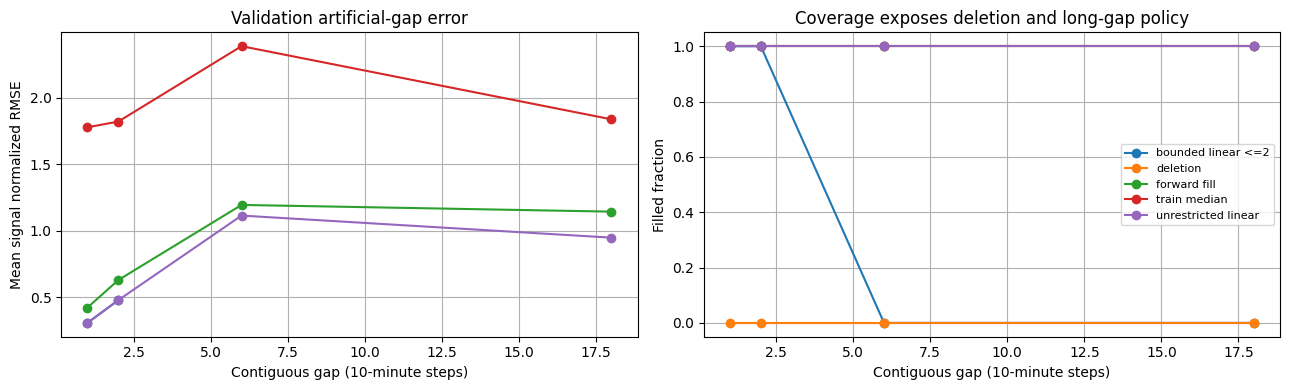

,signal,bounded_fill_enabled
0,wind,False
1,power,False
2,reactive,False
3,ambient,True
4,bearing,False
5,oil,False
6,rotor,False
7,generator,False
8,pitch,False
9,frequency,False


In [14]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
import pickle

scalar_signals = [c for c in SIGNALS if c not in ('direction', 'setpoint')]
cut = pd.Timestamp('2022-07-01', tz='UTC')
regular = pd.concat([g.assign(observed_row=True).set_index('timestamp').reindex(GRID).assign(turbine=t)
                     for t, g in df.groupby('turbine', sort=True)]).rename_axis('timestamp').reset_index()
regular = regular.sort_values(['turbine','timestamp']).reset_index(drop=True)
regular['observed_row'] = regular['observed_row'].fillna(False).astype(bool)
regular[list(SIGNALS)] = regular[list(SIGNALS)].replace([np.inf,-np.inf], np.nan)
regular['split'] = np.where(regular.timestamp < cut, 'train', 'validation')
regular['quarter'] = regular.timestamp.dt.quarter
train_raw = regular.loc[regular.split.eq('train'), list(SIGNALS)]
q1, q3 = train_raw.quantile(.25), train_raw.quantile(.75)
train_median = train_raw.median()
norm_scale = (q3-q1).where((q3-q1)>0, train_raw.std()).fillna(1).replace(0,1)

# Segments never cross turbine, quarter, or train/validation boundary.
segments = {(t,int(q)): g.set_index('timestamp')[scalar_signals].copy()
            for (t,q),g in regular.groupby(['turbine','quarter'],sort=True)}
rng = np.random.default_rng(2022)
gap_records, masks = [], {}
for key, x in segments.items():
    complete = x.notna().all(axis=1).to_numpy()
    for length in (1,2,6,18):
        candidates = np.flatnonzero(np.convolve(complete.astype(int), np.ones(length+2,dtype=int), 'valid') == length+2)+1
        rng.shuffle(candidates)
        chosen, occupied = [], np.zeros(len(x),dtype=bool)
        for start in candidates:
            if not occupied[start-1:start+length+1].any():
                chosen.append(int(start)); occupied[start-1:start+length+1] = True
            if len(chosen) == 24:
                break
        mask = np.zeros(len(x),dtype=bool)
        for start in chosen:
            mask[start:start+length] = True
        masks[key,length] = mask
        gap_records.append({'turbine':key[0],'quarter':key[1],'gap_steps':length,
                            'gaps':len(chosen),'hidden_rows':int(mask.sum())})
display(pd.DataFrame(gap_records))

def impute_segment(x, method):
    if method == 'deletion':
        return x.copy()
    if method == 'train median':
        return x.fillna(train_median[scalar_signals])
    if method == 'forward fill':
        return x.ffill()
    if method == 'unrestricted linear':
        return x.interpolate(method='time',limit_area='inside')
    return capped_interpolate(x,scalar_signals,2)

missing_rows = []
for (t,q), original in segments.items():
    for length in (1,2,6,18):
        mask = masks[(t,q),length]
        damaged = original.copy(); damaged.loc[mask,:] = np.nan
        for method in ('deletion','train median','forward fill','unrestricted linear','bounded linear <=2'):
            started = time.perf_counter(); filled = impute_segment(damaged,method)
            elapsed = time.perf_counter()-started
            for c in scalar_signals:
                truth = original.loc[mask,c].to_numpy()
                pred = filled.loc[mask,c].to_numpy()
                ok = np.isfinite(pred)
                err = (pred[ok]-truth[ok])/norm_scale[c]
                missing_rows.append(dict(turbine=t,quarter=q,split='train diagnostic' if q<=2 else 'validation',
                    gap_steps=length,signal=c,method=method,hidden=len(truth),filled=int(ok.sum()),
                    fill_fraction=ok.mean() if len(ok) else np.nan,
                    nRMSE=np.sqrt(np.mean(err**2)) if ok.any() else np.nan,
                    nMAE=np.mean(np.abs(err)) if ok.any() else np.nan,runtime_seconds=elapsed))
missing_benchmark = pd.DataFrame(missing_rows)
missing_summary = missing_benchmark.groupby(['split','gap_steps','method'])[['nRMSE','nMAE','fill_fraction']].mean()
display(missing_summary)
display(missing_benchmark[missing_benchmark.split.eq('validation')].groupby(['signal','gap_steps','method'])[['nRMSE','nMAE','fill_fraction']].mean())
# Runtime repeated per signal above; deduplicate before summing.
display(missing_benchmark.drop_duplicates(['turbine','quarter','gap_steps','method'])
        .groupby('method').runtime_seconds.agg(['sum','median']).rename(columns={'sum':'total_seconds'}))
fig, axes = plt.subplots(1,2,figsize=(13,4))
val_missing = missing_benchmark[missing_benchmark.split.eq('validation')]
for method,g in val_missing.groupby('method'):
    h=g.groupby('gap_steps')[['nRMSE','fill_fraction']].mean()
    axes[0].plot(h.index,h.nRMSE,marker='o',label=method)
    axes[1].plot(h.index,h.fill_fraction,marker='o',label=method)
axes[0].set(xlabel='Contiguous gap (10-minute steps)',ylabel='Mean signal normalized RMSE',title='Validation artificial-gap error')
axes[1].set(xlabel='Contiguous gap (10-minute steps)',ylabel='Filled fraction',title='Coverage exposes deletion and long-gap policy')
axes[1].legend(fontsize=8); plt.tight_layout(); plt.show()
# Conservative per-signal gate, checked separately for both short gap lengths.
short_stats = val_missing[val_missing.gap_steps.le(2)].groupby(['signal','gap_steps','method'])[['nRMSE','fill_fraction']].mean()
fill_allowed = []
for c in scalar_signals:
    accepted = True
    for length in (1,2):
        b=short_stats.loc[(c,length,'bounded linear <=2')]
        competitors=[short_stats.loc[(c,length,m),'nRMSE'] for m in ('train median','forward fill')]
        accepted &= bool(np.isfinite(b.nRMSE) and b.nRMSE <= .10 and b.fill_fraction >= .99
                         and b.nRMSE <= min(competitors))
    if accepted:
        fill_allowed.append(c)
display(pd.DataFrame({'signal':scalar_signals,'bounded_fill_enabled':[c in fill_allowed for c in scalar_signals]}))

### Outliers: empirical extremes are not automatically bad SCADA
Global training IQR fences (1.5 IQR), global training |z| > 3, winsorization at IQR fences, and conservative physical flag-only bounds are compared without using event labels. Zero-IQR/constant columns receive no empirical IQR fence; zero-variance z-scores do not divide by zero. Bounds are broad screening assumptions, **not calibrated sensor specifications**: wind 0–60 m/s, direction 0–360°, rotor/generator speeds nonnegative, temperatures −50–200°C and frequency 49–51 Hz. Zero frequency can describe power-off/shared-grid context: flag it, never delete it wholesale. Negative power is retained; power and setpoint limits are not invented.

Low-power/high-wind means wind ≥8 m/s and power ≤10% of each turbine's training 99th-percentile positive power. Rated-like means power ≥90% of that reference. These overlapping operating regimes are descriptive, not fault labels or certified nameplate rated power. Trimming loss counts complete rows removed by any signal, so its cost is visible even if a different signal triggers removal.

,method,split,regime,rows,flagged_or_changed,removed,loss_fraction,affected_fraction
0,IQR trimming,train,all,156384,34057,34057,0.217778,0.217778
1,IQR trimming,train,low-power/high-wind,2632,2632,2632,1.000000,1.000000
2,IQR trimming,train,rated-like,12515,6864,6864,0.548462,0.548462
3,IQR trimming,validation,all,158976,35869,35869,0.225625,0.225625
4,IQR trimming,validation,low-power/high-wind,1135,1135,1135,1.000000,1.000000
5,IQR trimming,validation,rated-like,6160,2937,2937,0.476786,0.476786
6,z-score trimming,train,all,156384,11351,11351,0.072584,0.072584
7,z-score trimming,train,low-power/high-wind,2632,2622,2622,0.996201,0.996201
8,z-score trimming,train,rated-like,12515,1022,1022,0.081662,0.081662
9,z-score trimming,validation,all,158976,13523,13523,0.085063,0.085063


,IQR_flags,z_flags,physical_flags
ambient,9612.0,6721.0,0
bearing,14279.0,9474.0,0
direction,NaN,NaN,0
frequency,153.0,46.0,46
generator,12.0,2.0,3803
oil,23246.0,12610.0,0
pitch,63203.0,15308.0,0
power,0.0,0.0,0
reactive,2.0,0.0,0
rotor,0.0,0.0,0


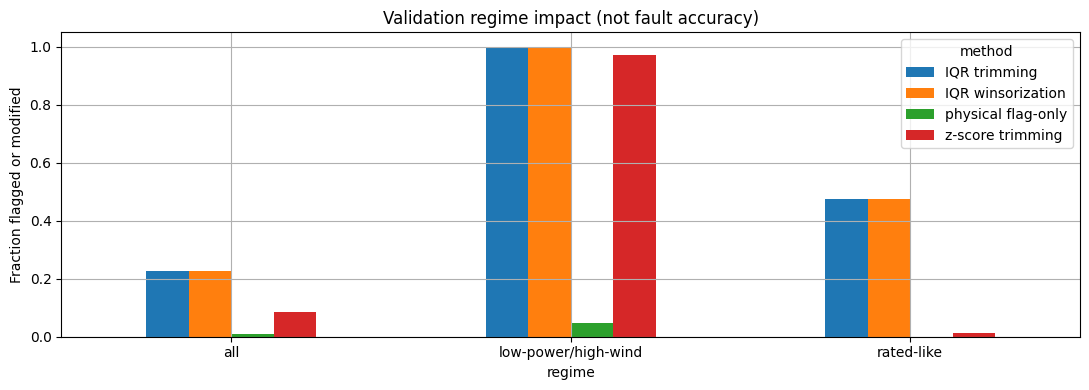

,signal,changed_cells,mean_absolute_change
0,wind,2522,0.014976
1,power,0,0.000000
2,reactive,2,0.000091
3,ambient,9612,0.107810
4,bearing,14279,0.413838
5,oil,23246,1.226261
6,rotor,0,0.000000
7,generator,12,0.005937
8,pitch,63203,8.257236
9,frequency,153,0.003458


In [15]:
emp_cols = [c for c in SIGNALS if c != 'direction']
iqr = q3-q1
lo,hi = q1-1.5*iqr,q3+1.5*iqr
lo[iqr.le(0)|iqr.isna()] = -np.inf; hi[iqr.le(0)|iqr.isna()] = np.inf
mu,sd = train_raw.mean(),train_raw.std()
sd = sd.where(sd>0)
iqr_flags = regular[emp_cols].lt(lo[emp_cols]) | regular[emp_cols].gt(hi[emp_cols])
z_flags = ((regular[emp_cols]-mu[emp_cols])/sd[emp_cols]).abs().gt(3)
physical_bounds = {'wind':(0,60),'direction':(0,360),'ambient':(-50,200),
                   'bearing':(-50,200),'oil':(-50,200),'rotor':(0,np.inf),
                   'generator':(0,np.inf),'frequency':(49,51)}
physical_flags = pd.DataFrame(False,index=regular.index,columns=list(SIGNALS))
for c,(low,high) in physical_bounds.items():
    physical_flags[c] = regular[c].lt(low) | regular[c].gt(high)
reference = regular[regular.split.eq('train') & regular.power.gt(0)].groupby('turbine').power.quantile(.99)
pref = regular.turbine.map(reference)
regimes = {'all':pd.Series(True,index=regular.index),
           'low-power/high-wind':regular.wind.ge(8)&regular.power.le(.1*pref),
           'rated-like':regular.power.ge(.9*pref)}
outlier_rows=[]
for method,flags,remove in [('IQR trimming',iqr_flags,True),('z-score trimming',z_flags,True),
                           ('IQR winsorization',iqr_flags,False),('physical flag-only',physical_flags,False)]:
    affected=flags.any(axis=1)
    for split in ('train','validation'):
        for name,regime in regimes.items():
            mask=regular.split.eq(split)&regime
            n=int(mask.sum()); hits=int((mask&affected).sum())
            outlier_rows.append(dict(method=method,split=split,regime=name,rows=n,flagged_or_changed=hits,
                removed=hits if remove else 0,loss_fraction=hits/n if remove and n else 0,
                affected_fraction=hits/n if n else np.nan))
outlier_benchmark=pd.DataFrame(outlier_rows)
display(outlier_benchmark)
display(pd.DataFrame({'IQR_flags':iqr_flags.sum(),'z_flags':z_flags.sum(),
                      'physical_flags':physical_flags.sum()}))
fig,ax=plt.subplots(figsize=(11,4))
outlier_benchmark.query("split == 'validation'").pivot(index='regime',columns='method',values='affected_fraction').plot.bar(ax=ax)
ax.set(ylabel='Fraction flagged or modified',title='Validation regime impact (not fault accuracy)');plt.xticks(rotation=0);plt.tight_layout();plt.show()
winsorized = regular[emp_cols].clip(lower=lo[emp_cols],upper=hi[emp_cols],axis=1)
display(pd.DataFrame({'signal':emp_cols,'changed_cells':(winsorized.ne(regular[emp_cols])&regular[emp_cols].notna()).sum().values,
                     'mean_absolute_change':(winsorized-regular[emp_cols]).abs().mean().values}))

### Scale and circular geometry
All fitted transforms use training data only. Robust versus standard choice measures tail sensitivity, central signal distance balance and validation range shift, not clustering correctness. A reproducible sample of pairs caps distance diagnostics at 10,000 pairs. For scaler fitting only, missing scalar features receive training medians; an all-empty training feature is excluded and reported. Exported natural missing values remain missing, not median-imputed. Direction is excluded from scaler comparison and later encoded as sin/cos with **one shared scale of 1**. Scaling sin/cos independently distorts their circular metric.

Per-turbine scaling can hide between-turbine levels. Per-window z-score can hide absolute wind/power/temperature levels; it is evaluated only inside fixed windows below, never applied as an unexplained global transform. Min–max validation excursions beyond [0,1] reveal train distribution shift; other transforms are not expected to lie in that interval.

,excluded_empty_training_feature


,method,max_distance_share,central_max_share,outside_training_range_fraction,tail_to_central_ratio,validation_outside_0_1
0,global none,0.489038,0.717779,0.003549,7.937954,NaN
1,global standard,0.448745,0.304932,0.003549,3.391825,NaN
2,global minmax,0.226507,0.306883,0.003549,1.490171,0.003549
3,global robust,0.617189,0.205425,0.003549,10.267206,NaN
4,per-turbine none,0.489038,0.717779,0.003549,7.937954,NaN
5,per-turbine standard,0.656891,0.272915,0.004801,4.295805,NaN
6,per-turbine minmax,0.184761,0.219844,0.007503,1.560923,0.007503
7,per-turbine robust,0.676969,0.198931,0.004064,14.466867,NaN


method,global minmax,global none,global robust,global standard,per-turbine minmax,per-turbine none,per-turbine robust,per-turbine standard
signal,,,,,,,,
ambient,0.119357,7.612512e-05,0.004382,0.110713,0.092963,7.612512e-05,0.003669,0.054697
bearing,0.046547,9.308490e-05,0.004429,0.065145,0.070621,9.308490e-05,0.003954,0.046902
frequency,0.000507,7.963339e-07,0.353321,0.448745,0.003088,7.963339e-07,0.297563,0.656891
generator,0.166818,4.672735e-01,0.002871,0.058194,0.146568,4.672735e-01,0.002492,0.031934
oil,0.095140,1.554706e-04,0.009353,0.062414,0.080181,1.554706e-04,0.008056,0.060162
pitch,0.017508,7.712220e-04,0.617189,0.053061,0.184761,7.712220e-04,0.676969,0.044634
power,0.177681,4.890384e-01,0.001694,0.045544,0.127361,4.890384e-01,0.001513,0.023157
reactive,0.121257,4.254767e-02,0.001869,0.050216,0.108789,4.254767e-02,0.001599,0.026106
rotor,0.226507,3.336026e-05,0.002862,0.058240,0.162161,3.336026e-05,0.002484,0.031939


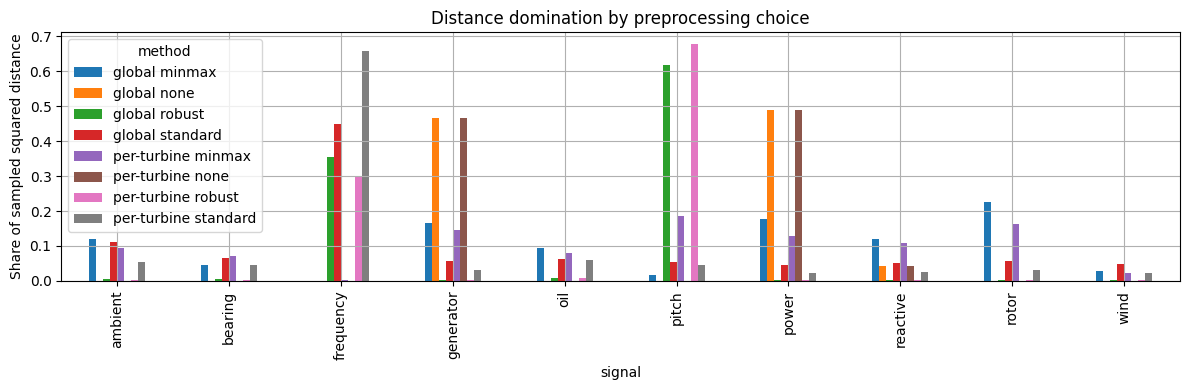

,a,b,raw_degrees,shortest_arc_degrees,equal_scale_sincos_distance
0,0.0,1.0,1.0,1.0,0.017453
1,0.0,359.0,359.0,1.0,0.017453
2,1.0,359.0,358.0,2.0,0.034905
3,0.0,180.0,180.0,180.0,2.000000


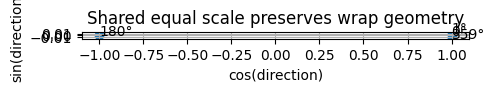

Measured scalar choice: standard


In [16]:
scale_cols=[c for c in scalar_signals if train_raw[c].notna().any()]
display(pd.DataFrame({'excluded_empty_training_feature':[c for c in scalar_signals if c not in scale_cols]}))
X = regular[scale_cols].fillna(train_median[scale_cols]).to_numpy()
train_mask=regular.split.eq('train').to_numpy(); val_mask=~train_mask
rng_scale=np.random.default_rng(2023)
vi=np.flatnonzero(val_mask); pairs=rng_scale.choice(vi,size=(min(10000,len(vi)),2),replace=True)
scalers={}; scale_rows=[]; distance_rows=[]
for scope in ('global','per-turbine'):
    for kind in ('none','standard','minmax','robust'):
        Z=np.empty_like(X,dtype=float); fitted={}
        groups=[('global',np.arange(len(X)))] if scope=='global' else [(t,g.index.to_numpy()) for t,g in regular.groupby('turbine')]
        for key,idx in groups:
            fit_idx=idx[train_mask[idx]]
            scaler={'standard':StandardScaler,'minmax':MinMaxScaler,'robust':RobustScaler}.get(kind)
            obj=scaler().fit(X[fit_idx]) if scaler else None
            Z[idx]=obj.transform(X[idx]) if obj else X[idx]
            fitted[key]=obj
        name=scope+' '+kind; scalers[name]=fitted
        contribution=(Z[pairs[:,0]]-Z[pairs[:,1]])**2
        share=contribution.sum(axis=0);share=share/share.sum() if share.sum() else share
        central=np.all(np.abs((regular[scale_cols].fillna(train_median[scale_cols]).to_numpy()-train_median[scale_cols].to_numpy())/norm_scale[scale_cols].to_numpy())<3,axis=1)
        pcentral=central[pairs[:,0]]&central[pairs[:,1]]
        central_share=contribution[pcentral].sum(axis=0);central_share=central_share/central_share.sum() if central_share.sum() else central_share
        train_min,train_max=Z[train_mask].min(axis=0),Z[train_mask].max(axis=0)
        excursion=((Z[val_mask]<train_min)|(Z[val_mask]>train_max)).mean()
        zval=Z[val_mask]
        tail_ratio=np.nanmean(np.quantile(np.abs(zval),.999,axis=0)/(np.quantile(np.abs(zval),.75,axis=0)+1e-12))
        scale_rows.append(dict(method=name,max_distance_share=float(share.max()),central_max_share=float(central_share.max()),
            outside_training_range_fraction=float(excursion),tail_to_central_ratio=float(tail_ratio),
            validation_outside_0_1=float(((zval<0)|(zval>1)).mean()) if kind=='minmax' else np.nan))
        distance_rows.extend(dict(method=name,signal=c,squared_distance_share=float(s)) for c,s in zip(scale_cols,share))
scale_benchmark=pd.DataFrame(scale_rows); distance_benchmark=pd.DataFrame(distance_rows)
display(scale_benchmark);display(distance_benchmark.pivot(index='signal',columns='method',values='squared_distance_share'))
fig,ax=plt.subplots(figsize=(12,4));distance_benchmark.pivot(index='signal',columns='method',values='squared_distance_share').plot.bar(ax=ax)
ax.set(ylabel='Share of sampled squared distance',title='Distance domination by preprocessing choice');plt.tight_layout();plt.show()
# Robust must preserve both central balance and full-distribution balance;
# tiny pitch IQR can amplify legitimate parked/shutdown modes.
scores=scale_benchmark.set_index('method')
robust_ok=(scores.loc['global robust','central_max_share']<=1.10*scores.loc['global standard','central_max_share']
           and scores.loc['global robust','max_distance_share']<=scores.loc['global standard','max_distance_share']
           and scores.loc['global robust','tail_to_central_ratio']<=scores.loc['global standard','tail_to_central_ratio'])
selected_scale='robust' if robust_ok else 'standard'
selected_scaler=scalers['global '+selected_scale]['global']
angles=np.array([0.,1.,359.,180.]);radians=np.deg2rad(angles)
angle_pairs=[(0,1),(0,2),(1,2),(0,3)]
circular_geometry=pd.DataFrame([dict(a=angles[a],b=angles[b],raw_degrees=abs(angles[a]-angles[b]),
    shortest_arc_degrees=min(abs(angles[a]-angles[b]),360-abs(angles[a]-angles[b])),
    equal_scale_sincos_distance=float(np.linalg.norm([np.sin(radians[a])-np.sin(radians[b]),np.cos(radians[a])-np.cos(radians[b])]))) for a,b in angle_pairs])
display(circular_geometry)
fig,ax=plt.subplots(figsize=(5,5));ax.scatter(np.cos(radians),np.sin(radians))
for angle,x,y in zip(angles,np.cos(radians),np.sin(radians)):ax.annotate(f'{angle:g}°',(x,y))
ax.set(xlabel='cos(direction)',ylabel='sin(direction)',title='Shared equal scale preserves wrap geometry',aspect='equal');plt.show()
print('Measured scalar choice:',selected_scale)

### Smoothing versus transition preservation
Trailing rolling mean and median over 3/6 steps use full windows, do not cross turbine, split or absent observations, and are retrospective comparisons only. Transition rows are the top decile of absolute consecutive power changes **defined from training**. Mean normalized absolute distortion, transition distortion and first-difference attenuation expose the cost of smoothing. No smoothing is recommended unless distortion improves a stated downstream objective; smoother curves alone are not evidence of better clusters.

distortion  transition_distortion  \
split      method steps                                      
train      mean   3        0.170701               0.223655   
                  6        0.256328               0.279451   
           median 3        0.160012               0.236558   
                  6        0.247518               0.285673   
           none   1        0.000000               0.000000   
validation mean   3        0.172989               0.266274   
                  6        0.258515               0.330028   
           median 3        0.160972               0.286125   
                  6        0.247060               0.338516   
           none   1        0.000000               0.000000   

                         power_difference_ratio  output_fraction  
split      method steps                                           
train      mean   3                    0.514014         0.999560  
                  6                    0.318981         0.998900  
           median 3                    0.518938         0.999560  
                  6                    0.321622         0.998900  
           none   1                    1.000000         1.000000  
validation mean   3                    0.522095         0.999596  
                  6                    0.324775         0.998989  
           median 3                    0.525366         0.999596  
                  6                    0.326692         0.998989  
           none   1                    1.000000         1.000000

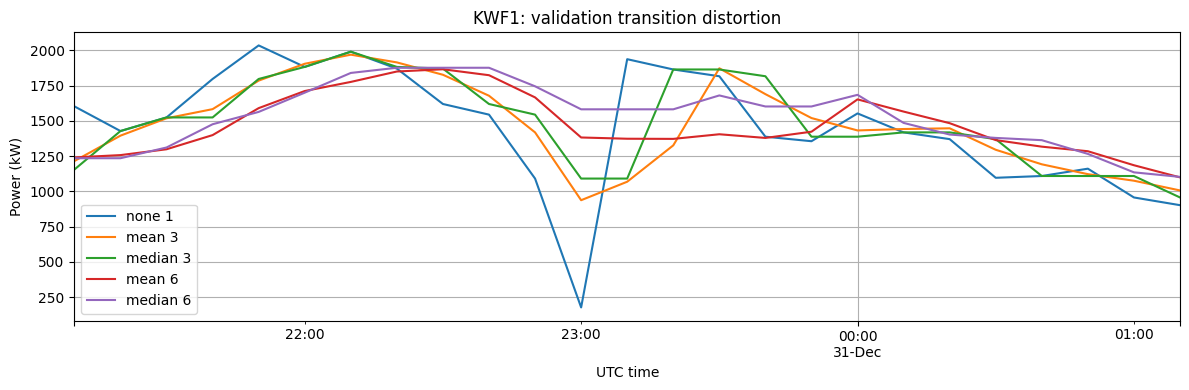

In [17]:
smooth_rows=[]; smoothing_examples={}
train_changes=[]
for (t,split),g in regular.groupby(['turbine','split'],sort=True):
    if split=='train':train_changes.extend(g.power.diff().abs().dropna().tolist())
transition_threshold=np.quantile(train_changes,.90) if train_changes else np.inf
for method,width in [('none',1),('mean',3),('median',3),('mean',6),('median',6)]:
    for (t,split),g in regular.groupby(['turbine','split'],sort=True):
        raw=g[scalar_signals]
        if method=='none':smoothed=raw.copy()
        else:
            rolling=raw.rolling(width,min_periods=width)
            smoothed=getattr(rolling,method)()
        transitions=g.power.diff().abs().ge(transition_threshold)
        delta=(smoothed-raw).abs().div(norm_scale[scalar_signals])
        smooth_rows.append(dict(method=method,steps=width,turbine=t,split=split,
            distortion=delta.mean().mean(),transition_distortion=delta.loc[transitions].mean().mean(),
            power_difference_ratio=smoothed.power.diff().abs().mean()/raw.power.diff().abs().mean(),
            output_fraction=smoothed.notna().sum().sum()/raw.notna().sum().sum()))
        if t==regular.turbine.iloc[0] and split=='validation':
            smoothing_examples[f'{method} {width}']=pd.Series(smoothed.power.values,index=g.timestamp)
smoothing_benchmark=pd.DataFrame(smooth_rows)
display(smoothing_benchmark.groupby(['split','method','steps'])[['distortion','transition_distortion','power_difference_ratio','output_fraction']].mean())
example_t=regular.turbine.iloc[0]
example=regular[regular.turbine.eq(example_t)&regular.split.eq('validation')].set_index('timestamp')
peak=example.power.diff().abs().idxmax() if example.power.diff().notna().any() else example.index[0]
fig,ax=plt.subplots(figsize=(12,4))
for name,s in smoothing_examples.items():s.loc[peak-pd.Timedelta('2h'):peak+pd.Timedelta('2h')].plot(ax=ax,label=name)
ax.set(xlabel='UTC time',ylabel='Power (kW)',title=f'{example_t}: validation transition distortion');ax.legend();plt.tight_layout();plt.show()

### Non-overlap windows, completeness, level loss and train-only PCA
Compare UTC-aligned 1h, 6h and 24h windows (6/36/144 ten-minute positions) at 90%, 95%, 100% completeness. Completeness is **minimum per-feature observed fraction**, not a permissive average over cells. Window boundaries never cross July 1. Shape comparison uses deterministic at-most-5,000 windows per duration, training-only feature medians for residual missing shape cells, and local z-score per signal. Local normalization has an irreversible ceiling: offset/level and amplitude disappear. Statistical windows retain mean, standard deviation, minimum, maximum and endpoint change, alongside circular direction means. PCA compares both statistical and locally normalized raw shapes, with 90%/95% training variance thresholds and validation reconstruction and sampled distance-preservation diagnostics.

Selection favors shortest duration/strictest threshold retaining ≥80% validation windows; if none meets that target, highest measured coverage wins, then shorter windows. This operational rule produces fixed-length exports, not evidence that a duration discovers correct clusters. PCA is benchmarked but not required for final statistical export: its retained variance cannot certify physical information preservation.

C:\College\Sem5\DATMIN\Kelmarsh_SCADA_2022_4457\.stage3_deps\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


,hours,threshold,split,total,kept,coverage
0,1,0.90,train,26064,25881,0.992979
1,1,0.90,validation,26496,26360,0.994867
2,1,0.95,train,26064,25881,0.992979
3,1,0.95,validation,26496,26360,0.994867
4,1,1.00,train,26064,25881,0.992979
5,1,1.00,validation,26496,26360,0.994867
6,6,0.90,train,4344,4301,0.990101
7,6,0.90,validation,4416,4392,0.994565
8,6,0.95,train,4344,4297,0.989180
9,6,0.95,validation,4416,4374,0.990489


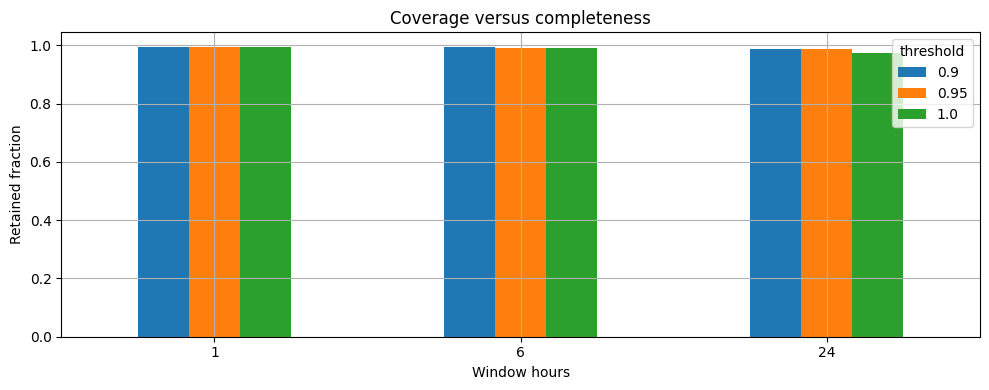

power_mean             local_power_mean                \
                        mean         std             mean           std   
hours split                                                               
1     train       626.104557  619.907466     8.205089e-17  4.607066e-15   
      validation  499.173267  522.010154    -2.099011e-18  1.622051e-15   
6     train       618.140766  589.075202     2.007759e-17  1.463947e-15   
      validation  502.187635  495.801051     5.087652e-17  9.833758e-16   
24    train       624.007253  524.897235     4.078940e-18  2.025347e-16   
      validation  502.876558  441.532540     4.020304e-18  1.991345e-16   

                 raw_power_std             local_power_std                
                          mean         std            mean           std  
hours split                                                               
1     train         101.219415  100.322509             1.0  9.015659e-17  
      validation     90.920959   91.457614             1.0  1.048502e-16  
6     train         192.841524  145.230195             1.0  1.049706e-16  
      validation    176.856439  135.623927             1.0  1.000338e-16  
24    train         311.737922  186.119351             1.0  7.051246e-17  
      validation    272.601467  159.189169             1.0  7.405730e-17

,hours,family,target,components,target_reached,training_variance,validation_normalized_reconstruction_rmse,distance_correlation,median_distance_ratio,original_features,train_windows,validation_windows
0,1,statistical,0.90,16,True,0.904351,0.545789,0.995907,0.935837,60,2353,2397
1,1,statistical,0.95,20,True,0.952920,0.499605,0.996309,0.969785,60,2353,2397
2,1,local-z raw shape,0.90,35,True,0.900218,0.332864,0.963640,0.946157,72,2353,2397
3,1,local-z raw shape,0.95,43,True,0.952164,0.232758,0.984144,0.977105,72,2353,2397
4,6,statistical,0.90,17,True,0.910131,5.759556,0.999992,0.940075,60,2151,2196
5,6,statistical,0.95,22,True,0.955216,5.634501,0.999994,0.970954,60,2151,2196
6,6,local-z raw shape,0.90,64,False,0.745937,0.555779,0.900824,0.833928,432,2151,2196
7,6,local-z raw shape,0.95,64,False,0.745937,0.555779,0.900824,0.833928,432,2151,2196
8,24,statistical,0.90,16,True,0.912356,0.365630,0.995024,0.926986,60,1067,1091
9,24,statistical,0.95,20,True,0.950318,0.284768,0.996864,0.959809,60,1067,1091


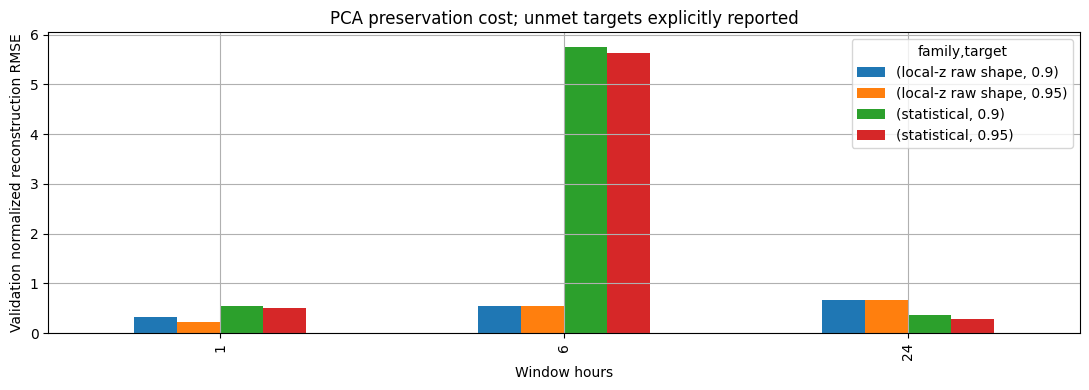

In [18]:
# Apply selected gap policy only within train/validation; preserve raw values and flags.
final_table=regular[['turbine','timestamp','split','observed_row']+list(SIGNALS)].copy()
for c in SIGNALS:
    final_table['raw_'+c]=regular[c]
    final_table['missing_'+c]=regular[c].isna()
    final_table['physical_'+c]=physical_flags[c]
    final_table['empirical_iqr_'+c]=iqr_flags[c] if c in iqr_flags else False
    final_table['empirical_z_'+c]=z_flags[c] if c in z_flags else False
for (t,split),g in regular.groupby(['turbine','split'],sort=True):
    if fill_allowed:
        filled=capped_interpolate(g.set_index('timestamp')[list(SIGNALS)],fill_allowed,2)
        final_table.loc[g.index,fill_allowed]=filled[fill_allowed].to_numpy()
for c in SIGNALS:
    final_table['filled_'+c]=regular[c].isna()&final_table[c].notna()
# Physical flag-only policy retains operating context (including zero frequency).
feature_frame=final_table[scale_cols].copy()
scaled_values=(feature_frame.to_numpy()-selected_scaler.center_)/selected_scaler.scale_ if selected_scale=='robust' else selected_scaler.transform(feature_frame)
for j,c in enumerate(scale_cols):final_table['scaled_'+c]=scaled_values[:,j]
valid_direction=final_table.direction.where(~physical_flags.direction)
final_table['direction_sin']=np.sin(np.deg2rad(valid_direction))
final_table['direction_cos']=np.cos(np.deg2rad(valid_direction))
window_cols=scale_cols+['direction_sin','direction_cos']
window_source=feature_frame.copy()
window_source['direction_sin']=final_table.direction_sin
window_source['direction_cos']=final_table.direction_cos
window_source['turbine']=regular.turbine
window_source['timestamp']=regular.timestamp
window_source['split']=regular.split
window_tables={}; window_shapes={}; coverage_rows=[]
for hours in (1,6,24):
    source=window_source.copy();source['window_start']=source.timestamp.dt.floor(f'{hours}h')
    grouped=source.groupby(['turbine','split','window_start'],sort=True)
    counts=grouped[window_cols].count();expected=hours*6
    completeness=counts.min(axis=1)/expected
    stat=grouped[window_cols].agg(['mean','std','min','max'])
    stat.columns=[f'{c}__{s}' for c,s in stat.columns]
    # Endpoint slope requires real valid endpoints, rather than skipping missing endpoints.
    first=source.drop_duplicates(['turbine','split','window_start'],keep='first').set_index(['turbine','split','window_start'])[window_cols]
    last=source.drop_duplicates(['turbine','split','window_start'],keep='last').set_index(['turbine','split','window_start'])[window_cols]
    slopes=(last-first).rename(columns=lambda c:c+'__endpoint_change')
    stat=stat.join(slopes);stat['completeness']=completeness
    window_tables[hours]=stat
    for threshold in (.90,.95,1.):
        for split in ('train','validation'):
            scope=completeness.index.get_level_values('split')==split
            n=int(scope.sum());kept=int((completeness[scope]>=threshold).sum())
            coverage_rows.append(dict(hours=hours,threshold=threshold,split=split,total=n,kept=kept,coverage=kept/n if n else np.nan))
    # Shape sample deterministic and bounded. Each group is full grid, never partial.
    keys=stat.index[stat.completeness.ge(.90)]
    if len(keys)>5000:
        key_train=keys[keys.get_level_values('split')=='train'];key_val=keys[keys.get_level_values('split')=='validation']
        keys=key_train[::max(1,int(np.ceil(len(key_train)/2500)))].append(key_val[::max(1,int(np.ceil(len(key_val)/2500)))])
    blocks=[];block_keys=[];level_rows=[]
    for key in keys:
        a=grouped.get_group(key)[window_cols].to_numpy()
        if len(a)!=expected:continue
        # Training medians only, circular means stay on equal coordinate scales.
        replacement=np.r_[train_median[scale_cols].to_numpy(),0.,0.]
        a=np.where(np.isfinite(a),a,replacement)
        mean=a.mean(axis=0);std=a.std(axis=0);std=np.where(std>0,std,1.)
        local=(a-mean)/std
        # Circular pair keeps one shared scale even in local shape normalization.
        circular_std=np.sqrt(np.mean(std[-2:]**2));local[:,-2:]=(a[:,-2:]-mean[-2:])/circular_std
        blocks.append(local.ravel());block_keys.append(key)
        level_rows.append({'hours':hours,'turbine':key[0],'split':key[1],'power_mean':mean[window_cols.index('power')],
                           'local_power_mean':local[:,window_cols.index('power')].mean(),
                           'raw_power_std':a[:,window_cols.index('power')].std(),'local_power_std':local[:,window_cols.index('power')].std()})
    window_shapes[hours]=(pd.MultiIndex.from_tuples(block_keys,names=stat.index.names),np.asarray(blocks),pd.DataFrame(level_rows))
window_benchmark=pd.DataFrame(coverage_rows)
display(window_benchmark)
fig,ax=plt.subplots(figsize=(10,4));window_benchmark.query("split == 'validation'").pivot(index='hours',columns='threshold',values='coverage').plot.bar(ax=ax)
ax.set(xlabel='Window hours',ylabel='Retained fraction',title='Coverage versus completeness');plt.xticks(rotation=0);plt.tight_layout();plt.show()
level_diagnostics=pd.concat([v[2] for v in window_shapes.values()],ignore_index=True)
display(level_diagnostics.groupby(['hours','split'])[['power_mean','local_power_mean','raw_power_std','local_power_std']].agg(['mean','std']))
# Level invariance is mathematical: shifted copies have the same local normalized shape.
example_shape=np.arange(6,dtype=float)
assert np.allclose((example_shape-example_shape.mean())/example_shape.std(),
                   ((example_shape+100)-(example_shape+100).mean())/(example_shape+100).std())

pca_rows=[];pca_models={}
for hours in (1,6,24):
    stat=window_tables[hours];stat=stat[stat.completeness.ge(.90)].drop(columns='completeness')
    # Bound statistical sample as well, deterministic train/validation separate.
    parts=[]
    for split in ('train','validation'):
        part=stat[stat.index.get_level_values('split')==split]
        parts.append(part.iloc[::max(1,int(np.ceil(len(part)/2500)))])
    stat=pd.concat(parts)
    shape_keys,shape_matrix,_=window_shapes[hours]
    for family,keys,matrix in [('statistical',stat.index,stat.to_numpy()),('local-z raw shape',shape_keys,shape_matrix)]:
        if len(matrix)<4:continue
        tr=keys.get_level_values('split')=='train';va=~tr
        if tr.sum()<3 or va.sum()<2:continue
        med=np.nanmedian(matrix[tr],axis=0)
        usable=np.isfinite(med)
        if not usable.any():continue
        matrix=matrix[:,usable];med=med[usable]
        matrix=np.where(np.isfinite(matrix),matrix,med)
        std_scaler=StandardScaler().fit(matrix[tr]);z=std_scaler.transform(matrix)
        # Full SVD can be costly for 24h shape vectors. Randomized fixed rank is bounded;
        # check variance coverage, never claim a target if cap cannot achieve it.
        rank=min(64,z.shape[1],int(tr.sum())-1)
        basis=PCA(n_components=rank,svd_solver='randomized',random_state=2022).fit(z[tr])
        cumulative=np.cumsum(basis.explained_variance_ratio_)
        for target in (.90,.95):
            reached=bool(cumulative[-1]>=target)
            k=int(np.searchsorted(cumulative,target)+1) if reached else rank
            components=basis.components_[:k]
            centered=z[va]-basis.mean_;embedded=centered@components.T
            reconstructed=embedded@components+basis.mean_
            rr=np.random.default_rng(2024);pair=rr.integers(0,len(centered),size=(min(2000,len(centered)),2))
            before=np.linalg.norm(centered[pair[:,0]]-centered[pair[:,1]],axis=1)
            after=np.linalg.norm(embedded[pair[:,0]]-embedded[pair[:,1]],axis=1)
            valid=before>1e-12
            correlation=np.corrcoef(before[valid],after[valid])[0,1] if valid.sum()>2 and np.std(after[valid])>0 and np.std(before[valid])>0 else np.nan
            pca_rows.append(dict(hours=hours,family=family,target=target,components=k,target_reached=reached,
                training_variance=float(cumulative[k-1]),validation_normalized_reconstruction_rmse=float(np.sqrt(np.mean((z[va]-reconstructed)**2))),
                distance_correlation=correlation,median_distance_ratio=float(np.median(after[valid]/before[valid])) if valid.any() else np.nan,
                original_features=matrix.shape[1],train_windows=int(tr.sum()),validation_windows=int(va.sum())))
        pca_models[(hours,family)]={'basis':basis,'scaler':std_scaler,'training_median':med,'usable_columns':usable}
pca_benchmark=pd.DataFrame(pca_rows);display(pca_benchmark)
fig,ax=plt.subplots(figsize=(11,4))
if not pca_benchmark.empty:
    pca_benchmark.pivot_table(index='hours',columns=['family','target'],values='validation_normalized_reconstruction_rmse').plot.bar(ax=ax)
ax.set(xlabel='Window hours',ylabel='Validation normalized reconstruction RMSE',title='PCA preservation cost; unmet targets explicitly reported');plt.tight_layout();plt.show()

### Additional transferable primitives from exact paper records
Wind percentile min–max uses **training 0.1th/99.9th percentiles** (not 5/95); no clipping masks validation excursions. Low-order orthonormal DCT-II retains 3/5 coefficients per channel and reports retained energy and reconstruction error. Correlation windows use Pearson/Spearman, at least half expected observations in every channel and nonzero within-window standard deviation in every channel. Mean downsampling averages direction vectors, not degree scalars. Pitch is already included in forward-fill artificial-gap comparison; this does not authorize blanket pitch filling in final table. Static clinical iterative imputation needs original static covariates; vibration FFT, learned triplet/neural embeddings and adaptive grid/density model stages are not reproduced.

,signal,training_p001,training_p999,validation_outside_0_1,distance_share
0,wind,0.484672,18.932870,0.001314,0.002712
1,power,-10.095537,2066.790216,0.001333,0.010025
2,reactive,-644.548467,0.000000,0.058615,0.009056
3,ambient,-0.193863,28.841587,0.040485,0.007985
4,bearing,8.269260,51.418610,0.016184,0.004421
5,oil,10.297500,59.820000,0.005452,0.005606
6,rotor,0.000000,15.251650,0.000354,0.012682
7,generator,-1.490361,1807.349412,0.001756,0.012629
8,pitch,0.000000,92.440002,0.003165,0.007981
9,frequency,49.860702,50.136330,0.002375,0.926903


,hours,split,coefficients_per_channel,windows,retained_energy,local_z_reconstruction_rmse
0,1,train,3,2353,0.664550,0.567421
1,1,validation,3,2397,0.671562,0.561776
2,1,train,5,2353,0.918382,0.279888
3,1,validation,5,2397,0.914916,0.285931
4,6,train,3,2151,0.438099,0.743960
5,6,validation,3,2196,0.430951,0.749730
6,6,train,5,2151,0.569931,0.650862
7,6,validation,5,2196,0.561330,0.658263
8,24,train,3,1067,0.418953,0.760029
9,24,validation,3,1091,0.390837,0.779445


windows  mean_normalized_RMSE  max_mean_level_error
hours coefficients                                                     
1     3                 977              0.273229          1.591616e-12
      5                 977              0.124574          1.364242e-12
6     3                 874              0.766427          2.046363e-12
      5                 874              0.670940          1.818989e-12
24    3                 538              1.303573          1.818989e-12
      5                 538              1.172015          2.046363e-12

,hours,signal,local_z_distance_share
0,1,wind,0.086519
1,1,power,0.086411
2,1,reactive,0.079228
3,1,ambient,0.086920
4,1,bearing,0.088954
5,1,oil,0.086679
6,1,rotor,0.084344
7,1,generator,0.086739
8,1,pitch,0.055781
9,1,frequency,0.084935


,hours,split,total,eligible,coverage,gate
0,1,train,26064,17219,0.660643,>=50% common complete-case rows and nonzero std every channel
1,1,validation,26496,16989,0.641191,>=50% common complete-case rows and nonzero std every channel
2,6,train,4344,3789,0.872238,>=50% common complete-case rows and nonzero std every channel
3,6,validation,4416,3933,0.890625,>=50% common complete-case rows and nonzero std every channel
4,24,train,1086,1039,0.956722,>=50% common complete-case rows and nonzero std every channel
5,24,validation,1104,1075,0.973732,>=50% common complete-case rows and nonzero std every channel


,turbine,split,window_start,pearson__wind__power,pearson__wind__reactive,pearson__wind__ambient,pearson__wind__bearing,pearson__wind__oil,pearson__wind__rotor,pearson__wind__generator,pearson__wind__pitch,pearson__wind__frequency,pearson__power__reactive,pearson__power__ambient,pearson__power__bearing,...,spearman__bearing__oil,spearman__bearing__rotor,spearman__bearing__generator,spearman__bearing__pitch,spearman__bearing__frequency,spearman__oil__rotor,spearman__oil__generator,spearman__oil__pitch,spearman__oil__frequency,spearman__rotor__generator,spearman__rotor__pitch,spearman__rotor__frequency,spearman__generator__pitch,spearman__generator__frequency,spearman__pitch__frequency
0,KWF1,train,2022-01-01 00:00:00+00:00,0.964029,-0.853785,0.112519,0.097204,-0.248091,0.922077,0.921456,0.566242,-0.140339,-0.903766,0.127828,0.085021,...,0.589189,0.094466,0.094981,0.309709,-0.100129,-0.258945,-0.263835,0.045462,0.249678,0.999743,0.483663,-0.169627,0.483663,-0.167568,-0.295502
1,KWF1,train,2022-01-02 00:00:00+00:00,0.987177,-0.943302,-0.545187,-0.655080,-0.608405,0.909221,0.910094,0.772257,-0.035043,-0.966116,-0.561806,-0.665566,...,0.387387,-0.577606,-0.585843,-0.318120,-0.036808,-0.588417,-0.586615,-0.280124,-0.348777,0.998198,0.668275,-0.189704,0.671255,-0.188160,-0.197428
2,KWF1,train,2022-01-03 00:00:00+00:00,0.898555,-0.865452,0.120656,0.532783,0.728971,0.574820,0.575210,0.914211,-0.101150,-0.893970,0.051457,0.543888,...,0.713256,0.172973,0.162420,0.563964,0.151094,0.541055,0.628829,0.747490,-0.175547,0.945431,0.552124,-0.357014,0.577091,-0.407465,0.035779
3,KWF1,train,2022-01-04 06:00:00+00:00,0.962995,-0.918473,-0.267904,0.023400,-0.321319,0.971349,0.971492,-0.727814,-0.221983,-0.953557,-0.152061,-0.013178,...,0.283912,0.065894,0.054569,-0.308491,-0.414157,-0.349550,-0.355212,0.059915,0.001030,0.997169,-0.555953,-0.294466,-0.557625,-0.280824,0.175007
4,KWF1,train,2022-01-05 12:00:00+00:00,0.948107,-0.534350,-0.303728,-0.088709,-0.341339,0.956448,0.956176,-0.560738,0.407169,-0.695353,-0.139053,-0.055544,...,-0.088546,-0.075161,-0.090862,-0.037580,-0.265894,-0.174775,-0.174260,0.068872,-0.043243,0.998713,-0.395592,0.454311,-0.394671,0.451995,-0.215052


wind        power    reactive  \
turbine split window_start                                                   
KWF1    train 2022-01-01 00:00:00+00:00  7.653549  1029.844294 -325.978024   
              2022-01-01 06:00:00+00:00  9.574245  1725.376975 -498.396811   
              2022-01-01 12:00:00+00:00  9.081859  1547.888543 -455.011427   
              2022-01-01 18:00:00+00:00  7.829921  1112.127715 -367.950210   
              2022-01-02 00:00:00+00:00  7.313149   895.718539 -297.391417   

                                           ambient    bearing        oil  \
turbine split window_start                                                 
KWF1    train 2022-01-01 00:00:00+00:00  12.933432  38.230610  53.000943   
              2022-01-01 06:00:00+00:00  13.218898  32.968805  52.156904   
              2022-01-01 12:00:00+00:00  13.487025  33.217036  51.715851   
              2022-01-01 18:00:00+00:00  12.575530  37.097219  52.095475   
              2022-01-02 00:00:00+00:00  12.102624  40.758702  54.357518   

                                             rotor    generator     pitch  \
turbine split window_start                                                  
KWF1    train 2022-01-01 00:00:00+00:00  14.025631  1662.705576  0.039806   
              2022-01-01 06:00:00+00:00  15.066013  1784.824753  1.332376   
              2022-01-01 12:00:00+00:00  14.854494  1759.129075  0.973100   
              2022-01-01 18:00:00+00:00  14.082921  1668.491077  0.188819   
              2022-01-02 00:00:00+00:00  13.232894  1568.463380  0.217972   

                                         frequency  direction_sin  \
turbine split window_start                                          
KWF1    train 2022-01-01 00:00:00+00:00  50.019958      -0.153595   
              2022-01-01 06:00:00+00:00  49.959587      -0.240435   
              2022-01-01 12:00:00+00:00  49.970238      -0.412048   
              2022-01-01 18:00:00+00:00  49.983072      -0.359840   
              2022-01-02 00:00:00+00:00  50.020704      -0.428146   

                                         direction_cos  \
turbine split window_start                               
KWF1    train 2022-01-01 00:00:00+00:00      -0.982838   
              2022-01-01 06:00:00+00:00      -0.963865   
              2022-01-01 12:00:00+00:00      -0.908207   
              2022-01-01 18:00:00+00:00      -0.930432   
              2022-01-02 00:00:00+00:00      -0.870058   

                                         direction_vector_length  \
turbine split window_start                                         
KWF1    train 2022-01-01 00:00:00+00:00                 0.994767   
              2022-01-01 06:00:00+00:00                 0.993400   
              2022-01-01 12:00:00+00:00                 0.997308   
              2022-01-01 18:00:00+00:00                 0.997591   
              2022-01-02 00:00:00+00:00                 0.969696   

                                         direction_vector_mean_degrees  \
turbine split window_start                                               
KWF1    train 2022-01-01 00:00:00+00:00                     188.882177   
              2022-01-01 06:00:00+00:00                     194.006521   
              2022-01-01 12:00:00+00:00                     204.403490   
              2022-01-01 18:00:00+00:00                     201.143714   
              2022-01-02 00:00:00+00:00                     206.201297   

                                         minimum_observed_fraction  
turbine split window_start                                          
KWF1    train 2022-01-01 00:00:00+00:00                        1.0  
              2022-01-01 06:00:00+00:00                        1.0  
              2022-01-01 12:00:00+00:00                        1.0  
              2022-01-01 18:00:00+00:00                        1.0  
              2022-01-02 00:00:00+00:00                        1.0

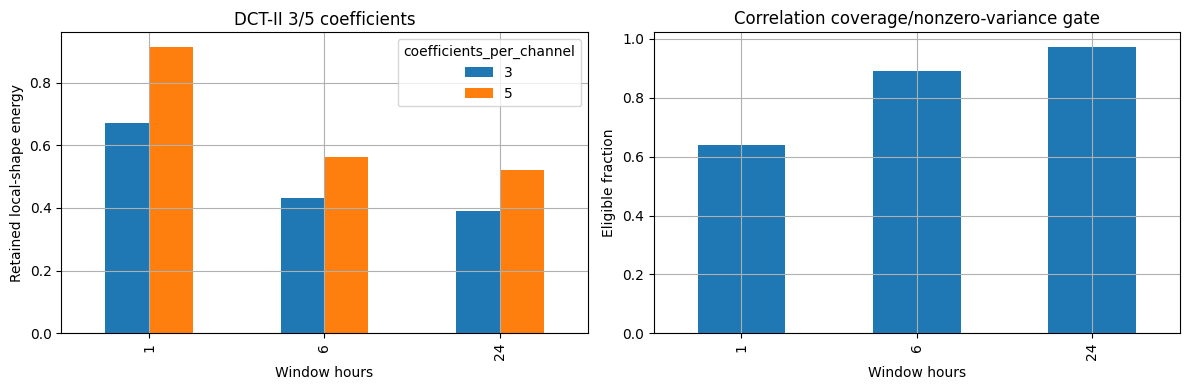

In [19]:
from scipy.fft import dct, idct
percentile_bounds=train_raw[scale_cols].quantile([.001,.999])
p_low=percentile_bounds.loc[.001];p_width=percentile_bounds.loc[.999]-p_low
p_width=p_width.where(p_width>0,1.)
p_scaled=(regular[scale_cols]-p_low)/p_width
p_filled=p_scaled.fillna((train_median[scale_cols]-p_low)/p_width).to_numpy()
p_contribution=(p_filled[pairs[:,0]]-p_filled[pairs[:,1]])**2
p_share=p_contribution.sum(axis=0);p_share=p_share/p_share.sum() if p_share.sum() else p_share
percentile_diagnostics=pd.DataFrame({'signal':scale_cols,'training_p001':p_low.values,
    'training_p999':percentile_bounds.loc[.999].values,
    'validation_outside_0_1':((p_scaled[val_mask]<0)|(p_scaled[val_mask]>1)).sum().values/p_scaled[val_mask].notna().sum().replace(0,np.nan).values,
    'distance_share':p_share})
display(percentile_diagnostics)
percentile_diagnostics.to_csv(OUT/'benchmark_percentile_minmax.csv',index=False)

dct_rows=[]
for hours,(keys,matrix,_) in window_shapes.items():
    if not len(matrix):continue
    a=matrix.reshape(len(matrix),hours*6,len(window_cols))
    coefficients=dct(a,type=2,norm='ortho',axis=1)
    for k in (3,5):
        keep=min(k,a.shape[1]);compressed=np.zeros_like(coefficients)
        compressed[:,:keep]=coefficients[:,:keep]
        restored=idct(compressed,type=2,norm='ortho',axis=1)
        for split in ('train','validation'):
            mask=keys.get_level_values('split')==split
            energy=np.sum(coefficients[mask]**2)
            dct_rows.append(dict(hours=hours,split=split,coefficients_per_channel=keep,windows=int(mask.sum()),
                retained_energy=np.sum(compressed[mask]**2)/energy if energy else np.nan,
                local_z_reconstruction_rmse=np.sqrt(np.mean((a[mask]-restored[mask])**2)) if mask.any() else np.nan))
dct_benchmark=pd.DataFrame(dct_rows);display(dct_benchmark)
dct_benchmark.to_csv(OUT/'benchmark_dct.csv',index=False)
# Paper DCT does not require per-window Z scoring; compare raw-level form too.
raw_dct_rows=[]
for hours in (1,6,24):
    source=regular.loc[regular.split.eq('validation'),['turbine','timestamp']+scale_cols].copy()
    source['window_start']=source.timestamp.dt.floor(f'{hours}h')
    group=source.groupby(['turbine','window_start'],sort=True)
    eligible=group[scale_cols].count().min(axis=1).eq(hours*6)
    keys=eligible.index[eligible][::max(1,int(np.ceil(eligible.sum()/1000)))]
    for key in keys:
        block=group.get_group(key)[scale_cols].to_numpy()
        coeff=dct(block,type=2,norm='ortho',axis=0)
        for count in (3,5):
            compressed=np.zeros_like(coeff);compressed[:count]=coeff[:count]
            restored=idct(compressed,type=2,norm='ortho',axis=0)
            err=(restored-block)/norm_scale[scale_cols].to_numpy()
            raw_dct_rows.append({'hours':hours,'coefficients':count,'normalized_RMSE':float(np.sqrt(np.mean(err**2))),
                'mean_level_error':float(np.max(np.abs(restored.mean(axis=0)-block.mean(axis=0))))})
raw_dct_benchmark=pd.DataFrame(raw_dct_rows)
display(raw_dct_benchmark.groupby(['hours','coefficients']).agg(windows=('normalized_RMSE','size'),
    mean_normalized_RMSE=('normalized_RMSE','mean'),max_mean_level_error=('mean_level_error','max')))
raw_dct_benchmark.to_csv(OUT/'benchmark_dct_raw_level.csv',index=False)
local_distance_rows=[]
for hours,(keys,matrix,_) in window_shapes.items():
    va=keys.get_level_values('split')=='validation'
    a=matrix[va].reshape(int(va.sum()),hours*6,len(window_cols))
    if len(a)<2:continue
    pair=np.random.default_rng(2025).integers(0,len(a),size=(min(2000,len(a)),2))
    energy=((a[pair[:,0]]-a[pair[:,1]])**2).sum(axis=(0,1))
    share=energy/energy.sum() if energy.sum() else energy
    local_distance_rows.extend(dict(hours=hours,signal=c,local_z_distance_share=float(s)) for c,s in zip(window_cols,share))
local_distance_benchmark=pd.DataFrame(local_distance_rows);display(local_distance_benchmark)
local_distance_benchmark.to_csv(OUT/'benchmark_per_window_z_distance.csv',index=False)

correlation_rows=[];correlation_tables={};downsample_tables={}
for hours in (1,6,24):
    src=regular[['turbine','timestamp','split']+scale_cols].copy()
    src['window_start']=src.timestamp.dt.floor(f'{hours}h')
    groups=src.groupby(['turbine','split','window_start'],sort=True)
    # Bette uses common complete-case rows, not pairwise or interpolated rows.
    complete_rows=src[scale_cols].notna().all(axis=1)
    eligible_src=src.loc[complete_rows]
    complete_groups=eligible_src.groupby(['turbine','split','window_start'],sort=True)
    counts=complete_groups.size().reindex(groups.size().index,fill_value=0)
    deviation=complete_groups[scale_cols].std().reindex(counts.index)
    gate=counts.ge(hours*6*.5)&deviation.gt(0).all(axis=1)
    keys=gate.index[gate]
    # Sample 1,000 per split/duration, deterministic; coverage gates use all windows.
    sampled=[]
    for split in ('train','validation'):
        subset=keys[keys.get_level_values('split')==split]
        sampled.extend(subset[::max(1,int(np.ceil(len(subset)/1000)))].tolist())
        scope=gate.index.get_level_values('split')==split
        correlation_rows.append(dict(hours=hours,split=split,total=int(scope.sum()),eligible=int(gate[scope].sum()),
            coverage=float(gate[scope].mean()),gate='>=50% common complete-case rows and nonzero std every channel'))
    feature_rows=[]
    upper=np.triu_indices(len(scale_cols),k=1)
    for key in sampled:
        block=complete_groups.get_group(key)[scale_cols]
        row={'turbine':key[0],'split':key[1],'window_start':key[2]}
        for method in ('pearson','spearman'):
            corr=block.corr(method=method,min_periods=max(2,int(hours*6*.5))).to_numpy()
            for i,j in zip(*upper):row[f'{method}__{scale_cols[i]}__{scale_cols[j]}']=corr[i,j]
        feature_rows.append(row)
    correlation_tables[hours]=pd.DataFrame(feature_rows)
    correlation_tables[hours].to_csv(OUT/f'correlation_windows_{hours}h_sample.csv.gz',index=False,compression='gzip')
    down_src=window_source.copy();down_src['window_start']=down_src.timestamp.dt.floor(f'{hours}h')
    down_groups=down_src.groupby(['turbine','split','window_start'],sort=True)
    down=down_groups[window_cols].mean()
    down['direction_vector_length']=np.hypot(down.direction_sin,down.direction_cos)
    down['direction_vector_mean_degrees']=np.mod(np.rad2deg(np.arctan2(down.direction_sin,down.direction_cos)),360)
    down.loc[down.direction_vector_length.le(1e-12),'direction_vector_mean_degrees']=np.nan
    down['minimum_observed_fraction']=down_groups[window_cols].count().min(axis=1)/(hours*6)
    downsample_tables[hours]=down
    down.reset_index().to_csv(OUT/f'mean_downsample_{hours}h.csv.gz',index=False,compression='gzip')
correlation_benchmark=pd.DataFrame(correlation_rows);display(correlation_benchmark)
display(correlation_tables[6].head());display(downsample_tables[6].head())
correlation_benchmark.to_csv(OUT/'benchmark_correlation_gates.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4))
dct_benchmark.query("split == 'validation'").pivot(index='hours',columns='coefficients_per_channel',values='retained_energy').plot.bar(ax=axes[0])
axes[0].set(xlabel='Window hours',ylabel='Retained local-shape energy',title='DCT-II 3/5 coefficients')
correlation_benchmark.query("split == 'validation'").plot.bar(x='hours',y='coverage',ax=axes[1],legend=False)
axes[1].set(xlabel='Window hours',ylabel='Eligible fraction',title='Correlation coverage/nonzero-variance gate');plt.tight_layout();plt.show()

## Additional manual comparisons: spline, KNN, means, density reconstruction, gradients, and PFA

These complete transferable methods found in the first four papers. Exact settings unavailable in papers are **benchmark choices**, never attributed as original parameters. Building binary-motion zero fill and contact-state forward fill cannot be transferred to wind power: missing power is not zero and setpoint may change during gaps. Clinical static iterative imputation is inapplicable to complete static turbine metadata. Full Time2Feat tsfresh calculator inventory and eight pairwise metrics are unspecified; benchmark uses compact interpretable statistics plus explicit pair metrics, not alleged full replication.

### Common-mask cubic spline, KNN, and turbine-mean reconstruction
Same heldout masks as previous experiment, now evaluate local 100-row contexts around deterministic validation gaps. Scalar variables only; all-channel missing rows expose KNN's lack of a temporal neighbor when every channel is absent. KNN uses five uniformly weighted neighbors and training-standardized physical variables; original paper does not give K. Cubic spline uses SciPy CubicSpline with natural boundary conditions, bounded to known endpoints. Both can bridge long gaps for comparison only; neither enters default exports. Turbine mean uses January–June values, not validation means.

nRMSE  fill_fraction
gap_steps method                                        
1         KNN k=5                0.408652            1.0
          cubic spline           0.138208            1.0
          local linear control   0.116307            1.0
          turbine training mean  1.118317            1.0
2         KNN k=5                0.577223            1.0
          cubic spline           0.344898            1.0
          local linear control   0.297454            1.0
          turbine training mean  1.335519            1.0
6         KNN k=5                0.524285            1.0
          cubic spline           0.458591            1.0
          local linear control   0.290546            1.0
          turbine training mean  1.210279            1.0
18        KNN k=5                0.825597            1.0
          cubic spline           1.484012            1.0
          local linear control   0.630680            1.0
          turbine training mean  1.403218            1.0

signal   gap_steps  method               
ambient  1          KNN k=5                  0.139294
                    local linear control     0.018066
                    turbine training mean    0.950253
         2          KNN k=5                  0.135633
                    local linear control     0.019889
                    turbine training mean    0.944897
         6          KNN k=5                  0.189903
                    local linear control     0.033428
                    turbine training mean    0.917252
         18         KNN k=5                  0.244953
                    local linear control     0.053383
                    turbine training mean    0.895361
pitch    1          KNN k=5                  0.089365
                    local linear control     0.286228
                    turbine training mean    5.605895
         2          KNN k=5                  1.023570
                    local linear control     1.537972
                    turbine training mea

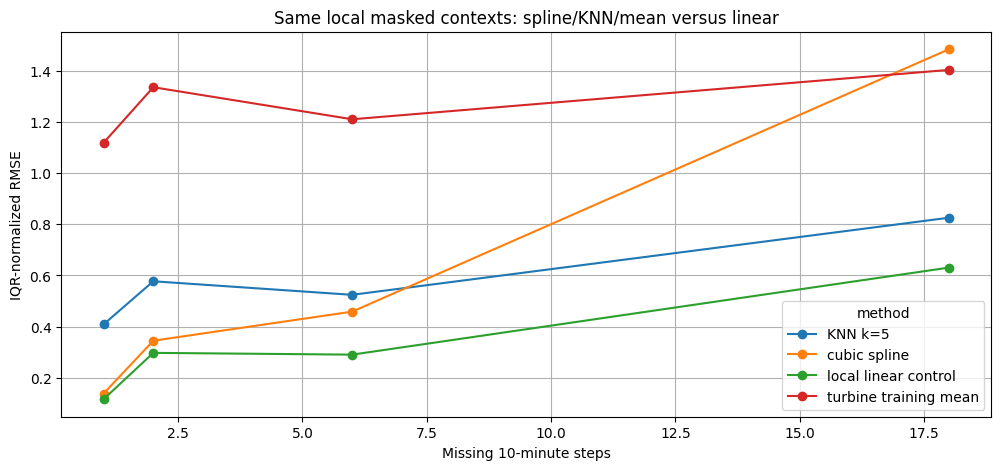

In [20]:
from scipy.interpolate import CubicSpline
from sklearn.impute import KNNImputer
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
supplement_missing=[]
fit_mean=regular.loc[regular.split.eq('train')].groupby('turbine')[scalar_signals].mean()
partial_missing=[]
fit_std=regular.loc[regular.split.eq('train'),scalar_signals].std().replace(0,1)
for (t,q),original in segments.items():
    if q<=2:continue
    for length in (1,2,6,18):
        mask=masks[(t,q),length]
        starts=np.flatnonzero(mask & ~np.r_[False,mask[:-1]])[:6]
        for start in starts:
            left=max(0,start-40);right=min(len(original),start+length+40)
            truth=original.iloc[left:right].copy(); damaged=truth.copy()
            hidden=np.arange(start-left,start-left+length)
            damaged.iloc[hidden]=np.nan
            outputs={'turbine training mean':damaged.fillna(fit_mean.loc[t])}
            spline=damaged.copy();time_axis=np.arange(len(damaged),dtype=float)
            for c in scalar_signals:
                known=damaged[c].notna().to_numpy()
                if known.sum()>=4:
                    model=CubicSpline(time_axis[known],damaged.loc[known,c],bc_type='natural',extrapolate=False)
                    spline.loc[~known,c]=model(time_axis[~known])
            outputs['cubic spline']=spline
            z=(damaged-train_median[scalar_signals])/fit_std
            knn=KNNImputer(n_neighbors=5,weights='uniform').fit_transform(z)
            outputs['KNN k=5']=pd.DataFrame(knn,index=damaged.index,columns=scalar_signals)*fit_std+train_median[scalar_signals]
            outputs['local linear control']=damaged.interpolate(method='time',limit_area='inside')
            for method,result in outputs.items():
                for c in scalar_signals:
                    actual=truth[c].iloc[hidden].to_numpy();pred=result[c].iloc[hidden].to_numpy()
                    ok=np.isfinite(pred)&np.isfinite(actual)
                    error=(pred[ok]-actual[ok])/norm_scale[c]
                    supplement_missing.append({'turbine':t,'quarter':q,'gap_steps':length,'signal':c,'method':method,
                        'nRMSE':float(np.sqrt(np.mean(error**2))) if ok.any() else np.nan,'fill_fraction':float(ok.mean())})
            # Natural sensor-specific gaps differ from complete acquisition outages.
            partial=truth.copy(); partial.iloc[hidden,[partial.columns.get_loc(c) for c in ['ambient','pitch']]]=np.nan
            pz=(partial-train_median[scalar_signals])/fit_std
            pk=KNNImputer(n_neighbors=5,weights='uniform').fit_transform(pz)
            partial_outputs={'KNN k=5':pd.DataFrame(pk,index=partial.index,columns=scalar_signals)*fit_std+train_median[scalar_signals],
                'local linear control':partial.interpolate(method='time',limit_area='inside'),
                'turbine training mean':partial.fillna(fit_mean.loc[t])}
            for method,result in partial_outputs.items():
                for c in ['ambient','pitch']:
                    err=(result[c].iloc[hidden].to_numpy()-truth[c].iloc[hidden].to_numpy())/norm_scale[c]
                    partial_missing.append({'turbine':t,'quarter':q,'gap_steps':length,'signal':c,'method':method,
                        'nRMSE':float(np.sqrt(np.nanmean(err**2)))})
supplement_missing=pd.DataFrame(supplement_missing)
display(supplement_missing.groupby(['gap_steps','method'])[['nRMSE','fill_fraction']].mean())
supplement_missing.to_csv(OUT/'benchmark_spline_knn_mean.csv',index=False)
partial_missing=pd.DataFrame(partial_missing)
display(partial_missing.groupby(['signal','gap_steps','method']).nRMSE.mean())
partial_missing.to_csv(OUT/'benchmark_sensor_specific_knn.csv',index=False)
fig,ax=plt.subplots(figsize=(12,5))
supplement_missing.groupby(['gap_steps','method']).nRMSE.mean().unstack().plot(marker='o',ax=ax)
ax.set(xlabel='Missing 10-minute steps',ylabel='IQR-normalized RMSE',title='Same local masked contexts: spline/KNN/mean versus linear');plt.show()

### Density-based cleaning and regression replacement

Forecast paper names DBSCAN and linear-regression extrapolation but leaves dimensions, epsilon, minimum density, predictors and regression history unspecified. Adaptation below fits joint wind/power DBSCAN on a deterministic 10,000-row January–June sample, standardizes both variables using training statistics, and compares epsilon 0.10/0.20/0.40 with min_samples=20. Validation point is outside training density when no core neighbor lies within epsilon. This is a density-screen transfer, not original full-data DBSCAN replication; low-density regimes may be valid.

Regression replacement uses six preceding valid nonflagged observations in same turbine and partition to extrapolate power. No event labels. Quantify changed values, lost transition information and negative or above-nameplate replacements. Natural outlier truth unavailable: smaller residual is not evidence replacement is correct. Policy remains flag-only.

,eps,min_samples,train_sample,core_points,train_noise_fraction,validation_flag_fraction,low_power_high_wind_flag_fraction
0,0.1,20,9733,9323,0.022912,0.013322,0.435242
1,0.2,20,9733,9611,0.008322,0.005098,0.061674
2,0.4,20,9733,9680,0.003082,0.000651,0.002643


,eps,turbine,flagged,replaced,mean_abs_change_kW,replacement_outside_0_2050,first_difference_MAE_kW
0,0.1,KWF1,268,63,347.588127,5,1.652957
1,0.1,KWF2,681,155,218.838272,31,2.564640
2,0.1,KWF3,226,65,360.109680,14,1.746720
3,0.1,KWF4,274,66,318.249868,12,1.588241
4,0.1,KWF5,433,78,315.293590,9,1.858874
5,0.1,KWF6,227,51,306.710377,5,1.190111
6,0.2,KWF1,116,23,505.246991,5,0.867406
7,0.2,KWF2,192,36,292.583788,14,0.796387
8,0.2,KWF3,113,22,483.483604,5,0.781343
9,0.2,KWF4,130,17,279.932283,4,0.359837


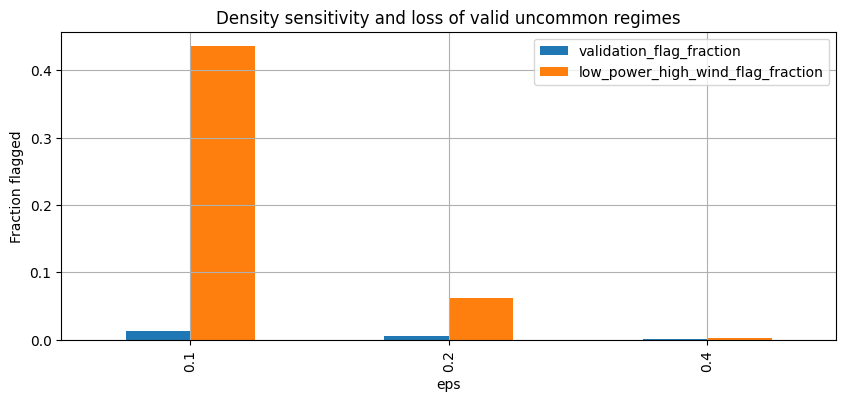

In [21]:
density_columns=['wind','power']
train_density=regular.loc[regular.split.eq('train'),density_columns].dropna()
sample_density=train_density.iloc[::max(1,int(np.ceil(len(train_density)/10000)))]
density_scaler=StandardScaler().fit(train_density)
fit_z=density_scaler.transform(sample_density)
validation_density=regular.loc[regular.split.eq('validation'),density_columns].dropna()
val_z=density_scaler.transform(validation_density)
density_rows=[];density_flags={}
for eps in (.10,.20,.40):
    model=DBSCAN(eps=eps,min_samples=20).fit(fit_z)
    cores=fit_z[model.core_sample_indices_]
    if len(cores):
        distances=NearestNeighbors(n_neighbors=1).fit(cores).kneighbors(val_z,return_distance=True)[0][:,0]
        flagged=distances>eps
    else:flagged=np.ones(len(val_z),dtype=bool)
    index=validation_density.index
    full_flags=pd.Series(False,index=regular.index);full_flags.loc[index]=flagged
    density_flags[eps]=full_flags
    regime=regular.loc[index,'wind'].ge(8)&regular.loc[index,'power'].le(205)
    density_rows.append({'eps':eps,'min_samples':20,'train_sample':len(fit_z),'core_points':len(cores),
        'train_noise_fraction':float((model.labels_==-1).mean()),'validation_flag_fraction':float(flagged.mean()),
        'low_power_high_wind_flag_fraction':float(flagged[regime.to_numpy()].mean()) if regime.any() else np.nan})
density_benchmark=pd.DataFrame(density_rows);display(density_benchmark)
density_benchmark.to_csv(OUT/'benchmark_dbscan.csv',index=False)
regression_rows=[]
for eps,flag in density_flags.items():
    for turbine,g in regular.loc[regular.split.eq('validation')].groupby('turbine'):
        raw=g.power.to_numpy();marked=flag.loc[g.index].to_numpy();pred=raw.copy()
        for i in np.flatnonzero(marked):
            if i<6:continue
            values=raw[i-6:i]
            if np.isfinite(values).all() and not marked[i-6:i].any():
                coefficient=np.polyfit(np.arange(6),values,1)
                pred[i]=np.polyval(coefficient,6)
        changed=np.isfinite(raw)&np.isfinite(pred)&(raw!=pred)
        regression_rows.append({'eps':eps,'turbine':turbine,'flagged':int(marked.sum()),'replaced':int(changed.sum()),
            'mean_abs_change_kW':float(np.mean(np.abs(pred[changed]-raw[changed]))) if changed.any() else np.nan,
            'replacement_outside_0_2050':int(((pred<0)|(pred>2050))[changed].sum()),
            'first_difference_MAE_kW':float(np.nanmean(np.abs(np.diff(pred)-np.diff(raw))))})
regression_benchmark=pd.DataFrame(regression_rows);display(regression_benchmark)
regression_benchmark.to_csv(OUT/'benchmark_regression_replacement.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4));density_benchmark.plot.bar(x='eps',y=['validation_flag_fraction','low_power_high_wind_flag_fraction'],ax=ax)
ax.set(ylabel='Fraction flagged',title='Density sensitivity and loss of valid uncommon regimes');plt.show()

### Temporal gradients, first differences, and overlapping windows

Building paper uses length-preserving finite-difference gradient with one-sided endpoints and centered interior differences, not successive n−1 differences. Forecast paper uses first differences of wind and cosine similarity. Both remove absolute levels: operating-regime clustering needs power/temperature level, so benchmark retains differences only as optional additional features. Compute per independent complete six-hour window; never cross turbine, gap, partition or session boundaries.

Overlap can improve localization but creates correlated near-duplicate objects. Compare six-hour windows with 0%, 25%, 50% overlap, using full input timeline and 95% per-channel completeness. Split boundaries remain hard barriers.

,power_mean,wind_mean,wind_gradient_RMS_per_minute,wind_difference_RMS,trend_nonzero_norm
split,,,,,
train,612.524209,6.163710,0.046145,0.693316,1.0
validation,486.495975,5.688696,0.042676,0.647981,1.0


candidate_windows  kept  coverage
split      overlap                                   
train      0.00                  4344  4297  0.989180
           0.25                  5790  5732  0.989983
           0.50                  8682  8584  0.988712
validation 0.00                  4416  4374  0.990489
           0.25                  5886  5828  0.990146
           0.50                  8826  8740  0.990256

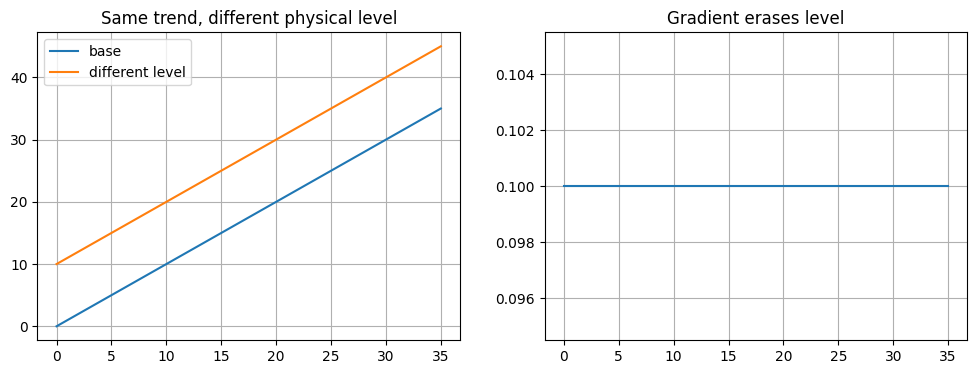

In [22]:
gradient_rows=[];overlap_rows=[]
for (t,split),g in regular.groupby(['turbine','split'],sort=True):
    x=g[scale_cols].to_numpy(); expected=36
    for overlap in (0,.25,.5):
        stride=int(expected*(1-overlap));starts=np.arange(0,len(x)-expected+1,stride)
        kept=0
        for start in starts:
            block=x[start:start+expected]
            if (np.isfinite(block).sum(axis=0)/expected>=.95).all():kept+=1
        overlap_rows.append({'turbine':t,'split':split,'overlap':overlap,'stride_steps':stride,'candidate_windows':len(starts),'kept':kept,'coverage':kept/len(starts)})
    for start in np.arange(0,len(x)-expected+1,expected)[::10]:
        block=x[start:start+expected]
        if not np.isfinite(block).all():continue
        wind=block[:,scale_cols.index('wind')];power=block[:,scale_cols.index('power')]
        grad=np.gradient(wind,10.)
        difference=np.diff(wind)
        centered=difference-difference.mean(); norm=np.linalg.norm(centered)
        gradient_rows.append({'turbine':t,'split':split,'power_mean':power.mean(),'wind_mean':wind.mean(),
            'wind_gradient_RMS_per_minute':np.sqrt(np.mean(grad**2)),'wind_difference_RMS':np.sqrt(np.mean(difference**2)),
            'trend_nonzero_norm':bool(norm>1e-12)})
gradient_benchmark=pd.DataFrame(gradient_rows);overlap_benchmark=pd.DataFrame(overlap_rows)
display(gradient_benchmark.groupby('split').mean(numeric_only=True))
overlap_summary=overlap_benchmark.groupby(['split','overlap'])[['candidate_windows','kept']].sum()
overlap_summary['coverage']=overlap_summary.kept/overlap_summary.candidate_windows
display(overlap_summary)
gradient_benchmark.to_csv(OUT/'benchmark_gradient_difference.csv',index=False)
overlap_benchmark.to_csv(OUT/'benchmark_overlap.csv',index=False)
base=np.arange(36,dtype=float);shifted=base+10
assert np.allclose(np.gradient(base,10),np.gradient(shifted,10))
assert np.allclose(np.diff(base),np.diff(shifted))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(base,label='base');axes[0].plot(shifted,label='different level');axes[0].legend();axes[0].set_title('Same trend, different physical level')
axes[1].plot(np.gradient(base,10),label='both gradients');axes[1].set_title('Gradient erases level');plt.show()

### Feature cleaning and PFA-style representative selection

Time2Feat removes derived feature columns containing missing/infinite values or zero variance, then PFA selects original interpretable features. Unlike PCA, selected coordinates retain feature names. Exact PFA dimensionality and representative rules are not supplied. Adaptation: January–June statistical windows; remove any nonfinite or zero-variance training column; standardize; PCA retain 95% training variance; cluster variable loading vectors using KMeans into 8/16/32 groups and choose nearest variable to each centroid. These explicit settings are our benchmark, not paper defaults. Compare validation distance preservation, not fault accuracy. Validation missing values use training medians only for diagnostic distances. Full current-default tsfresh extraction and PFA comparison follow separately; exact original calculator inventory remains unspecified.

In [23]:
statistical=window_tables[6].loc[window_tables[6].completeness.ge(.95)].drop(columns='completeness')
tr=statistical.index.get_level_values('split')=='train';va=~tr
keep=np.isfinite(statistical.loc[tr]).all(axis=0)&statistical.loc[tr].std().gt(0)
clean=statistical.loc[:,keep]
clean=clean.fillna(clean.loc[tr].median())
pfa_scale=StandardScaler().fit(clean.loc[tr]);z=pfa_scale.transform(clean)
pfa_basis=PCA(n_components=.95,svd_solver='full').fit(z[tr])
loading=pfa_basis.components_.T
pair=np.random.default_rng(2022).integers(0,int(va.sum()),size=(2000,2));v=z[va]
base_distance=np.linalg.norm(v[pair[:,0]]-v[pair[:,1]],axis=1);nonzero=base_distance>1e-12
pfa_rows=[];pfa_names={}
for count in (8,16,32):
    count=min(count,len(clean.columns))
    grouping=KMeans(n_clusters=count,n_init=10,random_state=2022).fit(loading)
    chosen=[]
    for label in range(count):
        members=np.flatnonzero(grouping.labels_==label)
        if len(members):chosen.append(int(members[np.argmin(np.linalg.norm(loading[members]-grouping.cluster_centers_[label],axis=1))]))
    after=np.linalg.norm(v[pair[:,0]][:,chosen]-v[pair[:,1]][:,chosen],axis=1)
    pfa_rows.append({'selected_features':len(chosen),'clean_features':len(clean.columns),'removed_features':int((~keep).sum()),
        'distance_correlation':float(np.corrcoef(base_distance[nonzero],after[nonzero])[0,1]),
        'median_distance_ratio':float(np.median(after[nonzero]/base_distance[nonzero]))})
    pfa_names[str(count)]=clean.columns[chosen].tolist()
pfa_benchmark=pd.DataFrame(pfa_rows);display(pfa_benchmark);display(pfa_names)
pfa_benchmark.to_csv(OUT/'benchmark_pfa_adaptation.csv',index=False)
(OUT/'pfa_selected_feature_names.json').write_text(json.dumps(pfa_names,indent=2),encoding='utf-8')

,selected_features,clean_features,removed_features,distance_correlation,median_distance_ratio
0,8,60,0,0.154225,0.389844
1,16,60,0,0.947151,0.550432
2,32,60,0,0.994149,0.751735


{'8': ['rotor__mean',
  'pitch__mean',
  'direction_sin__endpoint_change',
  'direction_cos__endpoint_change',
  'frequency__max',
  'direction_sin__mean',
  'ambient__endpoint_change',
  'ambient__max'],
 '16': ['wind__mean',
  'rotor__mean',
  'direction_sin__mean',
  'ambient__endpoint_change',
  'generator__std',
  'direction_cos__endpoint_change',
  'bearing__mean',
  'ambient__mean',
  'direction_sin__endpoint_change',
  'oil__endpoint_change',
  'frequency__endpoint_change',
  'frequency__max',
  'direction_sin__std',
  'wind__endpoint_change',
  'ambient__std',
  'bearing__std'],
 '32': ['pitch__mean',
  'rotor__mean',
  'ambient__endpoint_change',
  'ambient__mean',
  'generator__std',
  'direction_sin__mean',
  'frequency__max',
  'direction_cos__endpoint_change',
  'direction_sin__endpoint_change',
  'bearing__mean',
  'direction_cos__std',
  'oil__endpoint_change',
  'wind__endpoint_change',
  'direction_sin__std',
  'frequency__mean',
  'ambient__std',
  'bearing__std',
  

1467

### Manual cutover decision after supplemental comparisons

Spline/KNN/mean, DBSCAN/regression, gradient-only, overlap and PFA alternatives are run above, but do not change conservative final manifest without evidence aligned to operating-regime objective. Compare reconstruction tables: overshoot and multi-signal outages undermine spline/KNN assumptions; density screening can flag uncommon real states; regression fabricates physical readings; gradient erases levels; overlap inflates dependent objects; compact PFA sacrifices some geometry and must earn its complexity. Selected pipeline retains direct physical statistics and no anonymous projection. Any superior supplemental reconstruction score applies to synthetic masks only, not proof natural outage interpolation is safe. A downstream forecasting or fault-specific objective would need its own selection criteria.

**Not transferable as stated:** building active-hour exclusions (wind farm operates 24/7), motion zero-fill/contact carry-forward (different sensor semantics), supervised ANOVA/forecast-target Pearson/NWP-conditioned sample selection (unlabeled operating-regime goal), high-frequency vibration Hann/FFT spectra (10-minute averages cannot recover raw spectra), neural embeddings and adaptive-grid cluster density (model stages), label-based selection and changepoint postprocessing (not raw preprocessing). Circular-shift augmentation is not used: rotations wrap unrelated endpoints and would alter chronological transition interpretation. No source method is silently described as executed whole-paper replication.

### Full Time2Feat feature-extraction family: explicit current-library adaptation

Run tsfresh `ComprehensiveFCParameters` on 120 complete 24-hour turbine sequences (10 deterministic windows per turbine per fitting/validation split). Original paper names 700+ features but does not specify exact calculator version/settings; current comprehensive defaults are our reproducible adaptation, not exact original feature inventory. All six turbines and both year halves represented. Sampling caps computation and makes feature redundancy/undefined outputs visible; it is not full-year clustering. Add four explicitly documented pairwise families: Pearson correlation, Euclidean, L1, and Chebyshev distances. Other four original pair metrics were unspecified and are not invented. Raw physical units require feature normalization after extraction.

Compare feature-cleaning losses and PFA-style 8/16/32-feature selections against full cleaned feature geometry. No labels used. More features are not automatically more signal; short-sequence calculators can be undefined. Export names and settings/version so comparison can be reproduced.

{'library': 'tsfresh',
 'version': '0.21.2',
 'sequences': 120,
 'samples_per_sequence': 144,
 'input_channels': 10,
 'extracted_features': 8010,
 'training_nonfinite_columns': 1297,
 'training_constant_columns': 472,
 'training_nonpositive_or_undefined_variance_columns': 1567,
 'retained_columns': 6241,
 'elapsed_seconds': 85.40871480000169}

,representatives,clean_features,validation_distance_correlation,median_distance_ratio
0,8,6241,0.022030,0.007013
1,16,6241,0.017185,0.010475
2,32,6241,0.417063,0.017748


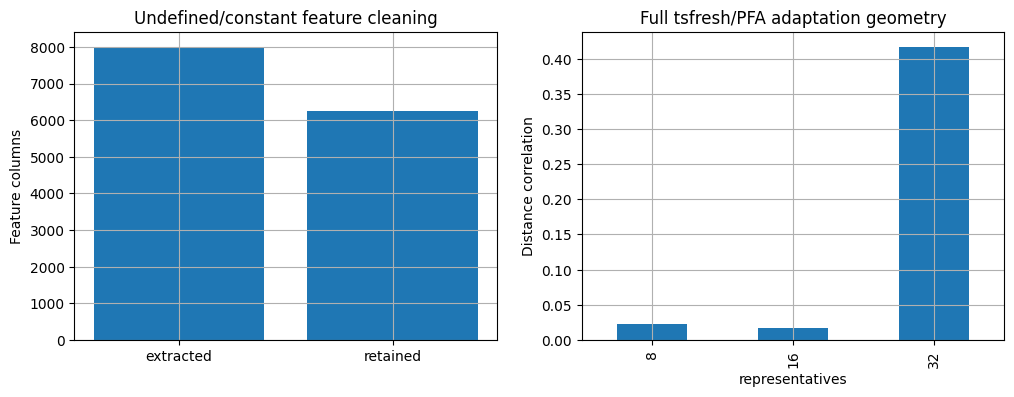

In [24]:
import tsfresh
from tsfresh import extract_features
from tsfresh.feature_extraction import ComprehensiveFCParameters
from itertools import combinations
feature_blocks=[];sequence_meta=[];pair_rows=[];seq=0
for (t,split),g in regular.groupby(['turbine','split'],sort=True):
    group=g.assign(day=g.timestamp.dt.floor('D')).groupby('day',sort=True)
    usable=[day for day,block in group if len(block)==144 and block[scale_cols].notna().all().all()]
    selected=[usable[i] for i in np.linspace(0,len(usable)-1,min(10,len(usable)),dtype=int)]
    for day in selected:
        block=group.get_group(day)[scale_cols].reset_index(drop=True)
        block.insert(0,'time',np.arange(len(block)));block.insert(0,'sequence',seq)
        feature_blocks.append(block)
        sequence_meta.append({'sequence':seq,'turbine':t,'split':split,'day':day})
        pair={'sequence':seq}
        for a,b in combinations(scale_cols,2):
            x=block[a].to_numpy();y=block[b].to_numpy();delta=x-y
            pair[f'pair__{a}__{b}__pearson']=float(np.corrcoef(x,y)[0,1]) if x.std()>0 and y.std()>0 else np.nan
            pair[f'pair__{a}__{b}__euclidean']=float(np.linalg.norm(delta))
            pair[f'pair__{a}__{b}__L1']=float(np.abs(delta).sum())
            pair[f'pair__{a}__{b}__chebyshev']=float(np.abs(delta).max())
        pair_rows.append(pair);seq+=1
long_features=pd.concat(feature_blocks,ignore_index=True)
feature_started=time.perf_counter()
comprehensive=extract_features(long_features,column_id='sequence',column_sort='time',
    default_fc_parameters=ComprehensiveFCParameters(),n_jobs=0,disable_progressbar=True,show_warnings=False)
comprehensive=comprehensive.join(pd.DataFrame(pair_rows).set_index('sequence'))
meta=pd.DataFrame(sequence_meta).set_index('sequence').loc[comprehensive.index]
tr=meta.split.eq('train').to_numpy();va=~tr
finite_columns=np.isfinite(comprehensive.loc[tr]).all(axis=0)
variable_columns=comprehensive.loc[tr].std().gt(0)
retained=finite_columns&variable_columns
feature_summary={'library':'tsfresh','version':tsfresh.__version__,'sequences':len(comprehensive),
    'samples_per_sequence':144,'input_channels':len(scale_cols),'extracted_features':len(comprehensive.columns),
    'training_nonfinite_columns':int((~finite_columns).sum()),'training_constant_columns':int((finite_columns&~variable_columns).sum()),
    'training_nonpositive_or_undefined_variance_columns':int((~variable_columns).sum()),
    'retained_columns':int(retained.sum()),'elapsed_seconds':time.perf_counter()-feature_started}
display(feature_summary)
(OUT/'tsfresh_extraction_summary.json').write_text(json.dumps(feature_summary,indent=2),encoding='utf-8')
comprehensive.to_csv(OUT/'tsfresh_comprehensive_sample.csv.gz',compression='gzip')
meta.to_csv(OUT/'tsfresh_sequence_metadata.csv')
fc=comprehensive.loc[:,retained];med=fc.loc[tr].median()
fc=fc.replace([np.inf,-np.inf],np.nan).fillna(med)
fs=StandardScaler().fit(fc.loc[tr]);fz=fs.transform(fc)
fp=PCA(n_components=.95,svd_solver='full').fit(fz[tr]);loadings=fp.components_.T
fv=fz[va];pair=np.random.default_rng(2022).integers(0,len(fv),size=(1000,2))
before=np.linalg.norm(fv[pair[:,0]]-fv[pair[:,1]],axis=1);ok=before>1e-12
full_pfa_rows=[];full_pfa_names={}
for count in (8,16,32):
    count=min(count,len(fc.columns))
    km=KMeans(n_clusters=count,n_init=10,random_state=2022).fit(loadings)
    chosen=[]
    for label in range(count):
        candidates=np.flatnonzero(km.labels_==label)
        if len(candidates):chosen.append(int(candidates[np.argmin(np.linalg.norm(loadings[candidates]-km.cluster_centers_[label],axis=1))]))
    after=np.linalg.norm(fv[pair[:,0]][:,chosen]-fv[pair[:,1]][:,chosen],axis=1)
    full_pfa_rows.append({'representatives':len(chosen),'clean_features':len(fc.columns),
        'validation_distance_correlation':float(np.corrcoef(before[ok],after[ok])[0,1]),
        'median_distance_ratio':float(np.median(after[ok]/before[ok]))})
    full_pfa_names[str(count)]=fc.columns[chosen].tolist()
full_pfa_benchmark=pd.DataFrame(full_pfa_rows);display(full_pfa_benchmark)
full_pfa_benchmark.to_csv(OUT/'benchmark_tsfresh_pfa.csv',index=False)
(OUT/'tsfresh_pfa_feature_names.json').write_text(json.dumps(full_pfa_names,indent=2),encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].bar(['extracted','retained'],[feature_summary['extracted_features'],feature_summary['retained_columns']]);axes[0].set(ylabel='Feature columns',title='Undefined/constant feature cleaning')
full_pfa_benchmark.plot.bar(x='representatives',y='validation_distance_correlation',ax=axes[1],legend=False)
axes[1].set(ylabel='Distance correlation',title='Full tsfresh/PFA adaptation geometry');plt.show()

### Optional physical features, mixed scaling, and expert-range deletion

Bette's optional tip-speed ratio is computable from rotor speed and 92 m diameter: $\lambda=2\pi R\,\mathrm{RPM}/(60v)$. Undefined at zero wind and unstable at low wind; compare its range before adding as correlated rotor/wind derivative. Offshore forecasting paper's mixed branch min–max scales meteorological magnitudes and independently Z-scores sine/cosine direction. Benchmark both branches on training statistics and quantify directional anisotropy. Independent circular scales can distort equal angular increments, so default keeps shared scale. Indoor expert-range deletion is evaluated using explicit conservative screen bounds already declared, not invented original expert limits. Report loss from deletion versus flag-only.

First-difference L2 trend vectors and cosine similarity are computed on complete daily wind sequences; original normalization was unspecified, so L2 is an explicit adaptation. Cosine is undefined for zero trend. This method discards absolute wind level and positive amplitude scale, so remains alternative representation rather than default operating-regime input.

,count,mean,std,min,1%,50%,99%,max
split,,,,,,,,
train,155694.0,8.006123,3.440204,0.0,0.0,8.763224,15.734406,73.471786
validation,158302.0,8.084647,3.348229,0.0,0.0,8.759217,15.535053,27.079657


,coordinate,validation_variance
0,wind_minmax,0.010408
1,ambient_minmax,0.042997
2,direction_sin_z,0.812001
3,direction_cos_z,1.180314


,start_degrees,same_arc_degrees,shared_scale_distance,independent_z_distance
0,0.0,1,0.017453,0.025475
1,90.0,1,0.017453,0.026291
2,180.0,1,0.017453,0.025475
3,270.0,1,0.017453,0.026291


,observed_rows,removed,removed_fraction
split,,,
train,155714,2078,0.013345
validation,158304,1765,0.011149


,cosine_similarity,mean_wind_difference
count,2000.000000,2000.000000
mean,-0.001584,2.458840
std,0.094664,1.923730
min,-0.313448,0.005473
25%,-0.064298,0.952035
50%,-0.002857,2.083007
75%,0.063254,3.425967
max,0.596701,11.050289


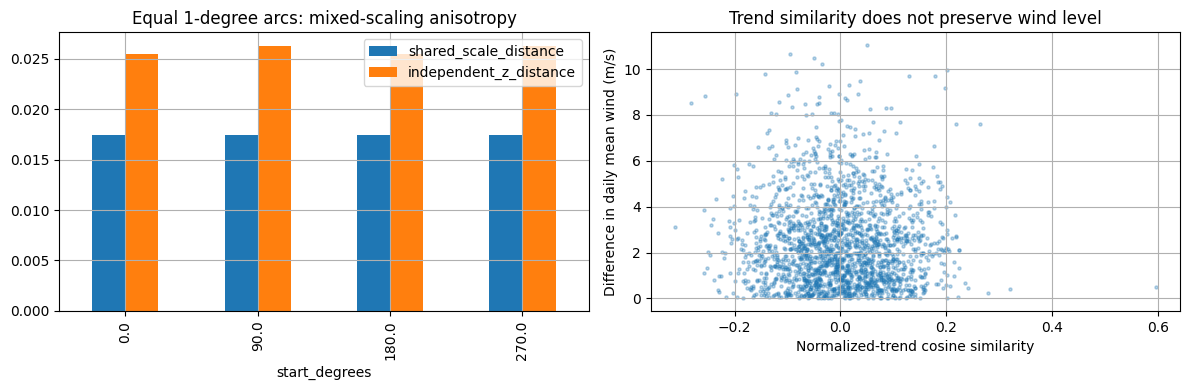

In [25]:
raw_optional=regular[['turbine','timestamp','split']+list(SIGNALS)].copy()
tip_ratio=2*np.pi*46*raw_optional.rotor/(60*raw_optional.wind.where(raw_optional.wind.gt(0)))
tip_stats=pd.DataFrame({'tip_speed_ratio':tip_ratio,'wind':raw_optional.wind,'split':raw_optional.split})
display(tip_stats.groupby('split').tip_speed_ratio.describe(percentiles=[.01,.5,.99]))
tip_stats.to_csv(OUT/'optional_tip_speed_ratio.csv.gz',index=False,compression='gzip')
angles=np.deg2rad(raw_optional.direction)
circle=np.column_stack([np.sin(angles),np.cos(angles)])
fit=raw_optional.split.eq('train').to_numpy()
circle_scale=StandardScaler().fit(circle[fit])
meteorology_scale=MinMaxScaler().fit(raw_optional.loc[fit,['wind','ambient']])
mixed=np.column_stack([meteorology_scale.transform(raw_optional[['wind','ambient']]),circle_scale.transform(circle)])
val=~fit
mixed_summary=pd.DataFrame({'coordinate':['wind_minmax','ambient_minmax','direction_sin_z','direction_cos_z'],
    'validation_variance':np.nanvar(mixed[val],axis=0)})
display(mixed_summary);mixed_summary.to_csv(OUT/'benchmark_mixed_scaling.csv',index=False)
increments=np.deg2rad(np.array([[0,1],[90,91],[180,181],[270,271]],dtype=float))
direction_tests=[]
for a,b in increments:
    coordinates=np.array([[np.sin(a),np.cos(a)],[np.sin(b),np.cos(b)]])
    scaled=circle_scale.transform(coordinates)
    direction_tests.append({'start_degrees':np.rad2deg(a),'same_arc_degrees':1,
        'shared_scale_distance':np.linalg.norm(coordinates[0]-coordinates[1]),
        'independent_z_distance':np.linalg.norm(scaled[0]-scaled[1])})
direction_tests=pd.DataFrame(direction_tests);display(direction_tests)
direction_tests.to_csv(OUT/'benchmark_mixed_circular_anisotropy.csv',index=False)
bounds={'wind':(0,60),'direction':(0,360),'ambient':(-50,200),'bearing':(-50,200),'oil':(-50,200),
    'rotor':(0,np.inf),'generator':(0,np.inf),'frequency':(49,51)}
flags=pd.DataFrame({c:raw_optional[c].lt(low)|raw_optional[c].gt(high) for c,(low,high) in bounds.items()})
expert_loss=pd.DataFrame({'split':raw_optional.split,'remove':flags.any(axis=1),'observed':raw_optional.wind.notna()})
expert_summary=expert_loss[expert_loss.observed].groupby('split').agg(observed_rows=('observed','sum'),removed=('remove','sum'))
expert_summary['removed_fraction']=expert_summary.removed/expert_summary.observed_rows
display(expert_summary);expert_summary.to_csv(OUT/'benchmark_expert_range_removal.csv')
trends=[];trend_meta=[]
for (t,split,day),block in raw_optional.assign(day=raw_optional.timestamp.dt.floor('D')).groupby(['turbine','split','day']):
    wind=block.wind.to_numpy()
    if len(wind)!=144 or not np.isfinite(wind).all():continue
    difference=np.diff(wind);magnitude=np.linalg.norm(difference)
    if magnitude<=1e-12:continue
    trends.append(difference/magnitude);trend_meta.append((t,split,day,wind.mean()))
trends=np.asarray(trends);trend_meta=pd.DataFrame(trend_meta,columns=['turbine','split','day','wind_mean'])
pair=np.random.default_rng(2022).integers(0,len(trends),size=(2000,2))
cosine=(trends[pair[:,0]]*trends[pair[:,1]]).sum(axis=1)
trend_diagnostics=pd.DataFrame({'cosine_similarity':cosine,'mean_wind_difference':np.abs(trend_meta.wind_mean.iloc[pair[:,0]].to_numpy()-trend_meta.wind_mean.iloc[pair[:,1]].to_numpy())})
display(trend_diagnostics.describe());trend_diagnostics.to_csv(OUT/'benchmark_normalized_trend_cosine.csv',index=False)
base=np.arange(10,dtype=float);difference=np.diff(base)
assert np.allclose(difference/np.linalg.norm(difference),np.diff(2*base+100)/np.linalg.norm(np.diff(2*base+100)))
fig,axes=plt.subplots(1,2,figsize=(12,4))
direction_tests.plot.bar(x='start_degrees',y=['shared_scale_distance','independent_z_distance'],ax=axes[0]);axes[0].set_title('Equal 1-degree arcs: mixed-scaling anisotropy')
axes[1].scatter(trend_diagnostics.cosine_similarity,trend_diagnostics.mean_wind_difference,s=5,alpha=.3)
axes[1].set(xlabel='Normalized-trend cosine similarity',ylabel='Difference in daily mean wind (m/s)',title='Trend similarity does not preserve wind level');plt.tight_layout();plt.show()

### Why not choose min–max solely from its distance-balance score?

Global min–max achieves better full-distribution distance balance than StandardScaler in this case; that is a real advantage, not hidden. Choice depends on objective: StandardScaler gives equal training variance per scalar sensor, while min–max gives equal observed range and can suppress routine variation in a channel with rare large excursions. RobustScaler is not automatically safer: narrow pitch IQR amplifies legitimate parked modes. Percentile min–max also exposes large frequency-event excursions in its separate table.

Stress test below is **synthetic**, not an allegation of corrupt 2022 measurements. Add one large training wind value (1,000 training IQR above maximum) and refit; measure how much distance between ordinary 2 and 8 m/s values changes. Global standard scaling is retained as interpretable variance-based compromise, not mathematical optimum or clustering-accuracy winner. Min–max remains defensible if range-based weighting is desired and training extrema are trusted; it must not be selected solely from one internal geometry metric.

,method,original_ordinary_wind_distance,after_single_extreme_distance,retained_distance_fraction
0,standard,2.091987,0.586994,0.280592
1,minmax,0.248403,0.001544,0.006216
2,robust,1.553675,1.553666,0.999994


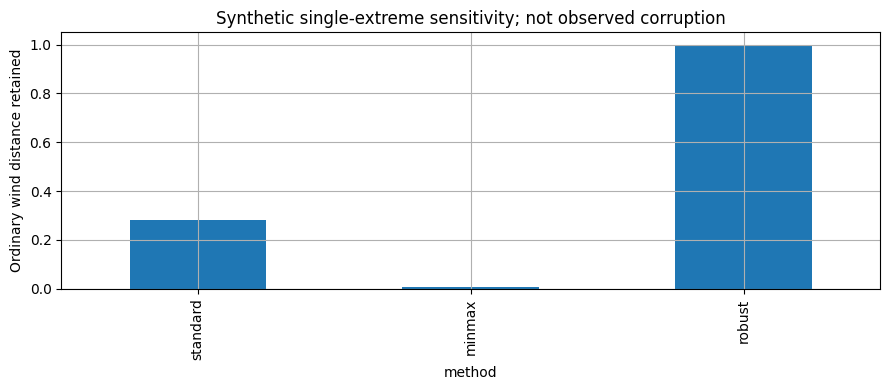

In [26]:
stress_cols=[c for c in SIGNALS if c not in ['direction','setpoint']]
training=raw_optional.loc[raw_optional.split.eq('train'),stress_cols].copy()
training=training.fillna(training.median())
wind_column=stress_cols.index('wind')
modified=training.copy()
wind_iqr=training.wind.quantile(.75)-training.wind.quantile(.25)
modified.iloc[0,wind_column]=training.wind.max()+1000*wind_iqr
probe=np.tile(training.median().to_numpy(),(2,1));probe[:,wind_column]=[2,8]
stress_rows=[]
for name,constructor in [('standard',StandardScaler),('minmax',MinMaxScaler),('robust',RobustScaler)]:
    original_scale=constructor().fit(training.to_numpy())
    changed_scale=constructor().fit(modified.to_numpy())
    before=original_scale.transform(probe);after=changed_scale.transform(probe)
    d_before=abs(before[1,wind_column]-before[0,wind_column]);d_after=abs(after[1,wind_column]-after[0,wind_column])
    stress_rows.append({'method':name,'original_ordinary_wind_distance':d_before,
        'after_single_extreme_distance':d_after,'retained_distance_fraction':d_after/d_before})
scaler_stress=pd.DataFrame(stress_rows);display(scaler_stress)
scaler_stress.to_csv(OUT/'benchmark_scaler_single_extreme_stress.csv',index=False)
fig,ax=plt.subplots(figsize=(9,4));scaler_stress.plot.bar(x='method',y='retained_distance_fraction',ax=ax,legend=False)
ax.set(ylabel='Ordinary wind distance retained',title='Synthetic single-extreme sensitivity; not observed corruption');plt.tight_layout();plt.show()

### Measured recommendation and actual deliverables
Short scalar gaps are filled only for signals passing both 1/2-step validation gates: normalized RMSE ≤0.10, ≥99% fill, and no worse than median or forward fill. Whole runs longer than two steps, leading/trailing runs, direction, and setpoint stay unfilled. No empirical whole-row trimming or winsorization enters final data. Raw readings, missing/fill flags, empirical and physical flags remain exportable; physically flagged scalar observations remain in feature coordinates as flagged context, not alleged faults. Invalid direction outside 0–360° is not circularly encoded. No smoothing enters final features. Robust/standard and window length/completeness are selected by stated measured rules. These thresholds are transparent policy choices, not claims of optimal fault detection.

Final tables include natural missingness, so consumers must honor completeness and quality flags. Statistical window summaries use available scalar model inputs and valid circular coordinates, retaining quality rates. Setpoint stays raw context, never interpolated or included in clustering coordinates. Circular encoding uses shared scales. Exports use CSV.gz (no optional parquet engine), JSON manifest, and local trusted pickle for fitted sklearn scalers/PCA; never load untrusted pickle files.

In [27]:
validation_coverage=window_benchmark[window_benchmark.split.eq('validation')].copy()
eligible=validation_coverage[validation_coverage.coverage.ge(.80)]
if len(eligible):chosen=eligible.sort_values(['hours','threshold'],ascending=[True,False]).iloc[0]
else:chosen=validation_coverage.sort_values(['coverage','hours','threshold'],ascending=[False,True,False]).iloc[0]
selected_hours=int(chosen.hours);selected_completeness=float(chosen.threshold)
final_windows=window_tables[selected_hours].copy()
final_windows=final_windows[final_windows.completeness.ge(selected_completeness)]
# Quality burden summaries include observations excluded from model inputs.
flag_cols=[c for c in final_table if c.startswith(('missing_','filled_','physical_','empirical_'))]
quality_source=final_table[['turbine','timestamp','split']+flag_cols].copy()
quality_source['window_start']=quality_source.timestamp.dt.floor(f'{selected_hours}h')
quality_rates=quality_source.groupby(['turbine','split','window_start'])[flag_cols].mean().add_suffix('__fraction')
final_windows=final_windows.join(quality_rates)
# A second fitted training-only window scaler gives compact fixed-length coordinates.
stat_cols=[c for c in final_windows if '__' in c and not c.endswith('__fraction')]
wt=final_windows.index.get_level_values('split')=='train'
window_medians=final_windows.loc[wt,stat_cols].median()
stat_cols=[c for c in stat_cols if np.isfinite(window_medians[c])]
if not stat_cols or wt.sum()<2:
    raise ValueError('Selected windows have insufficient training observations for export')
window_scaler=(RobustScaler() if selected_scale=='robust' else StandardScaler()).fit(final_windows.loc[wt,stat_cols].fillna(window_medians[stat_cols]))
# Match sin/cos scales for each statistical summary, preserving pair geometry.
for summary in ('mean','std','min','max','endpoint_change'):
    pair_names=[f'direction_sin__{summary}',f'direction_cos__{summary}']
    if all(c in stat_cols for c in pair_names):
        positions=[stat_cols.index(c) for c in pair_names]
        common=float(np.sqrt(np.mean(window_scaler.scale_[positions]**2)))
        window_scaler.scale_[positions]=common if common>0 else 1.
window_coordinates=window_scaler.transform(final_windows[stat_cols].fillna(window_medians[stat_cols]))
# Consolidate columns once rather than fragmenting frame with repeated insertions.
coordinates=pd.DataFrame(window_coordinates,index=final_windows.index,columns=['coordinate__'+c for c in stat_cols])
coordinate_missing=final_windows[stat_cols].isna().rename(columns=lambda c:'coordinate_imputed__'+c)
final_windows=pd.concat([final_windows,coordinates,coordinate_missing],axis=1)
selection={'fit_period':'2022-01-01/2022-06-30 UTC','selection_period':'2022-07-01/2022-12-31 UTC',
    'scalar_scaler':selected_scale,'scalar_features':scale_cols,'gap_fill_signals':fill_allowed,'max_whole_gap_steps':2,
    'direction':'sin/cos, shared unit scale, never scalar interpolated','setpoint':'raw context only, never interpolated',
    'outliers':'retain raw/flags and scalar coordinates; invalid direction unencoded; no empirical row trimming',
    'smoothing':'none','window_hours':selected_hours,'window_completeness':selected_completeness,
    'validation_window_coverage':float(chosen.coverage),'PCA_final':'not applied; preservation diagnostics exported',
    'window_coordinate_missingness':'training-median fill with coordinate_imputed flags',
    'metrics':'data quality and geometric diagnostics, not clustering truth',
    'validation_reuse':'July-December used for selection, no unbiased final test claim'}
display(pd.DataFrame([selection]));display(final_table.head());display(final_windows.head())
trim_loss=outlier_benchmark.query("split == 'validation' and regime == 'all' and method == 'IQR trimming'").loss_fraction.iloc[0]
decision_rows=[
 {'stage':'availability and chronology','decision':'availability=1, UTC regular grid, no duplicate reconciliation needed',
  'evidence':f'{len(df):,}/{len(regular):,} observed timestamps; {audit.valid_duplicate_rows.sum()} valid duplicate rows',
  'reason':'Unavailable export rows are not measurements; missing grid slots remain explicit.'},
 {'stage':'missing data','decision':'bounded complete-run interpolation only for validated scalar channels',
  'evidence':f'Accepted: {fill_allowed}; actual filled cells: {int(final_table.filter(regex="^filled_").sum().sum())}',
  'reason':'Requires <=0.10 train-IQR normalized RMSE at both 1/2 steps and beats median/forward-fill baselines; no long-gap, direction or setpoint filling.'},
 {'stage':'outliers','decision':'retain flagged readings; no empirical row trimming or replacement',
  'evidence':f'Validation IQR trimming would remove {trim_loss:.2%} of grid rows',
  'reason':'Rare parked/curtailed/shared-grid conditions belong to operating-regime analysis; no sensor-fault labels establish removal truth.'},
 {'stage':'scaling','decision':f'global training-fitted {selected_scale} scaler',
  'evidence':f'Largest scalar squared-distance shares: standard {scores.loc["global standard","max_distance_share"]:.3f}, robust {scores.loc["global robust","max_distance_share"]:.3f}',
  'reason':'Global scale preserves between-turbine levels; robust chosen only if full/central geometry and tail diagnostics all improve. Per-window normalization erases levels.'},
 {'stage':'direction','decision':'sin/cos with shared scale',
  'evidence':'359 versus 1 degrees: raw distance 358; circular shortest arc 2 degrees',
  'reason':'No false discontinuity at north; vector averaging for windows, never scalar-degree interpolation.'},
 {'stage':'smoothing and gradients','decision':'no smoothing; levels remain primary',
  'evidence':'Measured transition distortion and difference attenuation in benchmark_smoothing.csv; gradient shift-invariance assertion passes',
  'reason':'Smoother appearance is not cluster validity; gradients/differences discard absolute operating level.'},
 {'stage':'windowing','decision':f'{selected_hours}h, nonoverlap, completeness >= {selected_completeness:.0%}',
  'evidence':f'Validation retention {chosen.coverage:.2%}; final {len(final_windows):,} windows',
  'reason':'Choose finest tested duration reaching >=80% validation retention, then strictest passing completeness; explicit policy, not universal optimum.'},
 {'stage':'representation','decision':'compact named statistical features; no final PCA/DCT/PFA projection',
  'evidence':'PCA reconstruction/distance, DCT error, correlation coverage and two PFA family tables quantify alternative losses',
  'reason':'Interpretability and level preservation matter; extra feature families/compression need downstream benefit before cutover.'}]
decision_table=pd.DataFrame(decision_rows)
display(decision_table)
decision_table.to_csv(OUT/'manual_preprocessing_decision.csv',index=False)
display(Markdown(f'**Chosen pipeline:** availability-filtered UTC 10-minute grid; whole short-gap filling for `{fill_allowed}` only; '
    f'flag-only outliers; `{selected_scale}` global scalar scaling; circular direction; no smoothing; '
    f'`{selected_hours}h` nonoverlap statistical windows at `{selected_completeness:.0%}` completeness. '
    'January–June fit; July–December selection, not untouched test. Retain raw readings and provenance.'))
final_table.to_csv(OUT/'preprocessed_2022.csv.gz',index=False,compression='gzip')
final_windows.reset_index().to_csv(OUT/'windows_2022.csv.gz',index=False,compression='gzip')
for name,table in [('missing',missing_benchmark),('outliers',outlier_benchmark),('scaling',scale_benchmark),
                   ('distance',distance_benchmark),('smoothing',smoothing_benchmark),('windows',window_benchmark),('pca',pca_benchmark)]:
    table.to_csv(OUT/f'benchmark_{name}.csv',index=False)
(OUT/'preprocessing_selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
with (OUT/'fitted_preprocessing.pkl').open('wb') as f:
    pickle.dump({'scalar_scaler':selected_scaler,'scalar_features':scale_cols,
                 'scalar_training_medians':train_median[scale_cols],'window_scaler':window_scaler,
                 'window_features':stat_cols,'window_training_medians':window_medians[stat_cols],
                 'pca_benchmark_models':pca_models,'selection':selection},f)
export_summary=pd.DataFrame([{'artifact':p.name,'bytes':p.stat().st_size} for p in sorted(OUT.glob('*')) if p.is_file()])
display(export_summary)
assert not final_table.loc[final_table.missing_direction,'filled_direction'].any()
assert not final_table.loc[final_table.missing_setpoint,'filled_setpoint'].any()
assert len(final_table)==len(regular) and final_table[['turbine','timestamp']].duplicated().sum()==0

,fit_period,selection_period,scalar_scaler,scalar_features,gap_fill_signals,max_whole_gap_steps,direction,setpoint,outliers,smoothing,window_hours,window_completeness,validation_window_coverage,PCA_final,window_coordinate_missingness,metrics,validation_reuse
0,2022-01-01/2022-06-30 UTC,2022-07-01/2022-12-31 UTC,standard,"[wind, power, reactive, ambient, bearing, oil, rotor, generator, pitch, frequency]",[ambient],2,"sin/cos, shared unit scale, never scalar interpolated","raw context only, never interpolated",retain raw/flags and scalar coordinates; invalid direction unencoded; no empirical row trimming,none,1,1.0,0.994867,not applied; preservation diagnostics exported,training-median fill with coordinate_imputed flags,"data quality and geometric diagnostics, not clustering truth","July-December used for selection, no unbiased final test claim"


,turbine,timestamp,split,observed_row,wind,direction,power,reactive,ambient,bearing,oil,rotor,generator,pitch,frequency,...,filled_pitch,filled_frequency,filled_setpoint,scaled_wind,scaled_power,scaled_reactive,scaled_ambient,scaled_bearing,scaled_oil,scaled_rotor,scaled_generator,scaled_pitch,scaled_frequency,direction_sin,direction_cos
0,KWF1,2022-01-01 00:00:00+00:00,train,True,6.781222,185.795348,630.889598,-190.507286,12.4775,43.3450,55.500,12.356776,1465.081873,0.0000,49.957360,...,False,False,False,0.211427,0.021408,0.165171,0.399393,0.899874,0.531521,0.490405,0.490098,-0.427035,-0.125893,-0.100976,-0.994889
1,KWF1,2022-01-01 00:10:00+00:00,train,True,6.936052,189.458687,809.339449,-235.626105,12.4925,44.4300,54.505,13.323927,1579.914207,0.0000,50.001065,...,False,False,False,0.265411,0.302212,-0.087574,0.402343,1.047878,0.428723,0.698775,0.699057,-0.427035,0.043280,-0.164336,-0.986404
2,KWF1,2022-01-01 00:20:00+00:00,train,True,7.294642,188.648729,893.607333,-222.190602,12.5225,44.8800,53.725,13.579383,1609.909721,0.0470,50.096420,...,False,False,False,0.390438,0.434813,-0.012311,0.408242,1.109262,0.348138,0.753812,0.753639,-0.425025,0.412375,-0.150376,-0.988629
3,KWF1,2022-01-01 00:30:00+00:00,train,True,8.080467,188.826550,995.583734,-240.734678,12.5700,43.2525,53.185,14.218120,1683.816776,0.0065,49.920895,...,False,False,False,0.664427,0.595281,-0.116191,0.417582,0.887256,0.292349,0.891426,0.888127,-0.426757,-0.267040,-0.153444,-0.988157
4,KWF1,2022-01-01 00:40:00+00:00,train,True,7.021328,191.252213,926.519441,-287.214456,12.5925,39.8250,54.470,13.875010,1643.165131,0.0060,49.926266,...,False,False,False,0.295143,0.486603,-0.376559,0.422007,0.419714,0.425107,0.817504,0.814153,-0.426778,-0.246250,-0.195128,-0.980778


wind__mean  wind__std  wind__min  \
turbine split window_start                                                  
KWF1    train 2022-01-01 00:00:00+00:00    7.269199   0.473985   6.781222   
              2022-01-01 01:00:00+00:00    7.180542   0.803719   6.206490   
              2022-01-01 02:00:00+00:00    7.924514   0.651077   6.832882   
              2022-01-01 03:00:00+00:00    7.761178   0.689225   6.715919   
              2022-01-01 04:00:00+00:00    8.062870   0.963500   7.047761   

                                         wind__max  power__mean  power__std  \
turbine split window_start                                                    
KWF1    train 2022-01-01 00:00:00+00:00   8.080467   868.619661  132.456044   
              2022-01-01 01:00:00+00:00   8.450919   852.641219  280.633585   
              2022-01-01 02:00:00+00:00   8.650076  1104.675791  192.093267   
              2022-01-01 03:00:00+00:00   8.808489  1090.165807  250.459016   
              2022-01-01 04:00:00+00:00   9.469054  1213.768762  443.116281   

                                         power__min   power__max  \
turbine split window_start                                         
KWF1    train 2022-01-01 00:00:00+00:00  630.889598   995.583734   
              2022-01-01 01:00:00+00:00  570.319664  1337.580353   
              2022-01-01 02:00:00+00:00  797.881812  1291.248279   
              2022-01-01 03:00:00+00:00  761.968607  1499.330646   
              2022-01-01 04:00:00+00:00  773.963527  1776.165167   

                                         reactive__mean  reactive__std  \
turbine split window_start                                               
KWF1    train 2022-01-01 00:00:00+00:00     -247.296401      43.018872   
              2022-01-01 01:00:00+00:00     -293.765532      70.546413   
              2022-01-01 02:00:00+00:00     -361.562201      43.844193   
              2022-01-01 03:00:00+00:00     -336.672586      31.571033   
              2022-01-01 04:00:00+00:00     -388.694940      86.436076   

                                         reactive__min  reactive__max  \
turbine split window_start                                              
KWF1    train 2022-01-01 00:00:00+00:00    -307.505276    -190.507286   
              2022-01-01 01:00:00+00:00    -412.660483    -215.033787   
              2022-01-01 02:00:00+00:00    -403.666199    -302.870429   
              2022-01-01 03:00:00+00:00    -386.626199    -298.969780   
              2022-01-01 04:00:00+00:00    -496.307855    -295.756819   

                                         ambient__mean  ambient__std  \
turbine split window_start                                             
KWF1    train 2022-01-01 00:00:00+00:00      12.563333      0.090646   
              2022-01-01 01:00:00+00:00      12.990000      0.114935   
              2022-01-01 02:00:00+00:00      13.194167      0.116347   
              2022-01-01 03:00:00+00:00      13.194759      0.112262   
              2022-01-01 04:00:00+00:00      12.830417      0.063016   

                                         ambient__min  ...  \
turbine split window_start                             ...   
KWF1    train 2022-01-01 00:00:00+00:00     12.477500  ...   
              2022-01-01 01:00:00+00:00     12.820000  ...   
              2022-01-01 02:00:00+00:00     13.085000  ...   
              2022-01-01 03:00:00+00:00     13.021053  ...   
              2022-01-01 04:00:00+00:00     12.740000  ...   

                                         coordinate_imputed__direction_cos__std  \
turbine split window_start                                                        
KWF1    train 2022-01-01 00:00:00+00:00                                   False   
              2022-01-01 01:00:00+00:00                                   False   
              2022-01-01 02:00:00+00:00                                   False   
              2022-01-01 03:00:00+00:00                                   False   
 

,stage,decision,evidence,reason
0,availability and chronology,"availability=1, UTC regular grid, no duplicate reconciliation needed","314,018/315,360 observed timestamps; 0 valid duplicate rows",Unavailable export rows are not measurements; missing grid slots remain explicit.
1,missing data,bounded complete-run interpolation only for validated scalar channels,Accepted: ['ambient']; actual filled cells: 19,Requires <=0.10 train-IQR normalized RMSE at both 1/2 steps and beats median/forward-fill baseli...
2,outliers,retain flagged readings; no empirical row trimming or replacement,Validation IQR trimming would remove 22.56% of grid rows,Rare parked/curtailed/shared-grid conditions belong to operating-regime analysis; no sensor-faul...
3,scaling,global training-fitted standard scaler,"Largest scalar squared-distance shares: standard 0.449, robust 0.617",Global scale preserves between-turbine levels; robust chosen only if full/central geometry and t...
4,direction,sin/cos with shared scale,359 versus 1 degrees: raw distance 358; circular shortest arc 2 degrees,"No false discontinuity at north; vector averaging for windows, never scalar-degree interpolation."
5,smoothing and gradients,no smoothing; levels remain primary,Measured transition distortion and difference attenuation in benchmark_smoothing.csv; gradient s...,Smoother appearance is not cluster validity; gradients/differences discard absolute operating le...
6,windowing,"1h, nonoverlap, completeness >= 100%","Validation retention 99.49%; final 52,241 windows","Choose finest tested duration reaching >=80% validation retention, then strictest passing comple..."
7,representation,compact named statistical features; no final PCA/DCT/PFA projection,"PCA reconstruction/distance, DCT error, correlation coverage and two PFA family tables quantify ...",Interpretability and level preservation matter; extra feature families/compression need downstre...


**Chosen pipeline:** availability-filtered UTC 10-minute grid; whole short-gap filling for `['ambient']` only; flag-only outliers; `standard` global scalar scaling; circular direction; no smoothing; `1h` nonoverlap statistical windows at `100%` completeness. January–June fit; July–December selection, not untouched test. Retain raw readings and provenance.

,artifact,bytes
0,auxiliary_full_schema.csv,2
1,auxiliary_header_inventory.csv,2
2,benchmark_correlation_gates.csv,653
3,benchmark_dbscan.csv,361
4,benchmark_dct.csv,773
...,...,...
67,tsfresh_comprehensive_sample.csv.gz,6638604
68,tsfresh_extraction_summary.json,370
69,tsfresh_pfa_feature_names.json,3127
70,tsfresh_sequence_metadata.csv,5250


### Literature coverage ledger: executed primitives versus nontransferable steps
Every reported preprocessing item gets an explicit coverage disposition. Keyword-based mapping below is a transparent navigation aid, not semantic proof of replication. Compound statements retain their full source text and can map to multiple executed families. Learned embeddings/model stages and domain-specific representations are marked nontransferable rather than silently replaced with numeric SCADA columns. Unmatched source text stays **not replicated** and needs source-specific transfer design. Unreported methods stay unreported: absence is never inferred to mean deletion, standardization or another default.

In [28]:
display(Markdown('Literature coverage audit is pending original papers.json/full texts. No PRISMA or replication claim is made.'))

Literature coverage audit is pending original papers.json/full texts. No PRISMA or replication claim is made.

## Interpretation limits and next-stage contract

Benchmarks evaluate preprocessing fidelity and coverage, **not** correctness of latent operating-regime clusters. Artificial missingness has known targets; natural missingness does not. Random synthetic gaps do not identify missing-not-at-random outages. Robustness, PCA variance, and silhouette-like geometry cannot establish fault detection accuracy. No event-based labels were used to select parameters.

Retain raw physical-unit columns, timestamps, turbine identity, availability/observation and imputation flags separately from model features. Fit transformations only on chronological fitting partition. Keep long missing intervals missing; never interpolate scalar degrees across north, never interpolate setpoint changes, never join independent turbines into continuous sequence. Event and site-meter data remain post-analysis context. Power-curve trimming would answer a different normal-performance question, so it is not default for operating-regime discovery.

Before clustering, inspect exported feature names and correlated families; evaluate sensitivity to window length and scaling, then use internal cluster metrics together with temporal stability and physical interpretation. No preprocessing choice here constitutes supervised validation. Literature page evidence and measured comparison tables above support manual decision, without inventing a single universal numerical ranking.

In [29]:
import importlib.metadata as metadata
versions={name:metadata.version(name) for name in ['numpy','pandas','matplotlib','scipy','scikit-learn','nbformat','nbclient','tsfresh']}
(OUT/'environment.json').write_text(json.dumps(versions,indent=2),encoding='utf-8')
display(versions)
print('Notebook completed; output directory:', OUT)


{'numpy': '2.5.4',
 'pandas': '3.0.6',
 'matplotlib': '3.10.9',
 'scipy': '1.18.1',
 'scikit-learn': '1.9.1',
 'nbformat': '5.11.1',
 'nbclient': '0.11.0',
 'tsfresh': '0.21.2'}

Notebook completed; output directory: C:\College\Sem5\DATMIN\Kelmarsh_SCADA_2022_4457\artifacts\kelmarsh_2022


In [30]:
assert len(df)==314018 and len(regular)==315360
assert fill_allowed==['ambient'] and selected_scale=='standard'
assert selected_hours==1 and selected_completeness==1.0
assert int(final_table.filter(regex='^filled_').sum().sum())==19
assert len(final_windows)==52241
assert len([c for c in final_windows if c.startswith('coordinate__')])==60
assert np.isfinite(final_windows.filter(regex='^coordinate__').to_numpy()).all()
print('Frozen preprocessing consistency checks passed: 52241 windows, 60 coordinates, 19 ambient fills.')


Frozen preprocessing consistency checks passed: 52241 windows, 60 coordinates, 19 ambient fills.
